# Popular or Powerful? Card and Deck Performance in High-Trophy Clash Royale, Nov 2022 – Mar 2023

*A descriptive big-data analysis of 191 million battles with Apache Spark*

## Abstract

**Context.** In Clash Royale, a real-time strategy game, players fight one-on-one
with eight-card decks built from their own card collection. Players, content
creators and the developer's balance team judge the "meta" mainly through
leaderboards of popular cards and decks.

**Problem.** We ask whether the cards and decks that high-trophy players pick most
often are also the ones that win most broadly. The alternatives are that one-trick
specialists, short-lived trends, or small samples distort the leaderboards.

**Methodology.** The input is 38 GB of raw battle logs: 149 daily CSV files with
193.9 M rows across five consecutive seasons. A resumable Apache Spark pipeline:
* validates and deduplicates the logs into 191.1 M unique battles;
* keeps player-built-deck modes where both players are above a season-specific
  75th-percentile trophy threshold (12.3 M battles);
* makes decks order-invariant and groups near-identical decks into families;
* computes pick rates, non-mirror win rates with Empirical-Bayes shrinkage,
  match- vs player-weighted win rates, crown margins and cross-season rank
  correlations.

**Results.** Popularity is only weakly tied to winning: Spearman ρ = 0.11 between
card pick rate and smoothed win rate, and 0.13 for decks. The most-picked card,
The Log (36% of decks), wins 49.5% of its non-mirror games. Raw win-rate
leaderboards are dominated by small samples: the top-20 decks have a median of 62
matches and fall to a median rank of 90 after shrinkage. Large gaps between
match- and player-weighted win rates occur only in small player pools; no deck
with more than 1,000 pilots has one. Card usage is persistent across
seasons (adjacent ρ 0.81–0.98), but November → December 2022 is a clear break, with
Monk's pick rate falling from 14.8% to 2.3%.

**Recommendation.** Rank cards and decks by shrunken, mirror-excluded win rates with
a visible breadth indicator, never by raw win rate or pick rate alone. Set
"high-skill" cohorts with season-relative thresholds, because absolute trophy
cut-offs drift as trophies inflate.

## Table of contents

1. Introduction: context, problem statement, motivation
2. Data source and description
3. Methodology overview (Figure 1)
4. Environment and design constraints
5. Data ingestion, exploration and null-value handling
6. Data filtering
7. Player observations, deck canonicalisation and deck families
8. Performance metrics
9. Cross-season dynamics
10. Results and discussion (Figures 3–7)
11. Sensitivity analysis: alternative design assumptions
12. Conclusion
13. Limitations and recommendations
14. References
15. Appendix: deliverable audit

Validation checks A–F are `assert` statements placed where each stage finishes. If
any check fails, the notebook stops.

## 1. Introduction

### 1.1 Context
Clash Royale, released by Supercell in 2016, is a mobile real-time strategy game.
Each battle is a three-minute (plus overtime) one-on-one duel. Each player brings
a deck of exactly eight cards from more than 100 available, and the winner is the player who
destroys more of the opponent's three towers ("crowns"). Players climb the
*Trophy Road* ladder by winning. Supercell rebalances cards regularly, often around
the monthly season reset. Players and the community use popularity and win-rate
tables to decide what to play, and balance teams use them to decide what to change
(RoyaleAPI, n.d.).

### 1.2 Problem statement
> **Do the cards and decks that high-trophy players pick most often also win the
> most, across many players and across seasons?**

### 1.3 Motivation
* **Leaderboards drive behaviour.** Popularity and win-rate tables shape what
  millions of players copy.
* **Several known effects can mislead these tables:**
  * **Mirror matches.** A popular card often faces itself, and those games are
    always a coin flip for the card, so its win rate is pulled toward 50%.
  * **Small samples.** A deck seen 60 times can show a 70% win rate by chance.
  * **Specialists.** A deck that wins only in the hands of a few dedicated
    players looks strong overall but is not broadly strong.
  * **Trophy inflation.** Because trophy levels rise over time, a fixed
    "high-trophy" cut-off selects a different population every month.
* **What this study adds.** Measuring how large these effects are, on a sample big
  enough to resolve individual decks (191 M battles), tells players, analysts and
  game designers which tables to trust.
* **Beyond the game.** The same issues appear wherever popularity is read as
  quality: product ratings, app-store rankings and A/B-test dashboards.

## 2. Data source and description

### 2.1 Provenance and collection
* **Source.** The data is the *Clash Royale Battles (481M matches)* dataset
  (S1M0N38, n.d.-a), mirrored read-only on the Jojie cluster at
  `/mnt/data/public/clash-royale-games`.
* **API.** According to the author's collection code (S1M0N38, n.d.-b), battles
  were pulled from the **official Clash Royale API** (Supercell, n.d.).
* **Sampling.** The collector ran a **snowball crawl**:
  * it starts from a few top-ladder "root" players;
  * it downloads each player's recent battle log, which the API limits to the
    last 25 battles;
  * it then queues those battles' opponents and repeats.

  The author's rationale is that matchmaking pairs players of similar strength,
  so the crawl stays near the top of the ladder.
* **Schedule and deduplication.** The crawler ran hourly. Each day's battles were
  joined into one file per day, with redundant copies removed. Within a run,
  each battle is stored with the player whose tag sorts higher first.
* **What this means for interpretation:**
  * the sample is **biased toward active, high-ranked players**, which suits the
    high-trophy focus of this study;
  * it is **not a random sample** of all players;
  * players who play many games are over-represented, a limitation revisited in
    Section 13.

### 2.2 Layout and scope
* **Layout.** `<root>/<season>/<season>/<YYYYMMDD>.csv`: one headerless CSV per
  day and one folder per season.
* **Columns.** Each row is one battle with 24 columns (Table 1).
* **Scope.** The study uses the five consecutive seasons **8 Nov 2022 – 3 Apr
  2023**: 149 files, **38 GB** (16–50 GB required; see the `du -sch` capture
  below). The other nine season folders on Jojie are out of scope.

**Table 1. Raw battle-log schema (one row per battle).**

| # | Column | Type | Meaning |
|---|---|---|---|
| 1 | `battle_timestamp` | string `yyyyMMddTHHmmss.SSSZ` | battle start (UTC) |
| 2 | `game_mode_id` | int | Supercell game-mode ID (Table 5) |
| 3 | `p1_tag` | string | player-1 tag (pseudonymous ID) |
| 4 | `p1_trophies` | int | player-1 starting trophies (ladder) or league points (Path of Legends) |
| 5 | `p1_crowns` | int | towers destroyed by player 1 (0–3) |
| 6–13 | `p1_c1` … `p1_c8` | int | player-1 deck: eight card IDs |
| 14–24 | `p2_*` | – | the same eleven fields for player 2 |

The reference table `cards.json` maps card IDs to names, elixir cost, type and
rarity (RoyaleAPI, n.d.). It is cached under `ref/` so runs are reproducible.
Game-mode names come from RoyaleAPI's `game_modes.json`.

In [1]:
# Size of the raw input actually analysed (the five in-scope season folders)
import subprocess

RAW_ROOT = "/mnt/data/public/clash-royale-games"
SEASON_FOLDERS = ["20221108-20221205", "20221206-20230102",
                  "20230103-20230206", "20230206-20230306",
                  "20230306-20230403"]
du_result = subprocess.run(["du", "-sch", *SEASON_FOLDERS], cwd=RAW_ROOT,
                           capture_output=True, text=True, check=True)
DU_TEXT = (f"$ cd {RAW_ROOT}\n$ du -sch " + " ".join(SEASON_FOLDERS)
           + "\n" + du_result.stdout)
print(DU_TEXT)

$ cd /mnt/data/public/clash-royale-games
$ du -sch 20221108-20221205 20221206-20230102 20230103-20230206 20230206-20230306 20230306-20230403
6.4G	20221108-20221205
7.7G	20221206-20230102
8.7G	20230103-20230206
7.4G	20230206-20230306
7.2G	20230306-20230403
38G	total



## 3. Methodology overview

The pipeline has eight stages (Figure 1). Each stage is specific to this problem:

1. **Ingest.** Read the 149 CSVs with an explicit schema and convert them to
   columnar Parquet, partitioned by season.
2. **Validate and deduplicate.** Apply validity rules. Assign each battle to the
   season of its *date*, since two days are stored in two season folders. Remove
   exact and swapped-perspective duplicates.
3. **Filter.** Keep competitive modes with player-built decks, then keep battles
   where *both* players are at or above that season's 75th-percentile ladder
   trophies, τ_s.
4. **Unpivot.** Turn each battle into two player observations (deck, opponent's
   deck, win/loss, crown margin).
5. **Canonicalise decks.** Sort the eight card IDs so the deck ID ignores slot
   order. Group decks sharing seven of eight cards into families.
6. **Compute metrics** for cards, decks and families:
   * pick rate;
   * non-mirror win rate;
   * Empirical-Bayes win rate;
   * match- vs player-weighted win rate (specialist gap);
   * crown-margin profile.
7. **Compare seasons.** Spearman rank correlations between seasons, rank shifts,
   card trajectory categories and weekly series for three focus cards.
8. **Report.** Figures, tables, a sensitivity analysis and an audit of the
   deliverables.

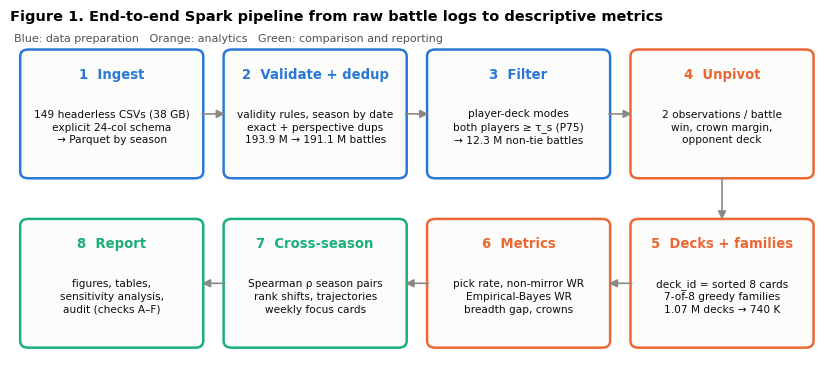

In [2]:
# Figure 1: pipeline diagram (drawn with matplotlib so the notebook is
# self-contained). The environment cell below defines the styling constants;
# this cell only needs matplotlib.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

STAGES = [
    ("1  Ingest", "149 headerless CSVs (38 GB)\nexplicit 24-col schema\n"
     "→ Parquet by season"),
    ("2  Validate + dedup", "validity rules, season by date\n"
     "exact + perspective dups\n193.9 M → 191.1 M battles"),
    ("3  Filter", "player-deck modes\nboth players ≥ τ_s (P75)\n"
     "→ 12.3 M non-tie battles"),
    ("4  Unpivot", "2 observations / battle\nwin, crown margin,\n"
     "opponent deck"),
    ("5  Decks + families", "deck_id = sorted 8 cards\n"
     "7-of-8 greedy families\n1.07 M decks → 740 K"),
    ("6  Metrics", "pick rate, non-mirror WR\nEmpirical-Bayes WR\n"
     "breadth gap, crowns"),
    ("7  Cross-season", "Spearman ρ season pairs\nrank shifts, trajectories\n"
     "weekly focus cards"),
    ("8  Report", "figures, tables,\nsensitivity analysis,\n"
     "audit (checks A–F)"),
]


def draw_pipeline(stages):
    """Draw the pipeline as two rows of four boxes joined by arrows."""
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 2)
    ax.axis("off")
    box_w, box_h = 0.86, 0.72
    centres = [(0.5 + i, 1.5) for i in range(4)]
    centres += [(3.5 - i, 0.5) for i in range(4)]   # serpentine layout
    for i, ((title, body), (x, y)) in enumerate(zip(stages, centres)):
        colour = "#2a78d6" if i < 3 else ("#eb6834" if i < 6 else "#1baf7a")
        ax.add_patch(FancyBboxPatch(
            (x - box_w / 2, y - box_h / 2), box_w, box_h,
            boxstyle="round,pad=0.02,rounding_size=0.04",
            facecolor="#fcfcfb", edgecolor=colour, linewidth=1.8))
        ax.text(x, y + 0.23, title, ha="center", va="center", fontsize=9.5,
                fontweight="semibold", color=colour)
        ax.text(x, y - 0.08, body, ha="center", va="center", fontsize=7.6,
                color="#0b0b0b", linespacing=1.35)
    for (x0, y0), (x1, y1) in zip(centres[:-1], centres[1:]):
        if y0 == y1:   # horizontal arrow between neighbours in a row
            sign = 1 if x1 > x0 else -1
            start = (x0 + sign * box_w / 2, y0)
            end = (x1 - sign * box_w / 2, y1)
        else:          # vertical arrow from row 1 down to row 2
            start, end = (x0, y0 - box_h / 2), (x1, y1 + box_h / 2)
        ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                                     mutation_scale=12, color="#8a8984",
                                     linewidth=1.2))
    ax.text(0.02, 1.97, "Blue: data preparation   Orange: analytics   "
            "Green: comparison and reporting", fontsize=8, color="#52514e",
            va="top")
    ax.set_title("Figure 1. End-to-end Spark pipeline from raw battle logs to "
                 "descriptive metrics", loc="left", fontsize=10.5,
                 fontweight="semibold")
    return fig


pipeline_fig = draw_pipeline(STAGES)   # shown inline; saved in Section 4

**Figure 1.** The analysis pipeline. Stages 1–3 (blue) turn 38 GB of raw logs into
a validated, deduplicated, high-trophy sample. Stages 4–6 (orange) compute
per-player observations and metrics. Stages 7–8 (green) compare seasons and
produce the deliverables. Each stage saves its output as Parquet, so an
interrupted run resumes where it stopped.

## 4. Environment and design constraints

**Compute.** Resources are read from the container's cgroup limits (Linux Kernel
Documentation, n.d.), not from `nproc` or `free`.
* On Jojie, `nproc` and `free` report the whole host: 32 cores and about 220 GB.
  This container is limited to **4 CPUs and 16 GiB**.
* Spark therefore runs as `local[<CPU quota>]`, with a JVM heap of about half the
  memory limit. The rest is left for off-heap memory, the Python kernel and pandas.
* A naive `local[*]` with a 100 GB+ driver would launch 32 tasks on 4 cores
  inside a heap larger than the container, and the kernel would kill it for
  running out of memory.

**Design choices and the Spark concepts they apply** (Zaharia et al., 2016;
Armbrust et al., 2015):

| Constraint | Design choice | Spark concept |
|---|---|---|
| 38 GB of CSV, 16 GiB RAM | one map-only pass CSV → Parquet; nothing large cached | narrow transformations, columnar storage, projection pushdown |
| Deduplication needs a shuffle | one season at a time (~1/5 of the data per shuffle) | wide transformations, partition pruning on `season_id` |
| Runs can be interrupted | every heavy stage writes Parquet plus a `_SUCCESS` marker, skipped on re-run | lineage truncation by materialisation |
| Small lookup tables (cards, τ_s) | broadcast joins | broadcast hash join instead of shuffle join |
| Uneven partition sizes after filters | adaptive query execution, 200 shuffle partitions | AQE partition coalescing |
| Driver memory | `toPandas()` only on aggregated results (≤ ~130 K rows), via Arrow | avoid `collect` on raw data |

Methods beyond the lectures include:
* Empirical-Bayes shrinkage (Efron & Morris, 1975; Casella, 1985);
* xxHash64 battle identifiers (Collet, n.d.);
* a union-find comparison of deck-family clustering rules;
* cgroup-aware resource sizing.

All figures are drawn with Matplotlib (Hunter, 2007) and saved at 300 DPI.

Set `CR_REBUILD=1` to recompute every stage, or `CR_SMOKE=1` for a quick test on
seven files.

In [3]:
# Imports, configuration, Spark session and helper functions
import glob
import json
import math
import os
import textwrap
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.text
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from scipy import stats

START_TIME = time.time()
PROJECT_DIR = (Path.cwd().parent if Path.cwd().name == "outputs"
               else Path.cwd())
SMOKE = os.environ.get("CR_SMOKE", "0") == "1"
OUT = PROJECT_DIR / ("outputs_smoke" if SMOKE else "outputs")
OUT.mkdir(exist_ok=True)
SCRATCH = OUT / "_interim"          # persistent intermediate Parquet
SCRATCH.mkdir(exist_ok=True)
SHUFFLE_DIR = Path(os.environ.get("CR_SHUFFLE_DIR", "/tmp/spark-cr/local"))
SHUFFLE_DIR.mkdir(parents=True, exist_ok=True)   # node-local shuffle spill
REBUILD = os.environ.get("CR_REBUILD", "0") == "1"


def done(path):
    """Return True if a stage output has a `_SUCCESS` marker (reusable)."""
    return (Path(path) / "_SUCCESS").exists() and not REBUILD


def cgroup_limits():
    """Return the container's (CPU quota, memory limit bytes) from cgroup v2.

    Falls back to the host CPU count and no memory limit if the cgroup files
    are absent (e.g. when running outside a container).
    """
    cpus, mem_bytes = os.cpu_count(), None
    try:
        quota, period = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if quota != "max":
            cpus = max(1, int(int(quota) / int(period)))
    except (OSError, ValueError):
        pass
    try:
        mem = Path("/sys/fs/cgroup/memory.max").read_text().strip()
        mem_bytes = None if mem == "max" else int(mem)
    except (OSError, ValueError):
        pass
    return cpus, mem_bytes


CPUS, MEM_LIMIT = cgroup_limits()
# JVM heap = 50% of the limit: room for off-heap, the Python kernel, pandas
DEFAULT_HEAP_GB = max(4, int((MEM_LIMIT or 64 * 2**30) * 0.5 / 2**30))
DRIVER_GB = int(os.environ.get("CR_DRIVER_GB", DEFAULT_HEAP_GB))
mem_gib = MEM_LIMIT / 2**30 if MEM_LIMIT else float("nan")
print(f"container: {CPUS} CPUs, memory limit {mem_gib:.0f} GiB "
      f"-> driver heap {DRIVER_GB}g")

# Seasons: id -> (folder, first battle date, last battle date), UTC inclusive
SEASONS = {
    "S01": ("20221108-20221205", "2022-11-08", "2022-12-05"),
    "S02": ("20221206-20230102", "2022-12-06", "2023-01-02"),
    "S03": ("20230103-20230206", "2023-01-03", "2023-02-05"),
    "S04": ("20230206-20230306", "2023-02-06", "2023-03-05"),
    "S05": ("20230306-20230403", "2023-03-06", "2023-04-03"),
}
SEASON_IDS = list(SEASONS)
SEASON_LABEL = {"S01": "Nov 2022", "S02": "Dec 2022", "S03": "Jan 2023",
                "S04": "Feb 2023", "S05": "Mar 2023"}

# Game-mode names and deck-selection rule from RoyaleAPI game_modes.json
MODE_NAMES = {72000006: "Ladder", 72000044: "Ladder_GoldRush",
              72000066: "Showdown_Ladder", 72000201: "Ladder_CrownRush",
              72000323: "Ranked1v1 (Path of Legends)",
              72000327: "Ranked1v1_GoldRush", 72000328: "Ranked1v1_CrownRush",
              72000291: "Challenge_AllCards_EventDeck",
              72000007: "Friendly", 72000009: "Tournament"}
# Competitive matchmade modes where players bring their own deck
COLLECTION_MODES = [72000006, 72000044, 72000066, 72000323, 72000327]
CROWN_RUSH_MODES = [72000201, 72000328]   # own deck, but altered win rule
LADDER_MODES = [72000006, 72000044]       # used to profile tau_s

TAU_QUANTILE = 0.75        # tau_s = P75 of the season's ladder trophies
EB_MIN_N = 100             # entities with >= 100 matches fit the Beta prior
EB_FALLBACK_M = 200        # prior strength if the moment fit is degenerate
MIN_PLAYER_GAMES = 5       # player-weighted WR: players with >= 5 games
LEADERBOARD_MIN_OBS = 50   # decks kept in deck_leaderboard.parquet
CLASS_MIN_MATCHES = 200    # decks eligible for breadth classification ...
CLASS_MIN_PLAYERS = 10     # ... and with >= 10 qualifying players
SPEC_GAP = 0.03            # specialist-gap threshold (+3.0 pp)
FAMILY_SEED_MIN_OBS = 20   # decks with >= 20 obs form family heads
FOCUS_CARDS = {26000087: "Phoenix", 26000077: "Monk", 28000002: "Rage"}

# Colour palette (colour-blind-safe categorical slots; blue ordinal ramp)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURF = ("#0b0b0b", "#52514e", "#8a8984",
                                "#e4e3df", "#fcfcfb")
RAMP = {"250": "#86b6ef", "400": "#3987e5", "600": "#184f95"}
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF,
    "savefig.facecolor": SURF, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10.5,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

spark = (
    SparkSession.builder.appName("clash-royale-descriptive")
    .master(f"local[{CPUS}]")
    .config("spark.driver.memory", f"{DRIVER_GB}g")
    .config("spark.driver.maxResultSize", f"{max(1, DRIVER_GB // 4)}g")
    .config("spark.sql.shuffle.partitions", 200)
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.sql.files.maxPartitionBytes", str(64 * 2**20))
    .config("spark.memory.fraction", "0.6")
    .config("spark.sql.autoBroadcastJoinThreshold", str(32 * 2**20))
    .config("spark.local.dir", str(SHUFFLE_DIR))
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} | parallelism "
      f"{spark.sparkContext.defaultParallelism} | output "
      f"./{OUT.relative_to(PROJECT_DIR)} | rebuild {REBUILD}")


def to_pandas(sdf):
    """Collect a (small, aggregated) Spark DataFrame to pandas via Arrow."""
    return sdf.toPandas()


def save_table(pdf, name):
    """Write a pandas DataFrame to ./outputs/<name> as Parquet."""
    path = OUT / name
    pdf.to_parquet(path, index=False)
    return path


def cached_table(name, build):
    """Return a small pandas table cached in `_interim`, building it once.

    `build` is a zero-argument function returning a pandas DataFrame. The
    result is reused on later runs unless `CR_REBUILD=1`.
    """
    path = SCRATCH / f"{name}.parquet"
    if path.exists() and not REBUILD:
        return pd.read_parquet(path)
    table = build()
    table.to_parquet(path, index=False)
    return table


def show_figure(fig, filename, width=900):
    """Save a figure at 300 DPI to ./outputs and display the saved PNG."""
    path = OUT / filename
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=width))


def declutter(ax, texts, step=2.0, iters=150, max_shift=28):
    """Nudge annotation labels vertically until their boxes stop overlapping.

    Only the text box is measured (an Annotation's own extent includes its
    leader line), and each label moves at most `max_shift` points.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for _ in range(iters):
        boxes = [matplotlib.text.Text.get_window_extent(t, renderer)
                 .expanded(1.04, 1.12) for t in texts]
        moved = False
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                if not boxes[i].overlaps(boxes[j]):
                    continue
                low, high = (i, j) if boxes[i].y0 <= boxes[j].y0 else (j, i)
                for k, delta in ((low, -step), (high, step)):
                    x_off, y_off = texts[k].xyann
                    y_new = float(np.clip(y_off + delta, -max_shift,
                                          max_shift))
                    texts[k].xyann = (x_off, y_new)
                moved = True
        if not moved:
            break
        fig.canvas.draw()


def caption(number, text):
    """Print a self-contained, wrapped table caption ("Table N. ...")."""
    print(textwrap.fill(f"Table {number}. {text}", width=100))


def pct(value, decimals=1):
    """Format a fraction as a percentage string."""
    return f"{value:.{decimals}%}"


pipeline_fig.savefig(OUT / "fig1_pipeline_overview.png")   # 300 DPI copy
plt.close(pipeline_fig)

container: 4 CPUs, memory limit 16 GiB -> driver heap 8g


Spark 4.1.1 | parallelism 4 | output ./outputs | rebuild False


### 4.1 du -sch capture of the raw input
The capture below is rendered from the `du -sch` output produced at the start of
this notebook (Section 2). It confirms the raw input is 38 GB, inside the
required 16–50 GB range.

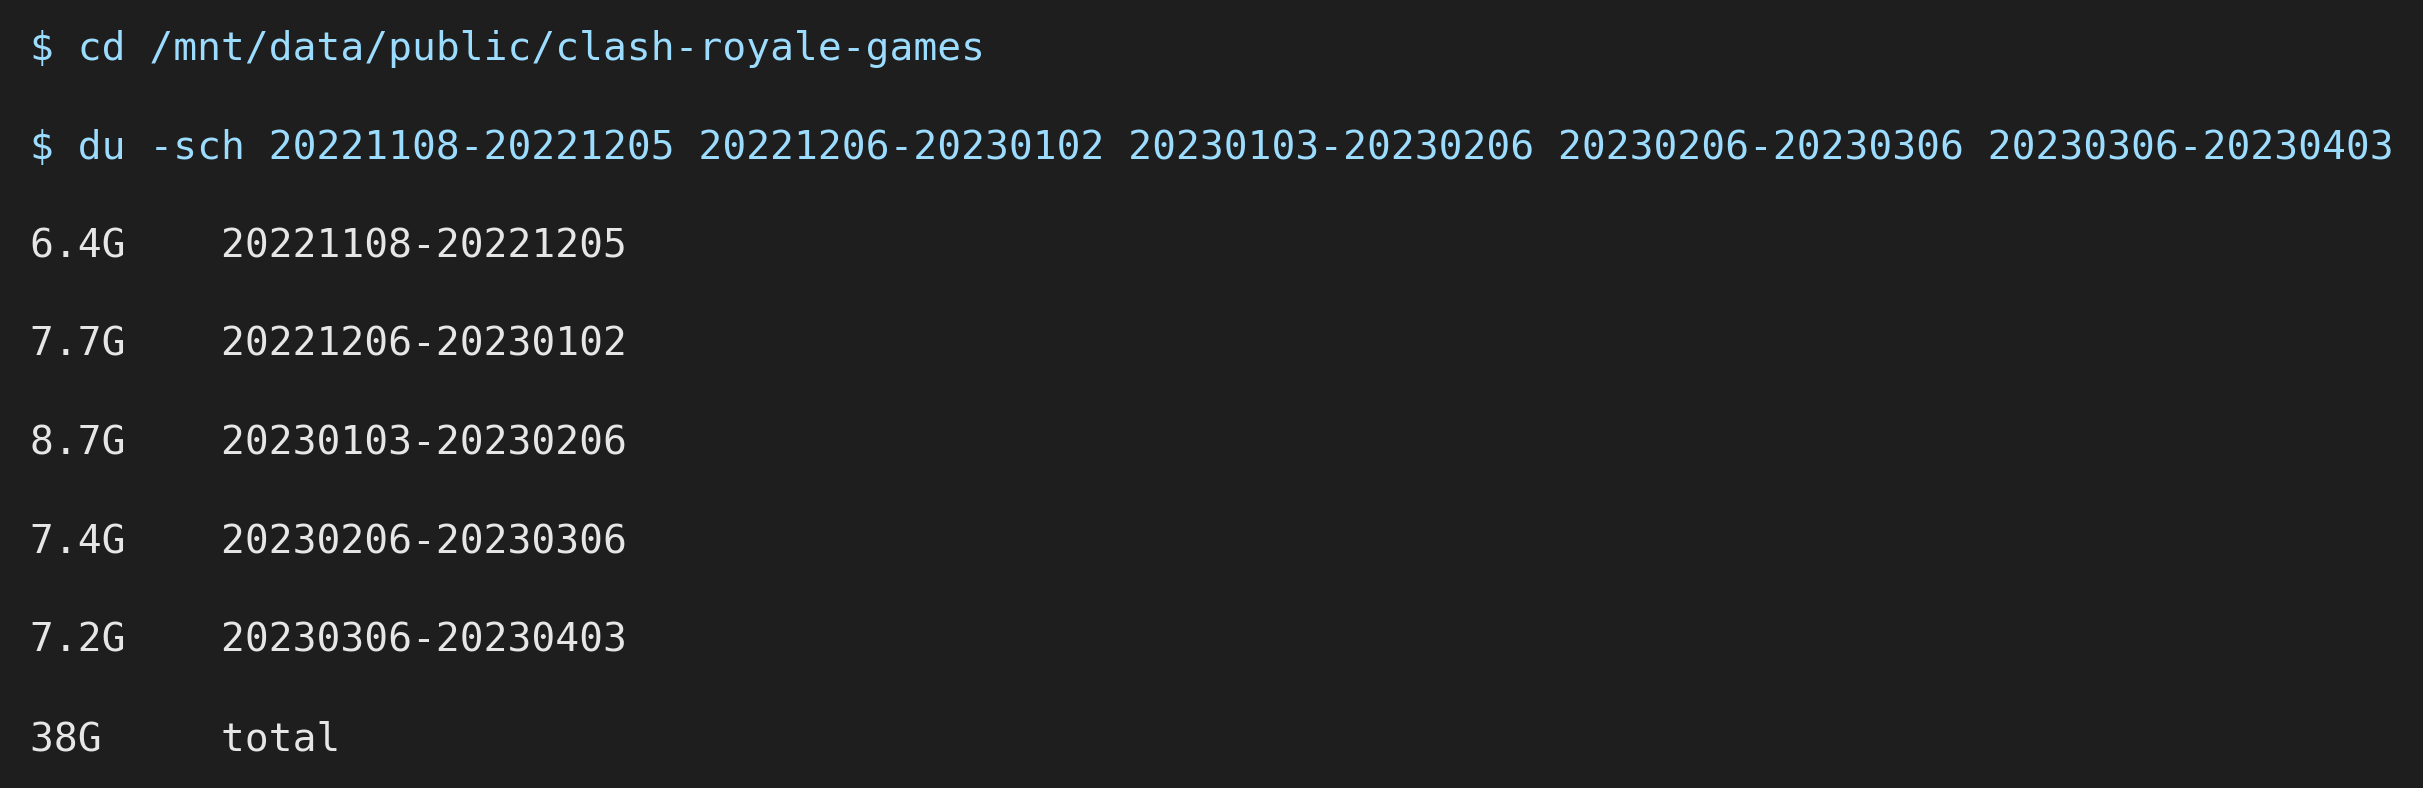

In [4]:
# Render the du -sch output of Section 2 as an image for the report
def render_terminal(text, filename):
    """Render command output as a terminal-style PNG (dark background)."""
    lines = text.expandtabs(8).rstrip("\n").splitlines()
    fig = plt.figure(figsize=(7.6, 0.32 * len(lines) + 0.4))
    fig.patch.set_facecolor("#1e1e1e")
    for i, line in enumerate(lines):
        fig.text(0.02, 1 - (i + 1) / (len(lines) + 1), line,
                 family="monospace", fontsize=9.5, va="center",
                 color="#9cdcfe" if line.startswith("$") else "#e6e6e6")
    path = OUT / filename
    fig.savefig(path, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(filename=str(path), width=700))


render_terminal(DU_TEXT, "du_sch_raw_input.png")

### 4.2 Card reference table
Card IDs are official Supercell IDs. The RoyaleAPI `cards.json` lookup (Table 2)
adds names, elixir cost, type and rarity. It is small, so Spark broadcasts it to
every task for joins.

In [5]:
# Card reference table (cached copy of RoyaleAPI cards.json)
CARDS_JSON = PROJECT_DIR / "ref" / "cards.json"
if not CARDS_JSON.exists():                      # first run only: download
    import urllib.request
    CARDS_JSON.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(
        "https://royaleapi.github.io/cr-api-data/json/cards.json", CARDS_JSON)
with open(CARDS_JSON) as handle:
    cards_ref = pd.DataFrame(json.load(handle))
cards_ref = (cards_ref[["id", "name", "elixir", "type", "rarity"]]
             .rename(columns={"id": "card_id", "name": "card_name"}))
CARD_NAME = dict(zip(cards_ref.card_id, cards_ref.card_name))
print(f"Table 2. Card reference: {len(cards_ref)} cards; elixir "
      f"{cards_ref.elixir.min()}–{cards_ref.elixir.max()} "
      f"(mean {cards_ref.elixir.mean():.2f})")
cards_ref.pivot_table(index="rarity", columns="type", values="card_id",
                      aggfunc="count", fill_value=0, margins=True)

Table 2. Card reference: 120 cards; elixir 1–9 (mean 4.08)


type,Building,Spell,Troop,All
rarity,,,,
Champion,0,0,6,6
Common,3,4,21,28
Epic,2,9,19,30
Legendary,1,3,24,28
Rare,8,3,17,28
All,14,19,87,120


## 5. Data ingestion, exploration and null-value handling

### 5.1 Schema enforcement
Spark does not infer the schema. The CSVs are read with the explicit 24-column
schema in Table 1, in `PERMISSIVE` mode, so a malformed field becomes `NULL`
instead of failing the job. A row is **valid** only if all of the following hold:
* all 24 fields parse;
* the timestamp parses;
* both crown counts are in 0–3;
* both decks hold eight *distinct* cards;
* the two player tags differ.

**Seasons by date.** Each row's `season_id` comes from its **battle date**, not
its folder. `20230206.csv` sits in both the S03 and S04 folders, and
`20230306.csv` in both S04 and S05. A boundary day belongs to the season whose
folder name starts on that day.

In [6]:
# Explicit 24-column schema, season-by-date assignment and validity rule
RAW_FIELDS = (
    [("battle_timestamp_raw", T.StringType()),
     ("game_mode_id", T.IntegerType()), ("p1_tag", T.StringType()),
     ("p1_trophies", T.IntegerType()), ("p1_crowns", T.IntegerType())]
    + [(f"p1_c{i}", T.IntegerType()) for i in range(1, 9)]
    + [("p2_tag", T.StringType()), ("p2_trophies", T.IntegerType()),
       ("p2_crowns", T.IntegerType())]
    + [(f"p2_c{i}", T.IntegerType()) for i in range(1, 9)]
)
RAW_SCHEMA = T.StructType([T.StructField(name, dtype, True)
                           for name, dtype in RAW_FIELDS])
assert len(RAW_SCHEMA) == 24

season_globs = {sid: f"{RAW_ROOT}/{folder}/{folder}/*.csv"
                for sid, (folder, _, _) in SEASONS.items()}
files_on_disk = {sid: sorted(glob.glob(p)) for sid, p in season_globs.items()}
n_files = sum(len(paths) for paths in files_on_disk.values())
print({sid: len(paths) for sid, paths in files_on_disk.items()},
      "total", n_files)
assert n_files == 149, n_files
N_EXPECTED_FILES = 149
read_paths = list(season_globs.values())
if SMOKE:   # one mid-season file per season + both copies of 20230206
    read_paths = sorted(
        {paths[len(paths) // 2] for paths in files_on_disk.values()}
        | {f for paths in files_on_disk.values() for f in paths
           if f.endswith("20230206.csv")})
    N_EXPECTED_FILES = len(read_paths)
    print("SMOKE TEST on", N_EXPECTED_FILES, "files")

raw = (spark.read.schema(RAW_SCHEMA).option("header", "false")
       .option("mode", "PERMISSIVE").csv(read_paths)
       .withColumn("source_file", F.input_file_name())
       .withColumn("source_folder",
                   F.regexp_extract("source_file",
                                    r"clash-royale-games/([0-9-]+)/", 1)))
p1_cards = F.array(*[F.col(f"p1_c{i}") for i in range(1, 9)])
p2_cards = F.array(*[F.col(f"p2_c{i}") for i in range(1, 9)])
raw = (raw
       .withColumn("battle_timestamp",
                   F.to_timestamp("battle_timestamp_raw",
                                  "yyyyMMdd'T'HHmmss.SSS'Z'"))
       .withColumn("p1_cards", p1_cards).withColumn("p2_cards", p2_cards)
       .withColumn("battle_date", F.to_date("battle_timestamp")))

# season_id from the battle date (boundary days go to the starting season)
season_expr = F.lit(None).cast("string")
for sid, (_, first_day, last_day) in SEASONS.items():
    in_season = F.col("battle_date").between(F.lit(first_day).cast("date"),
                                             F.lit(last_day).cast("date"))
    season_expr = F.when(in_season, F.lit(sid)).otherwise(season_expr)
raw = raw.withColumn("season_id", season_expr)

all_fields_present = F.lit(True)
for name, _ in RAW_FIELDS:
    all_fields_present = all_fields_present & F.col(name).isNotNull()
is_valid = (all_fields_present & F.col("battle_timestamp").isNotNull()
            & F.col("p1_crowns").between(0, 3)
            & F.col("p2_crowns").between(0, 3)
            & (F.size(F.array_distinct("p1_cards")) == 8)
            & (F.size(F.array_distinct("p2_cards")) == 8)
            & (F.col("p1_tag") != F.col("p2_tag")))
raw = raw.withColumn("is_valid", is_valid)

{'S01': 28, 'S02': 28, 'S03': 35, 'S04': 29, 'S05': 29} total 149


In [7]:
# Stage 1: map-only pass CSV -> typed Parquet partitioned by season
# (no shuffle, so memory use is bounded regardless of input size)
RAW_PARQUET = SCRATCH / "raw_typed.parquet"
if not done(RAW_PARQUET):
    stage_start = time.time()
    (raw.withColumn("source_file",
                    F.regexp_extract("source_file", r"([0-9]{8}\.csv)$", 1))
        .withColumn("season_id",
                    F.coalesce("season_id", F.lit("OUT_OF_WINDOW")))
        .drop("battle_timestamp_raw", "p1_cards", "p2_cards", "battle_date")
        .write.mode("overwrite").partitionBy("season_id")
        .parquet(str(RAW_PARQUET)))
    print(f"CSV -> Parquet {time.time() - stage_start:.0f}s")
raw_typed = spark.read.parquet(str(RAW_PARQUET))

# Per-file audit: every CSV must be registered by the reader
file_audit = to_pandas(raw_typed.groupBy("source_folder", "source_file").agg(
    F.count("*").alias("raw_rows"),
    F.sum((~F.col("is_valid")).cast("long")).alias("invalid_rows"),
    F.sum((F.col("season_id") == "OUT_OF_WINDOW").cast("long"))
    .alias("out_of_window_rows"),
    F.min("battle_timestamp").alias("min_ts"),
    F.max("battle_timestamp").alias("max_ts")))
file_audit = (file_audit.rename(columns={"source_file": "file"})
              .sort_values(["source_folder", "file"]))
save_table(file_audit, "ingestion_file_audit.parquet")
assert len(file_audit) == N_EXPECTED_FILES, "a CSV file was not read"
folder_audit = (file_audit.groupby("source_folder")
                .agg(files=("file", "count"), raw_rows=("raw_rows", "sum"),
                     invalid_rows=("invalid_rows", "sum"),
                     out_of_window_rows=("out_of_window_rows", "sum"))
                .reset_index())
caption(3, "Raw rows per season folder as read from disk, before "
        "deduplication: number of daily files, rows, rows failing the "
        "validity rules, and rows dated outside the study window.")
folder_audit

Table 3. Raw rows per season folder as read from disk, before deduplication: number of daily files,
rows, rows failing the validity rules, and rows dated outside the study window.


,source_folder,files,raw_rows,invalid_rows,out_of_window_rows
0,20221108-20221205,28,32913938,0,0
1,20221206-20230102,28,39958583,0,0
2,20230103-20230206,35,44970602,0,0
3,20230206-20230306,29,38572279,0,0
4,20230306-20230403,29,37455985,0,0


### 5.2 Raw-data exploration
Table 4 profiles **every raw column** after typing. It reports null counts, range,
mean and dispersion for the numeric fields, and distinct counts for the tags and
cards. Table 5 shows the game-mode mix, and Figure 2 shows daily volume. All of
these are computed on the raw rows, before deduplication or filtering.

In [8]:
# Profile of every raw column (cached after the first run)
NUMERIC_COLS = (["game_mode_id", "p1_trophies", "p1_crowns", "p2_trophies",
                 "p2_crowns"]
                + [f"p{side}_c{i}" for side in (1, 2) for i in range(1, 9)])
PROFILE_COLS = ["battle_timestamp", "p1_tag", "p2_tag"] + NUMERIC_COLS


def build_raw_profile():
    """One Spark pass: null count, min, max, mean, std of every raw column."""
    aggs = []
    for col in PROFILE_COLS:
        aggs.append(F.sum(F.col(col).isNull().cast("long"))
                    .alias(f"{col}__nulls"))
        aggs += [F.min(col).cast("string").alias(f"{col}__min"),
                 F.max(col).cast("string").alias(f"{col}__max")]
        if col in NUMERIC_COLS:
            aggs += [F.mean(col).alias(f"{col}__mean"),
                     F.stddev(col).alias(f"{col}__std")]
    aggs += [F.count("*").alias("rows"),
             F.approx_count_distinct("p1_tag").alias("p1_tag__distinct"),
             F.approx_count_distinct("p2_tag").alias("p2_tag__distinct"),
             F.mean((F.col("p1_tag") > F.col("p2_tag")).cast("double"))
             .alias("share_p1_tag_greater")]
    row = raw_typed.agg(*aggs).toPandas().iloc[0]
    return row.to_frame("value").reset_index(names="stat").astype(str)


raw_profile_long = cached_table("raw_profile", build_raw_profile)
profile_values = dict(zip(raw_profile_long.stat, raw_profile_long.value))
profile = pd.DataFrame([
    {"column": col,
     "nulls": int(float(profile_values[f"{col}__nulls"])),
     "min": profile_values[f"{col}__min"],
     "max": profile_values[f"{col}__max"],
     "mean": (round(float(profile_values[f"{col}__mean"]), 2)
              if col in NUMERIC_COLS else None),
     "std": (round(float(profile_values[f"{col}__std"]), 2)
             if col in NUMERIC_COLS else None)}
    for col in PROFILE_COLS])
RAW_ROWS = int(float(profile_values["rows"]))
print(f"Table 4. Raw-column profile over {RAW_ROWS:,} rows; approx. distinct "
      f"tags: p1 {int(float(profile_values['p1_tag__distinct'])):,}, p2 "
      f"{int(float(profile_values['p2_tag__distinct'])):,}; share of rows "
      f"with p1_tag > p2_tag: "
      f"{float(profile_values['share_p1_tag_greater']):.4f}")
profile

Table 4. Raw-column profile over 193,871,387 rows; approx. distinct tags: p1 6,502,757, p2 6,148,222; share of rows with p1_tag > p2_tag: 1.0000


,column,nulls,min,max,mean,std
0,battle_timestamp,0,2022-11-08 00:00:01,2023-04-03 23:59:59,NaN,NaN
1,p1_tag,0,2000QPCY9,YYYYYY8J9,NaN,NaN
2,p2_tag,0,200000JU,YYYYGLLGV,NaN,NaN
3,game_mode_id,0,72000006,72000328,72000216.81,139.20
4,p1_trophies,0,0,7500,3269.72,3395.10
5,p1_crowns,0,0,3,0.84,0.91
6,p2_trophies,0,0,7500,3295.23,3414.32
7,p2_crowns,0,0,3,0.88,0.92
8,p1_c1,0,26000000,28000006,26000138.48,14764.37
9,p1_c2,0,26000001,28000009,26000288.31,19979.45


In [9]:
# Trophy and crown distributions of the raw rows (both players stacked)
def build_raw_distributions():
    """Crown-score and per-mode trophy distributions of the raw rows."""
    both = raw_typed.select(
        "game_mode_id",
        F.explode(F.array(
            F.struct(F.col("p1_trophies").alias("trophies"),
                     F.col("p1_crowns").alias("crowns")),
            F.struct(F.col("p2_trophies").alias("trophies"),
                     F.col("p2_crowns").alias("crowns")))).alias("p"))
    return to_pandas(both.groupBy("game_mode_id").agg(
        F.count("*").alias("player_rows"),
        F.expr("percentile_approx(p.trophies, array(0.01, 0.25, 0.5, 0.75,"
               " 0.99), 10000)").alias("trophy_quantiles"),
        F.mean("p.crowns").alias("mean_crowns"),
        *[F.mean((F.col("p.crowns") == k).cast("double"))
          .alias(f"share_{k}_crowns") for k in range(4)]))


raw_dist = cached_table("raw_distributions", build_raw_distributions)
raw_dist["mode"] = raw_dist.game_mode_id.map(MODE_NAMES).fillna("unlisted")
for i, q in enumerate(["p01", "p25", "p50", "p75", "p99"]):
    raw_dist[f"trophies_{q}"] = raw_dist.trophy_quantiles.map(
        lambda arr, i=i: int(arr[i]))
raw_dist["battles"] = raw_dist.player_rows // 2
raw_dist["share_of_rows"] = raw_dist.battles / raw_dist.battles.sum()
print("Table 5. Game modes in the raw rows: volume, trophy-field quantiles, "
      "crowns per player")
(raw_dist.sort_values("battles", ascending=False)
 [["game_mode_id", "mode", "battles", "share_of_rows", "trophies_p01",
   "trophies_p25", "trophies_p50", "trophies_p75", "trophies_p99",
   "mean_crowns", "share_0_crowns", "share_3_crowns"]]
 .round(3).reset_index(drop=True))

Table 5. Game modes in the raw rows: volume, trophy-field quantiles, crowns per player


,game_mode_id,mode,battles,share_of_rows,trophies_p01,trophies_p25,trophies_p50,trophies_p75,trophies_p99,mean_crowns,share_0_crowns,share_3_crowns
0,72000323,Ranked1v1 (Path of Legends),55052718,0.284,0,0,30,30,2040,0.858,0.412,0.093
1,72000327,Ranked1v1_GoldRush,39206014,0.202,0,0,30,30,2031,0.855,0.411,0.091
2,72000006,Ladder,34402497,0.177,6439,6763,7057,7208,7500,0.862,0.401,0.086
3,72000044,Ladder_GoldRush,22449192,0.116,6494,7000,7137,7276,7500,0.864,0.400,0.086
4,72000291,Challenge_AllCards_EventDeck,17095367,0.088,3066,6096,6847,7309,7500,0.815,0.429,0.086
5,72000328,Ranked1v1_CrownRush,10414605,0.054,0,0,30,1347,2460,0.839,0.414,0.085
6,72000201,Ladder_CrownRush,7388093,0.038,6501,6855,7097,7265,7500,0.861,0.401,0.085
7,72000066,Showdown_Ladder,5167600,0.027,5314,6533,7018,7331,7500,1.010,0.409,0.165
8,72000007,Friendly,2268102,0.012,2658,6229,7004,7500,7500,0.794,0.430,0.078
9,72000009,Tournament,427199,0.002,0,1,3,5,14,0.833,0.429,0.098


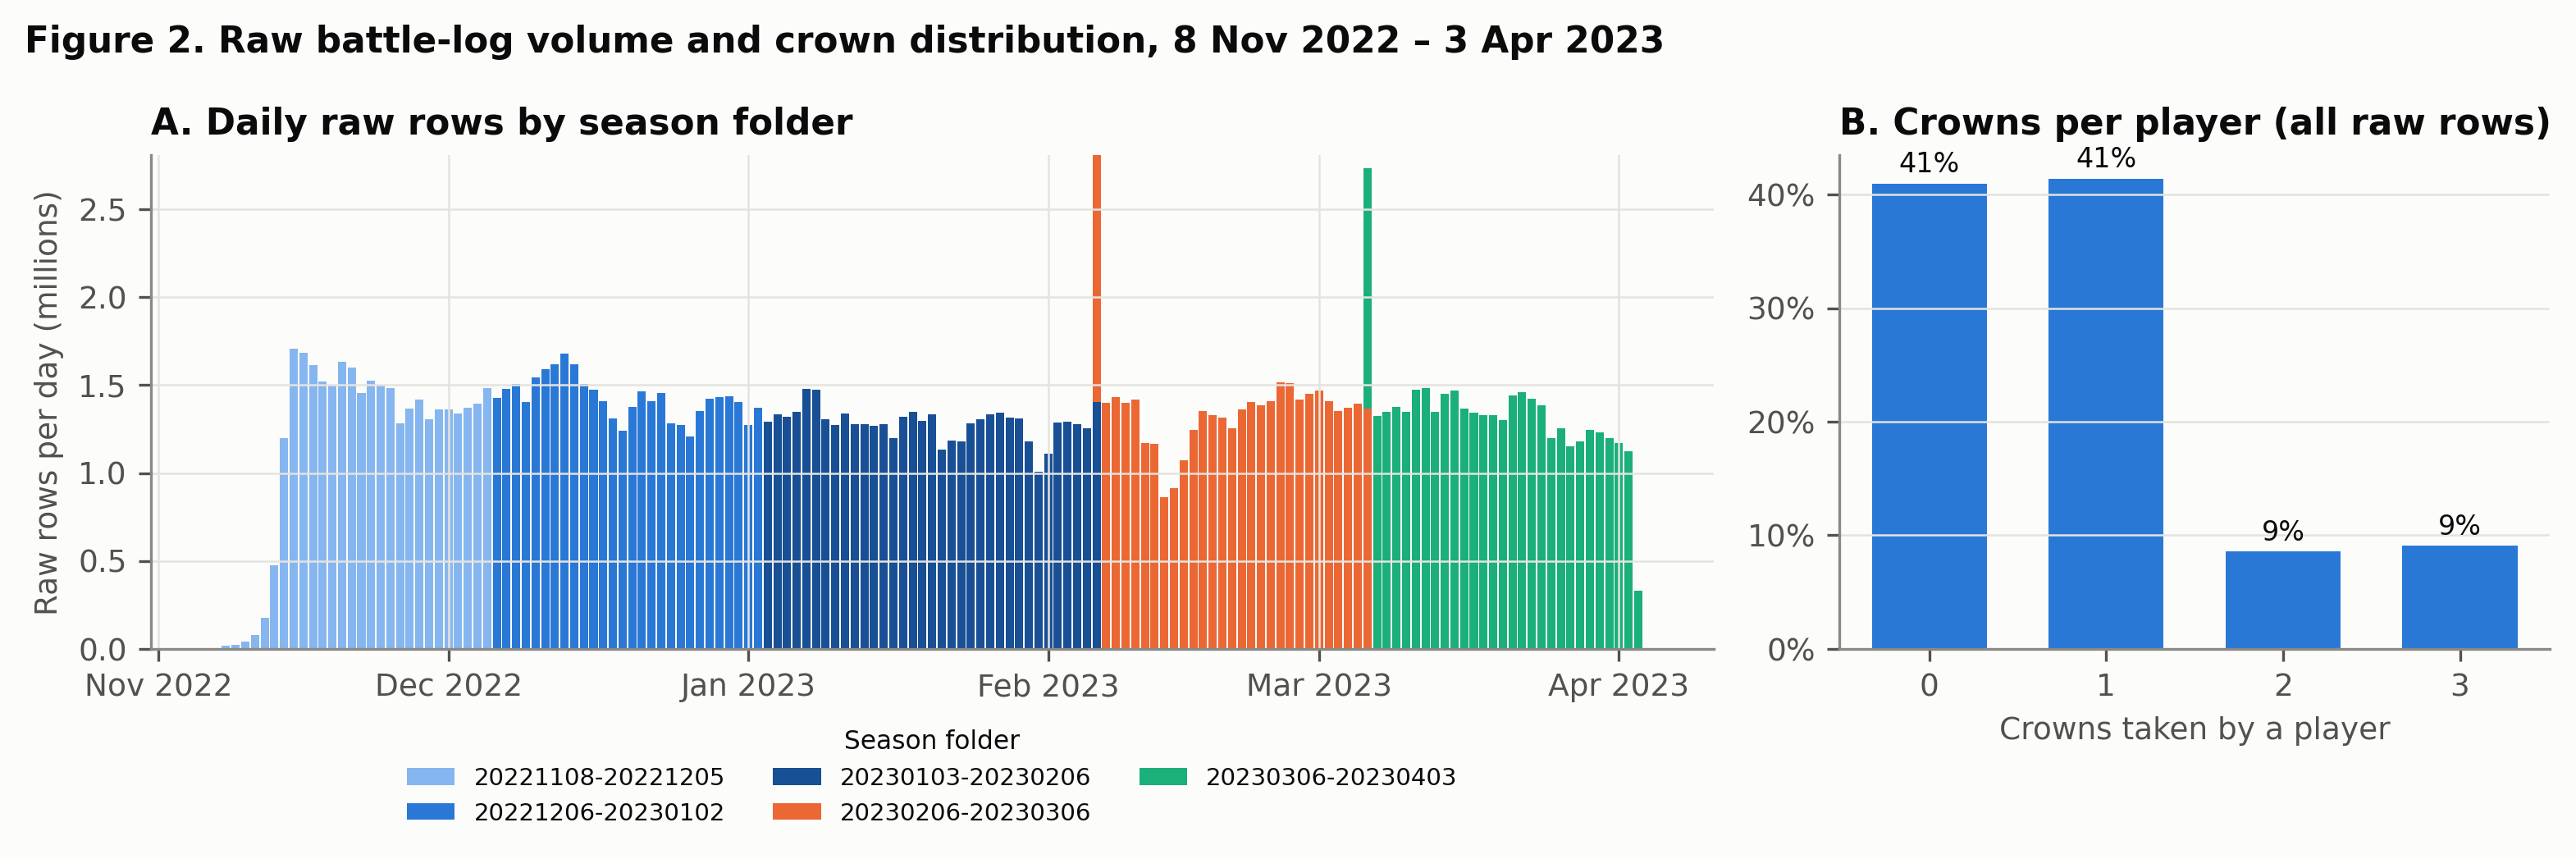

In [10]:
# Figure 2: daily raw volume per season + crown-score shares
daily = file_audit.assign(day=pd.to_datetime(file_audit.file.str[:8]))
daily_rows = daily.pivot_table(index="day", columns="source_folder",
                               values="raw_rows", aggfunc="sum",
                               fill_value=0)
fig, (ax_day, ax_crowns) = plt.subplots(
    1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
folder_colours = dict(zip(daily_rows.columns,
                          [RAMP["250"], C1, RAMP["600"], C2, C3]))
bottom = np.zeros(len(daily_rows))
for folder in daily_rows.columns:   # stacked: boundary days show 2 copies
    heights = daily_rows[folder].values / 1e6
    ax_day.bar(daily_rows.index, heights, bottom=bottom, width=0.85,
               color=folder_colours[folder], label=folder)
    bottom += heights
ax_day.set_ylabel("Raw rows per day (millions)")
ax_day.set_title("A. Daily raw rows by season folder")
ax_day.xaxis.set_major_locator(mdates.MonthLocator())
ax_day.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax_day.legend(fontsize=7, ncol=3, loc="upper center",
              bbox_to_anchor=(0.5, -0.12), title="Season folder",
              title_fontsize=7.5)
crown_rows = raw_dist[[f"share_{k}_crowns" for k in range(4)]].mul(
    raw_dist.player_rows, axis=0).sum() / raw_dist.player_rows.sum()
ax_crowns.bar([str(k) for k in range(4)], crown_rows.values, color=C1,
              width=0.65)
for k, share in enumerate(crown_rows.values):
    ax_crowns.text(k, share + 0.01, pct(share, 0), ha="center", fontsize=8)
ax_crowns.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax_crowns.set_xlabel("Crowns taken by a player")
ax_crowns.set_title("B. Crowns per player (all raw rows)")
ax_crowns.grid(axis="x", visible=False)
fig.suptitle("Figure 2. Raw battle-log volume and crown distribution, "
             "8 Nov 2022 – 3 Apr 2023", x=0.01, ha="left", fontsize=10.5,
             fontweight="semibold")
fig.tight_layout()
show_figure(fig, "fig2_raw_data_overview.png")

**Figure 2.** (A) Raw rows per daily file, coloured by season folder. The
collector ramps up during its first week (8–13 Nov 2022). After that, volume is
1.0–1.7 M rows per day, and the last file (3 Apr 2023) holds only a partial day.
The two days stored in two folders (6 Feb and 6 Mar 2023) appear as two-colour
bars of double height. These are the duplicates removed in Section 5.4.
(B) Share of player rows by crowns taken: 41% take 0 crowns, 41% take 1, and only
9% each take 2 or 3. Most battles are therefore decided by a single tower.

### 5.3 Null values and invalid rows: investigation and handling
* **Where nulls could come from.** With an explicit schema in `PERMISSIVE` mode,
  `NULL` can arise in three ways:
  * a field is missing, because the line is short;
  * a field fails to parse as its type, for example text in a trophies column;
  * the timestamp does not match `yyyyMMddTHHmmss.SSSZ`.

  So a null count is also a count of malformed lines.
* **What we found.** Table 4 shows **zero nulls in every one of the 24 columns**
  across all 193.9 M rows, and the file audit (Table 3) shows **zero rows
  failing the validity rules**. Crawled data can contain truncated or garbled
  lines, for example from interrupted writes. None occur in the five seasons
  studied here.
* **Handling.** Nothing needs imputing or dropping. The validity filter stays in
  the pipeline as a guard, so the same code is safe on other season folders.
* **Planned exclusions.** Some rows are removed on purpose later. These are not
  missing data:
  * ties: no winner, ~0.01% of battles;
  * battles outside the chosen modes or below τ_s.

  Section 6 reports each of these with its count.

### 5.4 Deduplication
* **Orientation check.** Every raw row (share 1.0000, Table 4) has
  `p1_tag > p2_tag`. This matches the collector, which stores the player with the
  higher tag first (Section 2.1). A swapped duplicate is therefore not expected.
  The canonical-orientation step is kept as a safeguard, so the pipeline stays
  correct on data from other collectors.
* **Algorithm.** Deduplication runs one season at a time, so each shuffle holds
  about a fifth of the data:
  1. **Canonicalise the orientation:** swap all player fields so that
     `p1_tag < p2_tag`.
  2. **Collapse identical raw lines**, grouping by the key plus a hash of the
     raw line.
  3. **Collapse remaining copies of the same battle**, grouping by the key
     `(timestamp, mode, p1_tag, p2_tag)`. These are swapped perspectives or
     conflicting copies. Keep one deterministic record per battle.

  `battle_id = xxhash64(key)` is stored as a compact identifier. Deduplication
  itself compares the exact key, so a hash collision cannot merge two battles.

In [11]:
# Stage 2: per-season deduplication (each shuffle ~1/5 of the data)
STAGED = OUT / "staged_battles.parquet"
swap = F.col("p1_tag") > F.col("p2_tag")
DEDUP_KEY = ["battle_timestamp", "game_mode_id", "p1_tag", "p2_tag"]
CONTENT = F.struct("p1_trophies", "p1_crowns", "p1_cards", "p2_trophies",
                   "p2_crowns", "p2_cards")
RAW_VALUE_COLS = (["battle_timestamp", "game_mode_id", "p1_tag",
                   "p1_trophies", "p1_crowns"]
                  + [f"p1_c{i}" for i in range(1, 9)]
                  + ["p2_tag", "p2_trophies", "p2_crowns"]
                  + [f"p2_c{i}" for i in range(1, 9)])


def oriented(name_if_kept, name_if_swapped):
    """Pick a column so that the lexicographically smaller tag is player 1."""
    return F.when(swap, F.col(name_if_swapped)).otherwise(F.col(name_if_kept))


def stage_season(season_id):
    """Deduplicate one season's valid rows into canonical battle records."""
    valid = raw_typed.filter((F.col("season_id") == season_id)
                             & F.col("is_valid"))
    player_fields = ["tag", "trophies", "crowns", "cards"]
    canonical = (
        valid.withColumn("raw_line_hash", F.xxhash64(*RAW_VALUE_COLS))
        .withColumn("p1_cards", p1_cards).withColumn("p2_cards", p2_cards)
        .select("battle_timestamp", "game_mode_id", "raw_line_hash",
                swap.cast("int").alias("was_swapped"),
                *[oriented(f"p1_{f}", f"p2_{f}").alias(f"p1_{f}")
                  for f in player_fields],
                *[oriented(f"p2_{f}", f"p1_{f}").alias(f"p2_{f}")
                  for f in player_fields]))
    # step 1: identical raw lines (count/first only; no collect_set buffers)
    lines = canonical.groupBy(*DEDUP_KEY, "raw_line_hash").agg(
        F.count("*").alias("n"), F.first("was_swapped").alias("was_swapped"),
        F.first(CONTENT).alias("r"))
    # step 2: remaining copies of the same canonical battle
    battles = lines.groupBy(*DEDUP_KEY).agg(
        F.sum("n").alias("dup_raw_rows"),
        F.count("*").alias("dup_distinct_lines"),
        (F.max("was_swapped") - F.min("was_swapped") + 1)
        .alias("dup_orientations"),
        F.when(F.min(F.xxhash64("r")) != F.max(F.xxhash64("r")), 2)
        .otherwise(1).alias("dup_contents"),
        F.min("r").alias("r"))
    return battles.select(
        F.xxhash64(*DEDUP_KEY).alias("battle_id"), "battle_timestamp",
        "game_mode_id", "p1_tag", "r.p1_trophies", "r.p1_crowns",
        "r.p1_cards", "p2_tag", "r.p2_trophies", "r.p2_crowns", "r.p2_cards",
        "dup_raw_rows", "dup_distinct_lines", "dup_orientations",
        "dup_contents")


for sid in SEASON_IDS:
    partition = STAGED / f"season_id={sid}"
    if done(partition):
        print(sid, "staged (cached)")
        continue
    stage_start = time.time()
    stage_season(sid).write.mode("overwrite").parquet(str(partition))
    print(f"{sid} dedup + staging {time.time() - stage_start:.0f}s")
staged = spark.read.parquet(str(STAGED))

S01 staged (cached)
S02 staged (cached)
S03 staged (cached)
S04 staged (cached)
S05 staged (cached)


In [12]:
# Deduplication audit (Check A)
dedup_audit = to_pandas(staged.groupBy("season_id").agg(
    F.sum("dup_raw_rows").alias("valid_rows_in"),
    F.sum(F.col("dup_raw_rows") - F.col("dup_distinct_lines"))
    .alias("exact_duplicates_removed"),
    F.sum(F.col("dup_distinct_lines") - 1)
    .alias("perspective_or_conflict_duplicates_removed"),
    F.sum((F.col("dup_orientations") > 1).cast("long"))
    .alias("battles_seen_in_both_orientations"),
    F.sum((F.col("dup_contents") > 1).cast("long"))
    .alias("battles_with_conflicting_copies"),
    F.count("*").alias("clean_battles")))
dedup_audit = dedup_audit.sort_values("season_id").reset_index(drop=True)
# Check A: rows in = duplicates removed + clean battles, every season
assert (dedup_audit.valid_rows_in - dedup_audit.exact_duplicates_removed
        - dedup_audit.perspective_or_conflict_duplicates_removed
        == dedup_audit.clean_battles).all()
save_table(dedup_audit, "ingestion_dedup_audit.parquet")
print("Check A passed.")
caption(6, "Deduplication audit per season: valid rows in, exact duplicate "
        "lines removed, swapped-perspective or conflicting copies removed, "
        "battles seen in both orientations or with conflicting content, and "
        "clean battles out.")
dedup_audit

Check A passed.
Table 6. Deduplication audit per season: valid rows in, exact duplicate lines removed, swapped-
perspective or conflicting copies removed, battles seen in both orientations or with conflicting
content, and clean battles out.


,season_id,valid_rows_in,exact_duplicates_removed,perspective_or_conflict_duplicates_removed,battles_seen_in_both_orientations,battles_with_conflicting_copies,clean_battles
0,S01,32913938,0,0,0,0,32913938
1,S02,39958583,0,0,0,0,39958583
2,S03,43568515,0,0,0,0,43568515
3,S04,38607203,1402087,0,0,0,37205116
4,S05,38823148,1367163,0,0,0,37455985


**Table 6** shows that:
* all **2,769,250 duplicates** are exact copies of the two boundary days stored
  in two folders (they land in S04 and S05);
* no battle appears in both orientations;
* no two copies of a battle disagree in content.

The swapped-perspective safeguard therefore removed nothing. That is consistent
with the collector's own per-day deduplication (Section 2.1).

## 6. Data filtering

### 6.1 Game modes
Table 5 lists the modes. The analysis keeps the **five competitive, matchmade
modes in which players bring their own deck** (RoyaleAPI deck selection =
*Collection*):
* Ladder, Ladder Gold Rush and Showdown Ladder;
* Path of Legends (Ranked 1v1) and Ranked 1v1 Gold Rush.

The following are excluded:
* **Event-deck challenges**: the decks are not chosen by the players, so pick
  rates would describe the event, not the players' choices.
* **Friendly and Tournament battles**: these are not matchmade, so neither
  opponent strength nor stakes are comparable.
* **The two Crown Rush modes (72000201, 72000328)**: these use player decks, but
  their win condition is altered, which would distort the crown-margin metrics.
  Section 11 measures how many high-trophy battles this removes.

### 6.2 Season-relative trophy threshold τ_s
* **Ladder trophies.** In the ladder modes the trophies field is *starting
  trophies*, capped at 7,500.
* **Path of Legends.** There the same field holds **league points**: the median
  is 30 and P99 is about 2,000 (Table 5). These are not on the ladder scale.

A high-trophy battle is one where **both** players have at least τ_s, the 75th
percentile of the season's ladder starting trophies (both players stacked):
* **Why season-relative.** Trophies inflate within the period, so a fixed cut-off
  would select a growing share of players (Section 10.1).
* **Why both players.** Requiring both players avoids mismatched battles.
* **Effect on Path of Legends.** Its league-point values never reach a ladder
  τ_s, so it drops out by construction. The high-trophy sample is in practice
  **high-trophy Trophy Road** (Ladder, Gold Rush, Showdown).

In [13]:
# Season trophy profile, tau_s, and qualifying shares vs a static rule
ladder_trophies = (staged.filter(F.col("game_mode_id").isin(LADDER_MODES))
                   .select("season_id",
                           F.explode(F.array("p1_trophies", "p2_trophies"))
                           .alias("trophies")))
QUANTILES = [0.25, 0.5, 0.75, 0.8, 0.9]
thresholds = to_pandas(ladder_trophies.groupBy("season_id").agg(
    F.count("*").alias("ladder_player_obs"),
    F.expr("percentile_approx(trophies, array("
           f"{','.join(map(str, QUANTILES))}), 100000)").alias("q"),
    F.mean("trophies").alias("mean"), F.max("trophies").alias("max"),
    F.mean((F.col("trophies") >= 7500).cast("double"))
    .alias("share_at_cap")))
thresholds = thresholds.sort_values("season_id").reset_index(drop=True)
for i, name in enumerate(["p25", "p50", "p75", "p80", "p90"]):
    thresholds[name] = thresholds.q.map(lambda arr, i=i: int(arr[i]))
thresholds = thresholds.drop(columns="q")
thresholds["tau"] = thresholds["p75"]
TAU = dict(zip(thresholds.season_id, thresholds.tau))
print("tau_s:", TAU)

tau_sdf = F.broadcast(spark.createDataFrame(
    thresholds[["season_id", "tau", "p80", "p90"]]))
staged_tau = staged.join(tau_sdf, "season_id")
both_above_tau = ((F.col("p1_trophies") >= F.col("tau"))
                  & (F.col("p2_trophies") >= F.col("tau")))
is_ladder = F.col("game_mode_id").isin(LADDER_MODES)
collection = staged_tau.filter(F.col("game_mode_id").isin(COLLECTION_MODES))
high_trophy = collection.filter(both_above_tau)

# Per season: collection volume, and tau_s vs a static ">= 7,000" rule
qualifying = to_pandas(collection.groupBy("season_id").agg(
    F.count("*").alias("collection_battles"),
    F.sum(is_ladder.cast("long")).alias("ladder_battles"),
    F.sum(both_above_tau.cast("long")).alias("high_trophy_battles"),
    F.sum((is_ladder & both_above_tau).cast("long"))
    .alias("high_trophy_ladder_battles"),
    F.sum((is_ladder & (F.col("p1_trophies") >= 7000)
           & (F.col("p2_trophies") >= 7000)).cast("long"))
    .alias("static7000_ladder_battles")))
thresholds = thresholds.merge(qualifying, on="season_id")
thresholds["share_ladder_battles_qualifying_tau"] = (
    thresholds.high_trophy_ladder_battles / thresholds.ladder_battles)
thresholds["share_ladder_battles_qualifying_static7000"] = (
    thresholds.static7000_ladder_battles / thresholds.ladder_battles)
thresholds["season_label"] = thresholds.season_id.map(SEASON_LABEL)
thresholds["tau_quantile"] = TAU_QUANTILE
save_table(thresholds, "seasonal_trophy_thresholds.parquet")
caption(7, "Ladder starting trophies per season (both players stacked): "
        "mean, quantiles, share at the 7,500 cap, the threshold tau_s "
        "(= P75), ladder battles, and the share of ladder battles in "
        "which both players qualify under tau_s vs. a static 7,000 rule.")
thresholds[["season_id", "season_label", "mean", "p25", "p50", "p75", "p80",
            "p90", "share_at_cap", "tau", "ladder_battles",
            "share_ladder_battles_qualifying_tau",
            "share_ladder_battles_qualifying_static7000"]].round(3)

tau_s: {'S01': 6798, 'S02': 7087, 'S03': 7242, 'S04': 7305, 'S05': 7384}


Table 7. Ladder starting trophies per season (both players stacked): mean, quantiles, share at the
7,500 cap, the threshold tau_s (= P75), ladder battles, and the share of ladder battles in which
both players qualify under tau_s vs. a static 7,000 rule.


,season_id,season_label,mean,p25,p50,p75,p80,p90,share_at_cap,tau,ladder_battles,share_ladder_battles_qualifying_tau,share_ladder_battles_qualifying_static7000
0,S01,Nov 2022,6707.877,6557,6647,6798,6856,7060,0.006,6798,11828878,0.220,0.147
1,S02,Dec 2022,6917.777,6734,6873,7087,7122,7237,0.021,7087,12534506,0.209,0.406
2,S03,Jan 2023,7149.187,7033,7121,7242,7278,7383,0.062,7242,12558242,0.204,0.919
3,S04,Feb 2023,7213.912,7103,7194,7305,7340,7465,0.092,7305,9957772,0.202,0.987
4,S05,Mar 2023,7275.680,7171,7264,7384,7430,7500,0.163,7384,9327996,0.209,0.995


In [14]:
# Check B: only player-deck modes remain; both players >= tau_s everywhere
high_modes = to_pandas(high_trophy.groupBy("game_mode_id").count())
high_modes["mode"] = high_modes.game_mode_id.map(MODE_NAMES)
print(high_modes.to_string(index=False))
assert set(high_modes.game_mode_id) <= set(COLLECTION_MODES)
assert high_trophy.filter(~both_above_tau).count() == 0
print("Check B passed: collection modes only; both players >= tau_s")
tie_counts = to_pandas(high_trophy.groupBy("season_id").agg(
    F.count("*").alias("hi_battles_incl_ties"),
    F.sum((F.col("p1_crowns") == F.col("p2_crowns")).cast("long"))
    .alias("ties")))

 game_mode_id   count            mode
     72000044 4616371 Ladder_GoldRush
     72000006 7134602          Ladder
     72000066  530135 Showdown_Ladder


Check B passed: collection modes only; both players >= tau_s


### 6.3 Filtering funnel
Table 8 lists every filtering step, with the rows remaining and the share kept
relative to the previous step and to the raw input.

In [15]:
# Filtering funnel: rows remaining after each step
crown_rush_all = int(raw_dist.loc[raw_dist.game_mode_id.isin(CROWN_RUSH_MODES),
                                  "battles"].sum())
funnel_steps = [
    ("Raw rows read (149 files)", RAW_ROWS,
     "every line of every in-scope CSV"),
    ("Valid rows", RAW_ROWS - int(file_audit.invalid_rows.sum()),
     "all fields parse; crowns 0–3; 8 distinct cards; distinct tags"),
    ("Inside study window", RAW_ROWS - int(file_audit.invalid_rows.sum())
     - int(file_audit.out_of_window_rows.sum()),
     "battle date 8 Nov 2022 – 3 Apr 2023"),
    ("Unique battles (deduplicated)", int(dedup_audit.clean_battles.sum()),
     "boundary-day copies removed"),
    ("Player-deck competitive modes",
     int(thresholds.collection_battles.sum()),
     "Ladder, Gold Rush, Showdown, Path of Legends ×2"),
    ("Both players ≥ τ_s", int(tie_counts.hi_battles_incl_ties.sum()),
     "season P75 ladder trophies"),
    ("Non-tie battles (analysis sample)",
     int(tie_counts.hi_battles_incl_ties.sum() - tie_counts.ties.sum()),
     "ties have no winner"),
]
funnel = pd.DataFrame(funnel_steps, columns=["step", "rows", "rule"])
funnel["kept_vs_previous"] = funnel.rows / funnel.rows.shift(1)
funnel["kept_vs_raw"] = funnel.rows / funnel.rows.iloc[0]
save_table(funnel, "filtering_funnel.parquet")
caption(8, "Filtering funnel from raw rows to the analysis sample: rows "
        "(or battles) remaining after each step, the rule applied, and "
        "the share kept relative to the previous step and to the raw "
        "input.")
funnel.assign(rows=funnel.rows.map("{:,.0f}".format),
              kept_vs_previous=funnel.kept_vs_previous.map(
                  lambda v: "—" if pd.isna(v) else f"{v:.2%}"),
              kept_vs_raw=funnel.kept_vs_raw.map("{:.2%}".format))

Table 8. Filtering funnel from raw rows to the analysis sample: rows (or battles) remaining after
each step, the rule applied, and the share kept relative to the previous step and to the raw input.


,step,rows,rule,kept_vs_previous,kept_vs_raw
0,Raw rows read (149 files),"193,871,387",every line of every in-scope CSV,—,100.00%
1,Valid rows,"193,871,387",all fields parse; crowns 0–3; 8 distinct cards...,100.00%,100.00%
2,Inside study window,"193,871,387",battle date 8 Nov 2022 – 3 Apr 2023,100.00%,100.00%
3,Unique battles (deduplicated),"191,102,137",boundary-day copies removed,98.57%,98.57%
4,Player-deck competitive modes,"154,109,202","Ladder, Gold Rush, Showdown, Path of Legends ×2",80.64%,79.49%
5,Both players ≥ τ_s,"12,281,108",season P75 ladder trophies,7.97%,6.33%
6,Non-tie battles (analysis sample),"12,279,413",ties have no winner,99.99%,6.33%


## 7. Player observations, deck canonicalisation and deck families

### 7.1 Unpivoting and ties
* **Two observations per battle.** Each high-trophy battle becomes one
  observation per player:
  * `win = crowns > opponent crowns`;
  * `margin = |crowns − opponent crowns|`.
* **Ties are excluded** from every metric. With equal crowns there is no winner.
  They are rare (1,695 battles, 0.01%), and Tables 8 and 9 report it.
* **Pick-rate denominator.** Every pick rate divides by `2 × N_battles`, over
  the same non-tie set.
* **Deck ID.** `deck_id = sorted card IDs joined by "-"`, so the ID does not
  depend on the order of the card slots.

In [16]:
# Stage 4: unpivot battles into two player observations each
OBSERVATIONS = SCRATCH / "observations.parquet"


def player_side(me, opponent):
    """Struct of one player's view of a battle (tag, trophies, crowns...)."""
    return F.struct(
        F.col(f"{me}_tag").alias("player_tag"),
        F.col(f"{me}_trophies").alias("trophies"),
        F.col(f"{me}_crowns").alias("crowns"),
        F.col(f"{opponent}_crowns").alias("opp_crowns"),
        F.array_sort(F.col(f"{me}_cards")).alias("cards"),
        F.array_sort(F.col(f"{opponent}_cards")).alias("opp_cards"))


def deck_id_of(cards):
    """Order-invariant deck ID: sorted card IDs joined by '-'."""
    return F.concat_ws("-", F.transform(F.sort_array(cards),
                                        lambda card: card.cast("string")))


if not done(OBSERVATIONS):
    stage_start = time.time()
    observations_out = (
        high_trophy.filter(F.col("p1_crowns") != F.col("p2_crowns"))
        .select("season_id", "battle_id", "battle_timestamp", "game_mode_id",
                F.explode(F.array(player_side("p1", "p2"),
                                  player_side("p2", "p1"))).alias("o"))
        .select("season_id", "battle_id", "battle_timestamp", "game_mode_id",
                "o.*")
        .withColumn("week", F.to_date(F.date_trunc("week",
                                                   "battle_timestamp")))
        .withColumn("win", (F.col("crowns") > F.col("opp_crowns")).cast("int"))
        .withColumn("margin", F.abs(F.col("crowns") - F.col("opp_crowns")))
        .withColumn("deck_id", deck_id_of(F.col("cards")))
        .withColumn("opp_deck_id", deck_id_of(F.col("opp_cards")))
        .withColumn("deck_mirror",
                    (F.col("deck_id") == F.col("opp_deck_id")).cast("int")))
    (observations_out.write.mode("overwrite").partitionBy("season_id")
     .parquet(str(OBSERVATIONS)))
    print(f"observations written {time.time() - stage_start:.0f}s")
obs = spark.read.parquet(str(OBSERVATIONS))
season_counts = to_pandas(obs.groupBy("season_id").agg(
    (F.count("*") / 2).cast("long").alias("n_battles"),
    F.countDistinct("player_tag").alias("distinct_players")))
season_counts = (season_counts.merge(tie_counts, on="season_id")
                 .sort_values("season_id").reset_index(drop=True))
N_BATTLES = dict(zip(season_counts.season_id, season_counts.n_battles))
N_BATTLES["ALL"] = int(season_counts.n_battles.sum())
assert (season_counts.hi_battles_incl_ties - season_counts.ties
        == season_counts.n_battles).all()
caption(9, "High-trophy analysis sample per season: non-tie battles, "
        "distinct players, battles including ties, and ties excluded.")
season_counts

Table 9. High-trophy analysis sample per season: non-tie battles, distinct players, battles
including ties, and ties excluded.


,season_id,n_battles,distinct_players,hi_battles_incl_ties,ties
0,S01,2665208,109392,2665613,405
1,S02,2704606,118058,2704902,296
2,S03,2701472,165520,2701881,409
3,S04,2151252,193857,2151572,320
4,S05,2056875,231641,2057140,265


In [17]:
# Check C: deck_id is permutation invariant (shuffle slots, recompute)
sample = obs.select("cards", "deck_id").limit(2000).toPandas()
rng = np.random.default_rng(7)
shuffled = spark.createDataFrame(pd.DataFrame({
    "cards": [list(map(int, rng.permutation(c))) for c in sample.cards],
    "expected": sample.deck_id}))
mismatches = (shuffled.withColumn("recomputed", deck_id_of(F.col("cards")))
              .filter("recomputed != expected").count())
assert mismatches == 0
assert obs.filter(F.size(F.split("deck_id", "-")) != 8).count() == 0
print("Check C (part 1): deck_id is order invariant on 2,000 shuffled "
      "samples; every deck has 8 cards")

Check C (part 1): deck_id is order invariant on 2,000 shuffled samples; every deck has 8 cards


### 7.2 Deck families (decks sharing seven of eight cards)
* **Cores.** Each deck has eight 7-card *cores*: the deck with one card removed.
  Two decks are related if they share a core.
* **Why not chain the relation.** Taken transitively (connected components), the
  relation chains archetypes: A shares a core with B, B shares a different core
  with C, and so on. Popular decks that differ in three or four cards would end
  up in one giant component, which the union-find comparison below measures.
* **Greedy assignment instead.** Decks are assigned to families in order of
  volume, without chaining:
  1. Pool deck volumes over all seasons. Take the decks with at least 20
     observations, in descending order of volume.
  2. A deck that shares a core with an existing *head* joins the
     highest-volume such head. Otherwise it becomes a new head and registers its
     eight cores. Only heads register cores, so every member differs from its
     head by at most one card.
  3. Decks with fewer than 20 observations join the highest-volume head they
     share a core with. If there is none, they form a family of their own.
* **Naming.** `family_id` is the head's `deck_id`. By construction, the head is
  the most-played variant of its family.

In [18]:
# Stage 5: deck volumes, greedy family heads, family map (Check C)
def cores_of(cards):
    """The eight 7-card cores of a deck (deck minus one card each)."""
    return F.transform(
        F.sequence(F.lit(0), F.lit(7)),
        lambda i: F.concat_ws("-", F.transform(
            F.filter(cards, lambda card, j: j != i),
            lambda card: card.cast("string"))))


DECK_VOLUME = SCRATCH / "deck_volume.parquet"
if not done(DECK_VOLUME):
    (obs.groupBy("deck_id").agg(F.count("*").alias("n_obs"),
                                F.first("cards").alias("cards"))
     .withColumn("cores", cores_of(F.col("cards")))
     .write.mode("overwrite").parquet(str(DECK_VOLUME)))
deck_volume = spark.read.parquet(str(DECK_VOLUME))
n_decks_total = deck_volume.count()

seeds = (deck_volume.filter(F.col("n_obs") >= FAMILY_SEED_MIN_OBS)
         .select("deck_id", "n_obs", "cores").toPandas()
         .sort_values(["n_obs", "deck_id"], ascending=[False, True])
         .reset_index(drop=True))
head_of_core, family_of_deck, head_order = {}, {}, {}
for deck, cores in zip(seeds.deck_id, seeds.cores):
    head = None
    for core in cores:   # highest-volume (earliest) head among shared cores
        candidate = head_of_core.get(core)
        if candidate is not None and (
                head is None or head_order[candidate] < head_order[head]):
            head = candidate
    if head is None:     # no shared core: this deck starts a new family
        head = deck
        head_order[deck] = len(head_order)
        for core in cores:
            head_of_core.setdefault(core, deck)
    family_of_deck[deck] = head
print(f"{n_decks_total:,} distinct decks; {len(seeds):,} seed decks -> "
      f"{len(head_order):,} family heads")

head_cores = spark.createDataFrame(pd.DataFrame({
    "core": list(head_of_core), "head": list(head_of_core.values()),
    "head_order": [head_order[h] for h in head_of_core.values()]}))
small_decks = (deck_volume.filter(F.col("n_obs") < FAMILY_SEED_MIN_OBS)
               .select("deck_id", F.explode("cores").alias("core")))
by_head_order = Window.partitionBy("deck_id").orderBy("head_order")
small_map = (small_decks.join(head_cores, "core")
             .withColumn("rank", F.row_number().over(by_head_order))
             .filter("rank = 1")
             .select("deck_id", F.col("head").alias("family_id")))
seed_map = spark.createDataFrame(pd.DataFrame({
    "deck_id": list(family_of_deck),
    "family_id": list(family_of_deck.values())}))
family_map = (deck_volume.select("deck_id")
              .join(seed_map.unionByName(small_map), "deck_id", "left")
              .withColumn("family_id", F.coalesce("family_id", "deck_id")))
FAMILY_MAP = SCRATCH / "family_map.parquet"
if not done(FAMILY_MAP):
    family_map.write.mode("overwrite").parquet(str(FAMILY_MAP))
family_map = spark.read.parquet(str(FAMILY_MAP))

# Check C (part 2): one family per deck; members within one card of the head;
# the head is the most-played variant
assert (family_map.count() == n_decks_total
        == family_map.select("deck_id").distinct().count())
shared_cards = (family_map
                .withColumn("deck", F.split("deck_id", "-"))
                .withColumn("head", F.split("family_id", "-"))
                .select(F.size(F.array_intersect("deck", "head"))
                        .alias("shared")))
assert shared_cards.filter("shared < 7").count() == 0
family_volume = family_map.join(deck_volume.select("deck_id", "n_obs"),
                                "deck_id")
by_family_volume = Window.partitionBy("family_id").orderBy(F.desc("n_obs"),
                                                           "deck_id")
top_variant = family_volume.withColumn(
    "rank", F.row_number().over(by_family_volume))
assert top_variant.filter("rank = 1 AND deck_id != family_id").count() == 0
family_sizes = to_pandas(family_volume.groupBy("family_id").agg(
    F.count("*").alias("variants"), F.sum("n_obs").alias("n_obs")))
top100_share = (family_sizes.nlargest(100, "n_obs").n_obs.sum()
                / family_sizes.n_obs.sum())
print(f"{len(family_sizes):,} families; the top 100 cover "
      f"{pct(top100_share)} of observations")
print("Check C (part 2) passed: members share >= 7 cards with their head")

1,073,530 distinct decks; 127,112 seed decks -> 71,081 family heads


740,119 families; the top 100 cover 40.1% of observations
Check C (part 2) passed: members share >= 7 cards with their head


In [19]:
# Contrast: transitive connected components over shared cores (union-find)
parent = {}


def find_root(node):
    """Union-find root lookup with path halving."""
    while parent.setdefault(node, node) != node:
        parent[node] = parent[parent[node]]
        node = parent[node]
    return node


first_deck_of_core = {}
for deck, cores in zip(seeds.deck_id, seeds.cores):
    find_root(deck)
    for core in cores:
        other = first_deck_of_core.setdefault(core, deck)
        if other != deck:
            root_a, root_b = find_root(other), find_root(deck)
            if root_a != root_b:
                parent[root_b] = root_a
component = pd.Series({deck: find_root(deck) for deck in seeds.deck_id})
component_volume = (seeds.assign(component=seeds.deck_id.map(component))
                    .groupby("component").n_obs.sum()
                    .sort_values(ascending=False))
largest_component_share = component_volume.iloc[0] / seeds.n_obs.sum()
largest_family_share = family_sizes.n_obs.max() / family_sizes.n_obs.sum()
print(f"Transitive components: {component.nunique():,}; the largest holds "
      f"{pct(largest_component_share)} of seed-deck observations. Greedy "
      f"heads: the largest family holds {pct(largest_family_share)}.")

Transitive components: 49,908; the largest holds 80.5% of seed-deck observations. Greedy heads: the largest family holds 2.0%.


## 8. Performance metrics

* **Pick rate.** Observations containing the card, deck or family, divided by
  `2 × N_battles` for the season.
* **Non-mirror win rate.** Wins divided by matches, counting only matches where
  the opponent does *not* share the entity:
  * cards: the opponent does not also hold the card;
  * decks: the opponent's deck is not the identical deck;
  * families: the opponent's deck is not in the same family.

  A mirror match is always won by one copy and lost by the other, so it adds
  exactly 50% and pulls the win rates of popular entities toward 50%.
* **Empirical-Bayes (EB) win rate.** The approach follows Efron & Morris (1975),
  Casella (1985) and Robinson (2017):
  * a Beta(α, β) prior is fitted per season and entity type, by method of
    moments, on entities with at least 100 non-mirror matches;
  * binomial sampling noise is removed from the observed spread first:
    `var_true = var(p̂) − mean(p̂(1−p̂)/n)`;
  * the prior strength is `M = μ(1−μ)/var_true − 1`;
  * the smoothed rate is `WR_EB = (wins + M·μ) / (n + M)`. It shrinks
    small-sample rates toward the prior mean μ, and large samples barely move;
  * if the fit is degenerate (`var_true ≤ 0`), it falls back to μ = 0.5 and
    M = 200.
* **Crown margin.** Non-mirror wins split by `|crowns − opponent crowns|` ∈
  {1, 2, 3}. Margin 1 covers 1–0, 2–1 and 3–2 results. Margin 3 is a 3–0 shutout.

In [20]:
# Metric helpers: Empirical-Bayes prior, crown shares, margin sums
def fit_beta_prior(table, n_col="nm_matches", wins_col="nm_wins",
                   min_n=EB_MIN_N):
    """Method-of-moments Beta prior (mu, M, note) net of binomial noise."""
    fit_set = table[table[n_col] >= min_n]
    if len(fit_set) < 10:
        return 0.5, EB_FALLBACK_M, "fallback (too few entities)"
    rate = fit_set[wins_col] / fit_set[n_col]
    mu = rate.mean()
    var_true = rate.var(ddof=1) - (rate * (1 - rate) / fit_set[n_col]).mean()
    if var_true <= 0:
        return 0.5, EB_FALLBACK_M, "fallback (no excess variance)"
    strength = min(max(mu * (1 - mu) / var_true - 1, 1.0), 1e6)
    return float(mu), float(strength), f"moments on {len(fit_set)} entities"


EB_PRIORS = []


def apply_eb(table, entity, scope_col="season_id"):
    """Add EB-smoothed win rate `wr_eb` with one prior per scope (season)."""
    parts = []
    for scope, group in table.groupby(scope_col):
        mu, strength, note = fit_beta_prior(group)
        group = group.copy()
        group["wr_eb"] = ((group.nm_wins + strength * mu)
                          / (group.nm_matches + strength))
        group["eb_prior_mu"], group["eb_prior_M"] = mu, strength
        EB_PRIORS.append({"entity": entity, "scope": scope, "mu0": mu,
                          "M": strength, "alpha": strength * mu,
                          "beta": strength * (1 - mu), "fit": note})
        parts.append(group)
    return pd.concat(parts, ignore_index=True)


def add_crown_shares(table):
    """Add win_{1,2,3}crown_pct: share of non-mirror wins by crown margin."""
    wins = table.nm_wins.where(table.nm_wins > 0)
    for k in (1, 2, 3):
        table[f"win_{k}crown_pct"] = table[f"w{k}"] / wins
    return table


def margin_sums(nonmirror_col):
    """Spark aggregations: non-mirror wins with crown margin 1, 2 and 3."""
    return [F.sum(F.col(nonmirror_col) * F.col("win")
                  * (F.col("margin") == k).cast("int")).alias(f"w{k}")
            for k in (1, 2, 3)]

### 8.1 Card metrics

In [21]:
# Card metrics: weekly aggregates rolled up to season and pooled scope
card_obs = (obs.select("season_id", "week", "win", "margin", "opp_cards",
                       F.explode("cards").alias("card_id"))
            .withColumn("nm", (~F.array_contains("opp_cards",
                                                 F.col("card_id")))
                        .cast("int")))
card_week = to_pandas(card_obs.groupBy("season_id", "week", "card_id").agg(
    F.count("*").alias("obs"), F.sum("win").alias("wins"),
    F.sum("nm").alias("nm_matches"),
    F.sum(F.col("nm") * F.col("win")).alias("nm_wins"), *margin_sums("nm")))
week_battles = to_pandas(obs.groupBy("season_id", "week").agg(
    (F.count("*") / 2).alias("n_battles")))

SUM_COLS = ["obs", "wins", "nm_matches", "nm_wins", "w1", "w2", "w3"]
card_season = card_week.groupby(["season_id", "card_id"],
                                as_index=False)[SUM_COLS].sum()
card_pooled = (card_week.groupby("card_id", as_index=False)[SUM_COLS].sum()
               .assign(season_id="ALL"))
card_metrics = pd.concat([card_season, card_pooled], ignore_index=True)
card_metrics["n_battles"] = card_metrics.season_id.map(N_BATTLES)
card_metrics["pick_rate"] = card_metrics.obs / (2 * card_metrics.n_battles)
card_metrics["wr_all"] = card_metrics.wins / card_metrics.obs
card_metrics["mirror_share"] = 1 - card_metrics.nm_matches / card_metrics.obs
card_metrics["wr_nonmirror"] = card_metrics.nm_wins / card_metrics.nm_matches
card_metrics = add_crown_shares(apply_eb(card_metrics, "card"))
card_metrics = card_metrics.merge(cards_ref, on="card_id", how="left")
card_metrics["card_name"] = card_metrics.card_name.fillna(
    card_metrics.card_id.astype(str))
card_metrics["pick_rank"] = card_metrics.groupby("season_id").pick_rate.rank(
    ascending=False, method="min")
card_metrics["season_label"] = (card_metrics.season_id.map(SEASON_LABEL)
                                .fillna("All seasons"))
# each observation holds exactly 8 cards -> pick rates sum to 8 per scope
assert np.allclose(card_metrics.groupby("season_id").pick_rate.sum(), 8.0)
print("card IDs absent from lookup:",
      sorted(set(card_metrics.card_id) - set(cards_ref.card_id)))
save_table(card_metrics, "card_seasonal_metrics.parquet")
caption(10, "The fifteen most-picked cards, all seasons pooled: pick "
        "rate, share of observations facing the same card (mirror), "
        "win rate over all matches, non-mirror win rate, EB-smoothed "
        "win rate, and number of non-mirror matches.")
(card_metrics[card_metrics.season_id == "ALL"]
 .nlargest(15, "pick_rate")
 [["card_name", "pick_rate", "mirror_share", "wr_all", "wr_nonmirror",
   "wr_eb", "nm_matches"]].round(4).reset_index(drop=True))

card IDs absent from lookup: []
Table 10. The fifteen most-picked cards, all seasons pooled: pick rate, share of observations facing
the same card (mirror), win rate over all matches, non-mirror win rate, EB-smoothed win rate, and
number of non-mirror matches.


,card_name,pick_rate,mirror_share,wr_all,wr_nonmirror,wr_eb,nm_matches
0,The Log,0.3584,0.3612,0.4968,0.4950,0.4950,5623423
1,Tornado,0.2498,0.2572,0.5035,0.5047,0.5047,4557752
2,Phoenix,0.2084,0.2574,0.5177,0.5238,0.5238,3800211
3,Arrows,0.2069,0.2182,0.5049,0.5062,0.5062,3973287
4,Fireball,0.1905,0.1929,0.5031,0.5038,0.5038,3776080
5,Barbarian Barrel,0.1886,0.1918,0.5216,0.5267,0.5267,3742899
6,Zap,0.1840,0.1891,0.4976,0.4971,0.4971,3663949
7,Ice Spirit,0.1443,0.1488,0.4855,0.4829,0.4829,3016428
8,Hog Rider,0.1428,0.1483,0.4891,0.4872,0.4872,2987105
9,Miner,0.1428,0.1466,0.5027,0.5032,0.5032,2992435


### 8.2 Deck metrics, player breadth and specialist gap
* **Player pool.** `|P_D|` is the number of distinct players who used the deck.
* **Match-weighted win rate.** `WR_match` is non-mirror wins divided by non-mirror
  matches. Prolific players weigh more.
* **Player-weighted win rate.** `WR_player` is the unweighted mean of each
  player's own non-mirror win rate, over players with at least 5 non-mirror games
  on the deck. Every qualifying player counts once.
* **Specialist gap.** `Δ_spec = WR_match − WR_player`. A positive gap means the
  deck's volume pilots win more than its typical pilot.
* **Classification.** Only decks with at least 200 non-mirror matches and at
  least 10 qualifying players in a scope are classified:
  * **Specialist-Driven:** `Δ_spec > +3 pp` and `|P_D|` at or below the scope
    median;
  * **Broad Meta Staple:** all of the following:
    * `WR_EB` in the top quartile;
    * `WR_player` ≥ 50%;
    * `|P_D|` at or above P75;
    * `|Δ_spec|` ≤ 3 pp;
  * **Unclassified:** every other eligible deck;
  * **Insufficient sample:** decks below the size floors.

In [22]:
# Deck metrics: per-player aggregates -> deck leaderboard and classes
DECK_PLAYER = SCRATCH / "deck_player.parquet"
PLAYER_SUM_COLS = ["n_all", "n_nm", "w_nm", "w1", "w2", "w3"]
if not done(DECK_PLAYER):
    (obs.withColumn("nm", 1 - F.col("deck_mirror"))
     .groupBy("season_id", "deck_id", "player_tag")
     .agg(F.count("*").alias("n_all"), F.sum("nm").alias("n_nm"),
          F.sum(F.col("nm") * F.col("win")).alias("w_nm"),
          *margin_sums("nm"))
     .write.mode("overwrite").parquet(str(DECK_PLAYER)))
deck_player = spark.read.parquet(str(DECK_PLAYER))
deck_player_pooled = (deck_player.groupBy("deck_id", "player_tag")
                      .agg(*[F.sum(c).alias(c) for c in PLAYER_SUM_COLS])
                      .withColumn("season_id", F.lit("ALL"))
                      .select(deck_player.columns))


def entity_level(player_table, key, min_games=MIN_PLAYER_GAMES):
    """Aggregate per-player rows to entity rows (match/player-weighted)."""
    qualifies = F.col("n_nm") >= min_games
    return (player_table.groupBy("season_id", key).agg(
        F.sum("n_all").alias("obs"), F.sum("n_nm").alias("nm_matches"),
        F.sum("w_nm").alias("nm_wins"),
        *[F.sum(f"w{k}").alias(f"w{k}") for k in (1, 2, 3)],
        F.count("*").alias("distinct_players"),
        F.sum(qualifies.cast("int")).alias("qualifying_players"),
        F.avg(F.when(qualifies, F.col("w_nm") / F.col("n_nm")))
        .alias("wr_player"),
        F.max("n_all").alias("top_player_obs"))
        .filter(F.col("obs") >= LEADERBOARD_MIN_OBS))


def classify_decks(group):
    """Label decks of one scope as Specialist-Driven / Broad Meta Staple."""
    group = group.copy()
    eligible = ((group.nm_matches >= CLASS_MIN_MATCHES)
                & (group.qualifying_players >= CLASS_MIN_PLAYERS))
    pool = group[eligible]
    median_players = pool.distinct_players.median()
    p75_players = pool.distinct_players.quantile(0.75)
    q75_wr = pool.wr_eb.quantile(0.75)
    labels = np.where(~eligible, "Insufficient sample",
                      "Unclassified").astype(object)
    specialist = (eligible & (group.specialist_gap > SPEC_GAP)
                  & (group.distinct_players <= median_players))
    staple = (eligible & (group.wr_eb >= q75_wr) & (group.wr_player >= 0.5)
              & (group.distinct_players >= p75_players)
              & (group.specialist_gap.abs() <= SPEC_GAP))
    labels[staple] = "Broad Meta Staple"
    labels[specialist] = "Specialist-Driven"
    group["deck_class"] = labels
    return group


deck_board = to_pandas(
    entity_level(deck_player, "deck_id")
    .unionByName(entity_level(deck_player_pooled, "deck_id"))
    .join(family_map, "deck_id", "left"))
deck_board["n_battles"] = deck_board.season_id.map(N_BATTLES)
deck_board["pick_rate"] = deck_board.obs / (2 * deck_board.n_battles)
deck_board["mirror_share"] = 1 - deck_board.nm_matches / deck_board.obs
deck_board["wr_match"] = deck_board.nm_wins / deck_board.nm_matches
deck_board["specialist_gap"] = deck_board.wr_match - deck_board.wr_player
deck_board["top_player_share"] = deck_board.top_player_obs / deck_board.obs
deck_board = add_crown_shares(apply_eb(deck_board, "deck"))
deck_board["card_ids"] = deck_board.deck_id.str.split("-").map(
    lambda ids: [int(i) for i in ids])
deck_board["card_names"] = deck_board.card_ids.map(
    lambda ids: [CARD_NAME.get(i, str(i)) for i in ids])
deck_board = pd.concat([classify_decks(g)
                        for _, g in deck_board.groupby("season_id")],
                       ignore_index=True)
by_scope = deck_board.groupby("season_id")
deck_board["pick_rank"] = by_scope.pick_rate.rank(ascending=False,
                                                  method="min")
deck_board["eb_rank"] = by_scope.wr_eb.rank(ascending=False, method="min")
deck_board["raw_wr_rank"] = by_scope.wr_match.rank(ascending=False,
                                                   method="min")
save_table(deck_board.drop(columns=["w1", "w2", "w3"]),
           "deck_leaderboard.parquet")
caption(11, "Number of decks per breadth class in each season and pooled "
        "(ALL); 'Insufficient sample' = fewer than 200 non-mirror "
        "matches or 10 qualifying players.")
deck_board.groupby(["season_id", "deck_class"]).size().unstack(fill_value=0)

Table 11. Number of decks per breadth class in each season and pooled (ALL); 'Insufficient sample' =
fewer than 200 non-mirror matches or 10 qualifying players.


deck_class,Broad Meta Staple,Insufficient sample,Specialist-Driven,Unclassified
season_id,,,,
ALL,258,49713,310,4429
S01,104,11829,92,1361
S02,100,13281,84,1283
S03,62,12615,66,1248
S04,42,9053,37,1051
S05,46,7896,88,886


### 8.3 Family metrics
Family metrics are computed the same way as deck metrics. A match counts as a
mirror when the opponent's deck belongs to the same family.

In [23]:
# Family metrics: mirror = opponent deck in the same family
family_obs = (
    obs.join(family_map, "deck_id")
    .join(family_map.withColumnRenamed("deck_id", "opp_deck_id")
          .withColumnRenamed("family_id", "opp_family_id"), "opp_deck_id")
    .withColumn("nm", (F.col("family_id") != F.col("opp_family_id"))
                .cast("int")))
FAMILY_PLAYER = SCRATCH / "family_player.parquet"
if not done(FAMILY_PLAYER):
    (family_obs.groupBy("season_id", "family_id", "player_tag")
     .agg(F.count("*").alias("n_all"), F.sum("nm").alias("n_nm"),
          F.sum(F.col("nm") * F.col("win")).alias("w_nm"),
          *margin_sums("nm"))
     .write.mode("overwrite").parquet(str(FAMILY_PLAYER)))
family_player = spark.read.parquet(str(FAMILY_PLAYER))
family_player_pooled = (family_player.groupBy("family_id", "player_tag")
                        .agg(*[F.sum(c).alias(c) for c in PLAYER_SUM_COLS])
                        .withColumn("season_id", F.lit("ALL"))
                        .select(family_player.columns))
variants_season = family_obs.groupBy("season_id", "family_id").agg(
    F.countDistinct("deck_id").alias("variants_seen"))
variants_pooled = (family_obs.groupBy("family_id")
                   .agg(F.countDistinct("deck_id").alias("variants_seen"))
                   .withColumn("season_id", F.lit("ALL"))
                   .select(variants_season.columns))
family_summary = to_pandas(
    entity_level(family_player, "family_id")
    .unionByName(entity_level(family_player_pooled, "family_id"))
    .drop("top_player_obs")
    .join(variants_season.unionByName(variants_pooled),
          ["season_id", "family_id"], "left"))
family_summary["n_battles"] = family_summary.season_id.map(N_BATTLES)
family_summary["pick_rate"] = (family_summary.obs
                               / (2 * family_summary.n_battles))
family_summary["wr_match"] = (family_summary.nm_wins
                              / family_summary.nm_matches)
family_summary["specialist_gap"] = (family_summary.wr_match
                                    - family_summary.wr_player)
family_summary = add_crown_shares(apply_eb(family_summary, "family"))
family_summary["head_card_ids"] = family_summary.family_id.str.split(
    "-").map(lambda ids: [int(i) for i in ids])
family_summary["head_card_names"] = family_summary.head_card_ids.map(
    lambda ids: [CARD_NAME.get(i, str(i)) for i in ids])
# short label: the head's three least-picked (most distinctive) cards
pooled_pick = (card_metrics[card_metrics.season_id == "ALL"]
               .set_index("card_id").pick_rate)
family_summary["family_label"] = family_summary.head_card_ids.map(
    lambda ids: " · ".join(
        CARD_NAME.get(i, str(i))
        for i in sorted(ids, key=lambda i: pooled_pick.get(i, 0))[:3]))
family_summary["pick_rank"] = family_summary.groupby(
    "season_id").pick_rate.rank(ascending=False, method="min")
save_table(family_summary.drop(columns=["w1", "w2", "w3"]),
           "family_seasonal_summary.parquet")
caption(12, "The twelve most-picked deck families, all seasons pooled "
        "(label = the head deck's three least-common cards): variants "
        "seen, pick rate, non-mirror and EB win rate, distinct players "
        "and specialist gap.")
(family_summary[family_summary.season_id == "ALL"].nlargest(12, "pick_rate")
 [["family_label", "variants_seen", "pick_rate", "wr_match", "wr_eb",
   "distinct_players", "specialist_gap"]].round(4).reset_index(drop=True))

Table 12. The twelve most-picked deck families, all seasons pooled (label = the head deck's three
least-common cards): variants seen, pick rate, non-mirror and EB win rate, distinct players and
specialist gap.


,family_label,variants_seen,pick_rate,wr_match,wr_eb,distinct_players,specialist_gap
0,Ice Golem · Musketeer · Cannon,360,0.0196,0.4777,0.4777,31562,0.0191
1,Golem · Elixir Collector · Electro Dragon,383,0.0175,0.5378,0.5377,18126,-0.0039
2,Battle Ram · Magic Archer · P.E.K.K.A,336,0.0172,0.5133,0.5133,20942,0.0034
3,Ice Wizard · Skeleton King · Graveyard,249,0.0170,0.5250,0.5250,23484,0.0003
4,Inferno Tower · Princess · Knight,229,0.0135,0.4907,0.4907,18592,0.0086
5,Bomber · Electro Giant · Golden Knight,315,0.0130,0.5359,0.5359,24202,0.0030
6,X-Bow · Tesla · Knight,246,0.0125,0.5246,0.5246,22057,-0.0008
7,Bowler · Freeze · Electro Dragon,281,0.0117,0.5348,0.5348,15206,-0.0131
8,Royal Recruits · Goblin Cage · Royal Hogs,330,0.0110,0.5210,0.5210,16398,-0.0006
9,Mighty Miner · Princess · Goblin Barrel,211,0.0109,0.5022,0.5022,17684,0.0086


In [24]:
# Check D: mirrors excluded; EB shrinks toward mu; crown shares sum to 100%
eb_priors = pd.DataFrame(EB_PRIORS)
caption(13, "Fitted Empirical-Bayes Beta priors per entity type and "
        "scope: prior mean mu0, strength M (pseudo-matches), alpha, "
        "beta, and the number of entities used in the fit.")
print(eb_priors.round(4).to_string(index=False))
for name, table in [("card", card_metrics), ("deck", deck_board),
                    ("family", family_summary)]:
    table = table[table.nm_matches > 0]
    raw_rate = (table.wr_match if "wr_match" in table
                else table.wr_nonmirror)
    raw_dev = (raw_rate - table.eb_prior_mu).abs()
    eb_dev = (table.wr_eb - table.eb_prior_mu).abs()
    assert (eb_dev <= raw_dev + 1e-12).all(), f"EB must shrink ({name})"
    crown_total = table[table.nm_wins > 0][
        ["win_1crown_pct", "win_2crown_pct", "win_3crown_pct"]].sum(axis=1)
    assert np.allclose(crown_total, 1.0), f"crown shares ({name})"
assert obs.filter("deck_mirror = 1 AND deck_id != opp_deck_id").count() == 0
assert card_obs.filter(
    "nm = 1 AND array_contains(opp_cards, card_id)").limit(1).count() == 0
assert (deck_board.nm_matches <= deck_board.obs).all()
assert (card_metrics.nm_matches <= card_metrics.obs).all()
assert deck_board.wr_player.dropna().between(0, 1).all()
print("Check D passed: mirrors excluded; EB shrinks toward mu; crown shares "
      "sum to 100%; specialist gaps computed")

Table 13. Fitted Empirical-Bayes Beta priors per entity type and scope: prior mean mu0, strength M
(pseudo-matches), alpha, beta, and the number of entities used in the fit.
entity scope    mu0         M    alpha     beta                       fit
  card   ALL 0.4986  936.3643 466.8770 469.4873   moments on 109 entities
  card   S01 0.4970 1475.8411 733.4665 742.3745   moments on 109 entities
  card   S02 0.4987 1160.5624 578.8188 581.7436   moments on 109 entities
  card   S03 0.4979  705.3664 351.2269 354.1395   moments on 109 entities
  card   S04 0.4974  467.1793 232.3958 234.7835   moments on 109 entities
  card   S05 0.4961  379.6177 188.3376 191.2801   moments on 109 entities
  deck   ALL 0.5028   68.7883  34.5857  34.2026 moments on 25879 entities
  deck   S01 0.5042  212.3143 107.0454 105.2689  moments on 6389 entities
  deck   S02 0.5034  269.7171 135.7853 133.9318  moments on 6596 entities
  deck   S03 0.5057   74.6153  37.7339  36.8815  moments on 5155 entities
  deck   S04

Check D passed: mirrors excluded; EB shrinks toward mu; crown shares sum to 100%; specialist gaps computed


## 9. Cross-season dynamics

**Rank correlations.** For each pair of seasons, we compute the Spearman rank
correlation (Spearman, 1904) of pick rates and non-mirror win rates, for cards,
decks and families. An entity enters a pair only if it meets a minimum sample in
*both* seasons:
* cards: at least 1,000 observations;
* decks and families: at least 200 non-mirror matches.

**Card trajectory categories.** Rules are applied in this order, and the first
match wins:
1. **Permanent Staple:** pick-rate rank in the top 15% of cards in all five
   seasons.
2. **Balance Casualty:** at some season boundary, either:
   * the pick rate falls by at least 35% relative and at least 1 pp absolute; or
   * the non-mirror win rate falls by at least 2 pp while the pick rate is at
     least 1%.
3. **Emergent Riser:** the S05 pick rate is at least twice the S01 pick rate,
   and S05 is at or above the 70th pick-rate percentile.
4. **Volatile / Seasonal Fad:** one season's pick rate is at least 1.5× the
   median of the other four and at least 2 pp, and the card is never in the top
   15% in two or more seasons.
5. **Stable / Other:** everything else.

**Focus cards.** Phoenix, Monk and Rage are tracked weekly as examples of cards
whose balance changed during the period. Patch dates and contents were *not*
cross-checked against official patch notes, so their trajectories are described,
not attributed to particular changes.

In [25]:
# Spearman rho for every season pair, and per-card rank shifts
spearman_rows = []


def spearman_pairs(table, entity, key, floor_col, floor):
    """Spearman rho of pick rate / WR for every season pair (both >= floor)."""
    wr_metric = "wr_nonmirror" if entity == "card" else "wr_match"
    for metric in ["pick_rate", wr_metric, "wr_eb"]:
        for i, season_a in enumerate(SEASON_IDS):
            for season_b in SEASON_IDS[i + 1:]:
                values = {
                    s: table[(table.season_id == s)
                             & (table[floor_col] >= floor)]
                    .set_index(key)[metric]
                    for s in (season_a, season_b)}
                common = values[season_a].index.intersection(
                    values[season_b].index)
                rho, p_value = (stats.spearmanr(values[season_a][common],
                                                values[season_b][common])
                                if len(common) >= 5 else (np.nan, np.nan))
                spearman_rows.append({
                    "record_type": "spearman", "entity": entity,
                    "metric": metric.replace("wr_nonmirror", "wr_match"),
                    "season_a": season_a, "season_b": season_b,
                    "adjacent": SEASON_IDS.index(season_b) - i == 1,
                    "n_common": len(common), "rho": rho,
                    "p_value": p_value})


spearman_pairs(card_metrics, "card", "card_id", "obs", 1000)
spearman_pairs(deck_board, "deck", "deck_id", "nm_matches", 200)
spearman_pairs(family_summary, "family", "family_id", "nm_matches", 200)
correlations = pd.DataFrame(spearman_rows)

# per-card pick-rank shifts across adjacent seasons
card_seasons = card_metrics[card_metrics.season_id != "ALL"]
pick_wide = (card_seasons.pivot(index="card_id", columns="season_id",
                                values="pick_rate")
             .reindex(columns=SEASON_IDS).fillna(0))
wr_wide = (card_seasons.pivot(index="card_id", columns="season_id",
                              values="wr_nonmirror")
           .reindex(columns=SEASON_IDS))
rank_wide = pick_wide.rank(ascending=False, method="min")
shift_rows = []
for season_a, season_b in zip(SEASON_IDS[:-1], SEASON_IDS[1:]):
    for card in pick_wide.index:
        shift_rows.append({
            "record_type": "card_rank_shift", "entity": "card",
            "metric": "pick_rate", "season_a": season_a,
            "season_b": season_b, "adjacent": True, "entity_id": str(card),
            "entity_name": CARD_NAME.get(card, str(card)),
            "value_a": pick_wide.at[card, season_a],
            "value_b": pick_wide.at[card, season_b],
            "rank_a": rank_wide.at[card, season_a],
            "rank_b": rank_wide.at[card, season_b],
            "rank_shift": (rank_wide.at[card, season_a]
                           - rank_wide.at[card, season_b]),
            "wr_a": wr_wide.at[card, season_a],
            "wr_b": wr_wide.at[card, season_b]})
stability = pd.concat([correlations, pd.DataFrame(shift_rows)],
                      ignore_index=True)
save_table(stability, "cross_season_stability.parquet")
caption(14, "Spearman rank correlation between adjacent seasons of pick "
        "rate, non-mirror win rate and EB win rate, for cards (>= 1,000 "
        "observations), decks and families (>= 200 non-mirror matches "
        "in both seasons).")
(correlations[correlations.adjacent]
 .pivot_table(index=["entity", "metric"], columns=["season_a", "season_b"],
              values="rho").round(3))

Table 14. Spearman rank correlation between adjacent seasons of pick rate, non-mirror win rate and
EB win rate, for cards (>= 1,000 observations), decks and families (>= 200 non-mirror matches in
both seasons).


season_a            S01    S02    S03    S04
season_b            S02    S03    S04    S05
entity metric                               
card   pick_rate  0.814  0.969  0.906  0.977
       wr_eb      0.579  0.911  0.821  0.922
       wr_match   0.578  0.912  0.821  0.922
deck   pick_rate  0.662  0.756  0.735  0.725
       wr_eb      0.395  0.491  0.536  0.678
       wr_match   0.388  0.473  0.530  0.675
family pick_rate  0.728  0.805  0.780  0.799
       wr_eb      0.457  0.489  0.567  0.654
       wr_match   0.439  0.459  0.560  0.649

In [26]:
# Card trajectory categories
n_cards = len(pick_wide)
in_top15 = rank_wide <= math.ceil(0.15 * n_cards)
pick_percentile = pick_wide.rank(pct=True)


def trajectory(card):
    """Assign a card to a trajectory category (rules in Section 9 order)."""
    pick, wr = pick_wide.loc[card], wr_wide.loc[card]
    if in_top15.loc[card].all():
        return "Permanent Staple"
    for season_a, season_b in zip(SEASON_IDS[:-1], SEASON_IDS[1:]):
        pick_drop = (pick[season_a] - pick[season_b] >= 0.01
                     and pick[season_b] <= 0.65 * pick[season_a])
        wr_drop = (pick[season_a] >= 0.01 and pick[season_b] >= 0.01
                   and wr[season_a] - wr[season_b] >= 0.02)
        if pick_drop or wr_drop:
            return "Balance Casualty"
    if (pick["S01"] > 0 and pick["S05"] >= 2 * pick["S01"]
            and pick_percentile.at[card, "S05"] >= 0.70):
        return "Emergent Riser"
    for season in SEASON_IDS:
        others = pick.drop(season)
        if (pick[season] >= 1.5 * others.median() and pick[season] >= 0.02
                and in_top15.loc[card].sum() < 2):
            return "Volatile / Seasonal Fad"
    return "Stable / Other"


trajectories = pd.DataFrame({"card_id": pick_wide.index})
trajectories["card_name"] = trajectories.card_id.map(
    lambda c: CARD_NAME.get(c, str(c)))
trajectories["trajectory"] = trajectories.card_id.map(trajectory)
for sid in SEASON_IDS:
    trajectories[f"pick_{sid}"] = trajectories.card_id.map(pick_wide[sid])
    trajectories[f"wr_{sid}"] = trajectories.card_id.map(wr_wide[sid])
save_table(trajectories, "card_trajectories.parquet")
caption(15, "Card trajectory categories (rules in Section 9) with the "
        "number of cards in each and up to 14 example cards, ordered by "
        "their S05 pick rate.")
for category, group in trajectories.groupby("trajectory"):
    names = group.sort_values("pick_S05", ascending=False).card_name.head(14)
    print(f"{category} ({len(group)}): " + ", ".join(names))

Table 15. Card trajectory categories (rules in Section 9) with the number of cards in each and up to
14 example cards, ordered by their S05 pick rate.
Balance Casualty (16): Mighty Miner, Firecracker, Mirror, Elixir Collector, Electro Spirit, Electro Dragon, Rocket, Fire Spirit, Archer Queen, Elixir Golem, Heal Spirit, Monk, Clone, Battle Healer
Emergent Riser (1): Archers
Permanent Staple (12): The Log, Arrows, Tornado, Zap, Fireball, Miner, Barbarian Barrel, Phoenix, Ice Spirit, Poison, Valkyrie, Skeletons
Stable / Other (70): Hog Rider, Goblins, Mega Knight, Mini P.E.K.K.A, Lightning, Electro Wizard, Cannon, Goblin Gang, Bats, Skeleton Army, Bandit, Dark Prince, Musketeer, Inferno Dragon
Volatile / Seasonal Fad (10): Golden Knight, Knight, Bomb Tower, Graveyard, Tesla, Zappies, Executioner, Wizard, Skeleton King, Goblin Giant


In [27]:
# Weekly series of the three focus cards
focus = card_week[card_week.card_id.isin(FOCUS_CARDS)]
focus = (focus.groupby(["card_id", "week"], as_index=False)
         [["obs", "nm_matches", "nm_wins"]].sum()
         .merge(week_battles.groupby("week", as_index=False).n_battles.sum(),
                on="week"))
focus["pick_rate"] = focus.obs / (2 * focus.n_battles)
focus["wr_nonmirror"] = focus.nm_wins / focus.nm_matches
focus["card_name"] = focus.card_id.map(FOCUS_CARDS)
# drop thin weeks (partial first/last week)
focus = focus[focus.n_battles >= 1000].sort_values(["card_id", "week"])
caption(16, "Phoenix, Monk and Rage: trajectory category, pick rate and "
        "non-mirror win rate in each season S01-S05.")
(trajectories[trajectories.card_id.isin(FOCUS_CARDS)]
 [["card_name", "trajectory"] + [f"pick_{s}" for s in SEASON_IDS]
  + [f"wr_{s}" for s in SEASON_IDS]].round(3).reset_index(drop=True))

Table 16. Phoenix, Monk and Rage: trajectory category, pick rate and non-mirror win rate in each
season S01-S05.


,card_name,trajectory,pick_S01,pick_S02,pick_S03,pick_S04,pick_S05,wr_S01,wr_S02,wr_S03,wr_S04,wr_S05
0,Monk,Balance Casualty,0.148,0.023,0.014,0.028,0.027,0.519,0.451,0.456,0.486,0.479
1,Phoenix,Permanent Staple,0.379,0.160,0.178,0.147,0.154,0.523,0.507,0.528,0.531,0.536
2,Rage,Stable / Other,0.085,0.059,0.049,0.056,0.061,0.489,0.481,0.485,0.495,0.486


## 10. Results and discussion

### 10.1 Trophy inflation makes fixed thresholds misleading (Figure 3, Table 7)

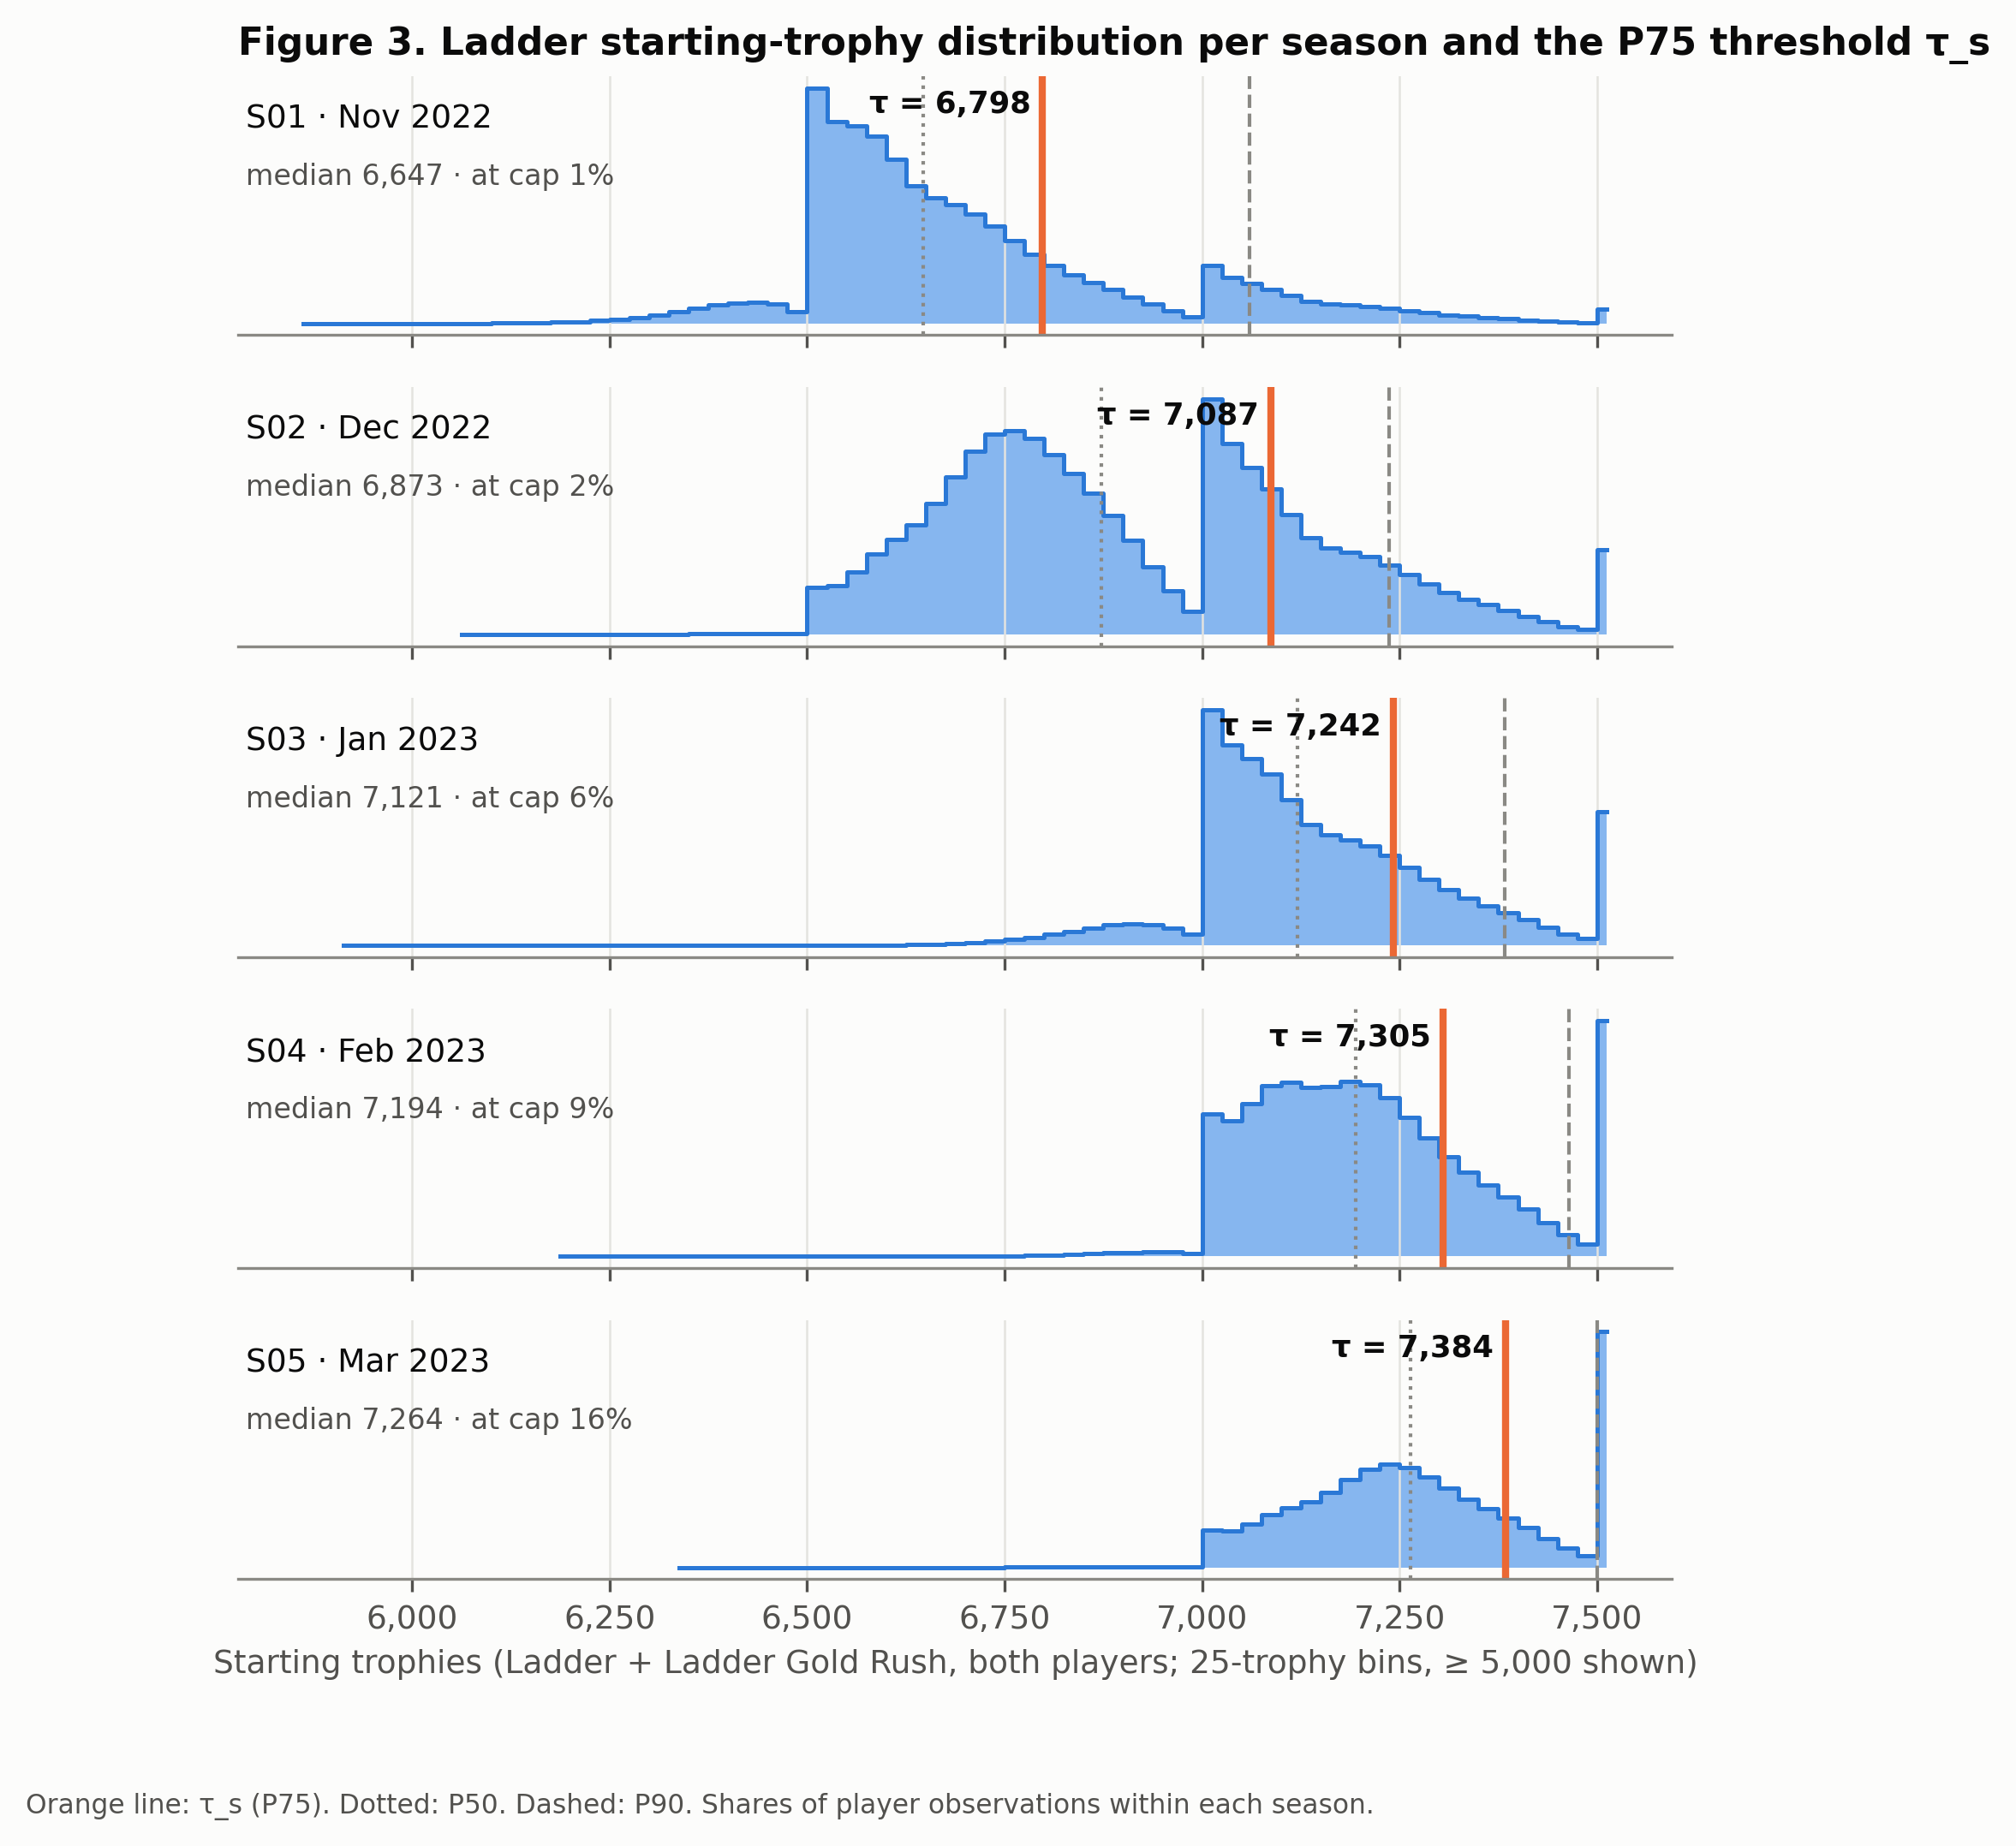

In [28]:
# Figure 3: ladder trophy distribution and tau_s per season
trophy_hist = to_pandas(
    ladder_trophies.filter("trophies >= 5000")
    .withColumn("bin", (F.floor(F.col("trophies") / 25) * 25).cast("int"))
    .groupBy("season_id", "bin").count()).sort_values(["season_id", "bin"])
fig, axes = plt.subplots(len(SEASON_IDS), 1, figsize=(7.2, 7.6), sharex=True)
for ax, sid in zip(axes, SEASON_IDS):
    hist = trophy_hist[trophy_hist.season_id == sid]
    density = hist["count"] / hist["count"].sum()
    ax.fill_between(hist.bin + 12.5, density, step="mid", color=RAMP["250"],
                    linewidth=0)
    ax.plot(hist.bin + 12.5, density, drawstyle="steps-mid", color=C1,
            linewidth=1.2)
    row = thresholds.set_index("season_id").loc[sid]
    for quantile, style in [("p50", ":"), ("p90", "--")]:
        ax.axvline(row[quantile], color=MUTED, linestyle=style, linewidth=1)
    ax.axvline(row["tau"], color=C2, linewidth=2)
    ax.text(row["tau"] - 15, ax.get_ylim()[1] * 0.85,
            f"τ = {int(row['tau']):,}", color=INK, ha="right", fontsize=8.5,
            fontweight="semibold")
    ax.text(0.005, 0.80, f"{sid} · {SEASON_LABEL[sid]}",
            transform=ax.transAxes, fontsize=9, color=INK)
    ax.text(0.005, 0.58, f"median {int(row['p50']):,} · at cap "
            f"{row['share_at_cap']:.0%}", transform=ax.transAxes, fontsize=8,
            color=INK2)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
axes[0].set_title("Figure 3. Ladder starting-trophy distribution per season "
                  "and the P75 threshold τ_s")
axes[-1].set_xlabel("Starting trophies (Ladder + Ladder Gold Rush, both "
                    "players; 25-trophy bins, ≥ 5,000 shown)")
axes[-1].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
fig.text(0.01, -0.01, "Orange line: τ_s (P75). Dotted: P50. Dashed: P90. "
         "Shares of player observations within each season.", fontsize=7.5,
         color=INK2)
show_figure(fig, "fig3_seasonal_trophy_thresholds.png", width=720)

**Figure 3.** Distribution of ladder starting trophies per season (shares of
player observations, 25-trophy bins). The orange line marks τ_s, the season's
75th percentile. The whole distribution moves right each month, and a growing
mass piles up at the 7,500 cap.

**Trophies inflate steadily.** The ladder median rises from 6,647 (Nov 2022) to
7,264 (Mar 2023). The share of players at the 7,500 cap grows from 0.6% to 16.3%
(Table 7, Figure 3).

**A fixed cut-off selects a changing population.** A static "both players ≥
7,000" rule would keep **14.7%** of ladder battles in November but **99.5%** in
March, comparing a top slice with almost everyone. τ_s rises with the
distribution (6,798 → 7,087 → 7,242 → 7,305 → 7,384) and keeps a stable **20–22%**
of ladder battles in every season. This makes the seasons comparable.

**Effect of the filters.** The filtering funnel (Table 8) shows how the 193.9 M
raw rows shrink to **12.28 M** high-trophy, non-tie battles. Nearly all of the
reduction comes from the trophy threshold, which is intended. Data-quality
filters remove only the 1.4% of rows that are exact duplicates.

### 10.2 Popularity is only weakly related to winning (Figure 4, Table 10)

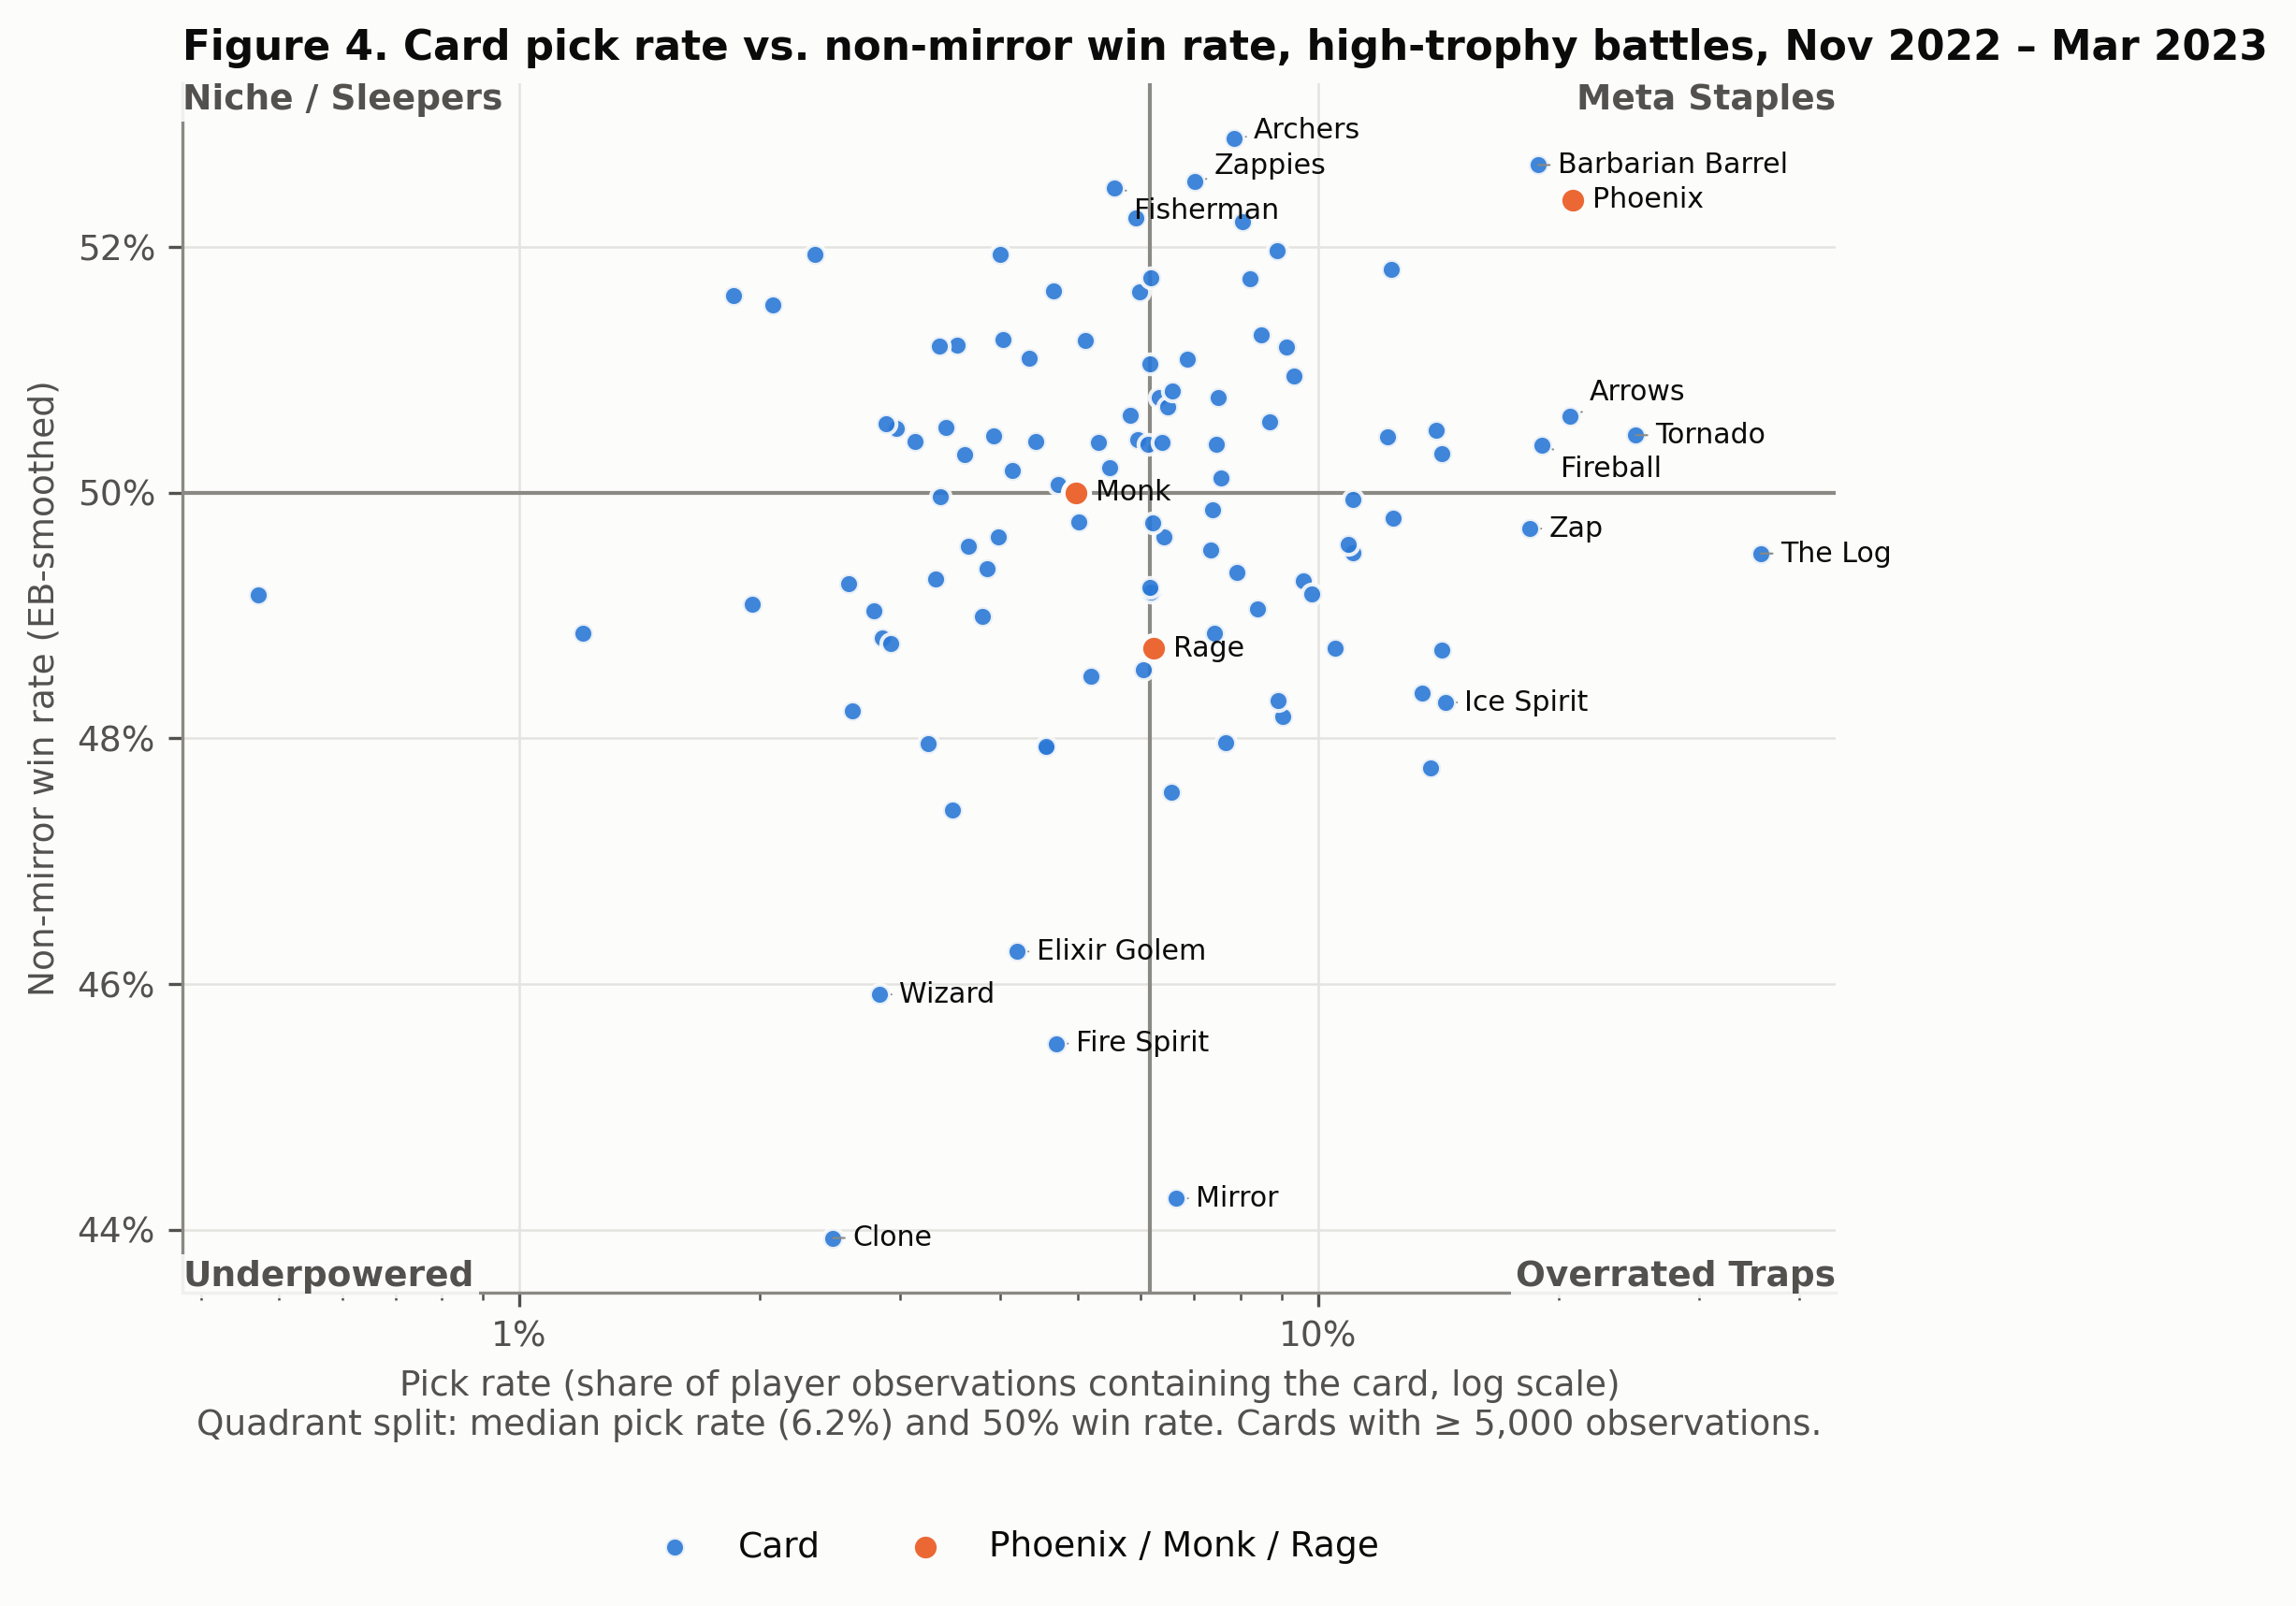

In [29]:
# Figure 4: card pick rate vs EB win rate (all seasons pooled)
cards_pooled = card_metrics[(card_metrics.season_id == "ALL")
                            & (card_metrics.obs >= 5000)].copy()
x_split, y_split = cards_pooled.pick_rate.median(), 0.5
fig, ax = plt.subplots(figsize=(7.6, 5.6))
is_focus = cards_pooled.card_id.isin(FOCUS_CARDS)
ax.scatter(cards_pooled.pick_rate[~is_focus], cards_pooled.wr_eb[~is_focus],
           s=26, color=C1, edgecolor=SURF, linewidth=1, alpha=0.9, zorder=3,
           label="Card")
ax.scatter(cards_pooled.pick_rate[is_focus], cards_pooled.wr_eb[is_focus],
           s=46, color=C2, edgecolor=SURF, linewidth=1.2, zorder=4,
           label="Phoenix / Monk / Rage")
ax.set_xscale("log")
ax.axvline(x_split, color=MUTED, linewidth=1)
ax.axhline(y_split, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
x_lim, y_lim = ax.get_xlim(), ax.get_ylim()
quadrants = [("Meta Staples", x_lim[1], y_lim[1], "right", "top"),
             ("Overrated Traps", x_lim[1], y_lim[0], "right", "bottom"),
             ("Niche / Sleepers", x_lim[0], y_lim[1], "left", "top"),
             ("Underpowered", x_lim[0], y_lim[0], "left", "bottom")]
for text, x, y, h_align, v_align in quadrants:
    ax.text(x, y, text, ha=h_align, va=v_align, fontsize=9, color=INK2,
            fontweight="semibold", zorder=6,
            bbox=dict(boxstyle="square,pad=0.15", facecolor=SURF,
                      edgecolor="none", alpha=0.9))
labelled = pd.concat([cards_pooled.nlargest(8, "pick_rate"),
                      cards_pooled.nlargest(5, "wr_eb"),
                      cards_pooled.nsmallest(5, "wr_eb"),
                      cards_pooled[is_focus]]).drop_duplicates("card_id")
labels = [ax.annotate(row.card_name, (row.pick_rate, row.wr_eb),
                      xytext=(5, 0), textcoords="offset points",
                      fontsize=7.2, color=INK, va="center",
                      arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5,
                                      shrinkA=0, shrinkB=3))
          for _, row in labelled.iterrows()]
declutter(ax, labels)
ax.set_xlabel("Pick rate (share of player observations containing the card, "
              "log scale)\nQuadrant split: median pick rate "
              f"({x_split:.1%}) and 50% win rate. Cards with ≥ 5,000 "
              "observations.")
ax.set_ylabel("Non-mirror win rate (EB-smoothed)")
ax.set_title("Figure 4. Card pick rate vs. non-mirror win rate, high-trophy "
             "battles, Nov 2022 – Mar 2023")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
show_figure(fig, "fig4_card_pick_vs_win_quadrants.png", width=760)

In [30]:
# Headline statistics quoted in Sections 10.2–10.6
cards_all = card_metrics[card_metrics.season_id == "ALL"]
rho_cards = stats.spearmanr(cards_all.pick_rate, cards_all.wr_eb)
decks_all = deck_board[(deck_board.season_id == "ALL")
                       & (deck_board.nm_matches >= CLASS_MIN_MATCHES)]
rho_decks = stats.spearmanr(decks_all.pick_rate, decks_all.wr_eb)
top_raw = deck_board[deck_board.season_id == "ALL"].nsmallest(20,
                                                              "raw_wr_rank")
win_scores = to_pandas(obs.filter("win = 1")
                       .groupBy("crowns", "opp_crowns").count())
win_scores["share"] = win_scores["count"] / win_scores["count"].sum()
headline = pd.DataFrame([
    ("Cards: Spearman ρ(pick rate, EB WR)", f"{rho_cards.statistic:.3f}",
     f"n = {len(cards_all)} cards, p = {rho_cards.pvalue:.2f}"),
    ("Decks ≥ 200 matches: Spearman ρ(pick rate, EB WR)",
     f"{rho_decks.statistic:.3f}", f"n = {len(decks_all):,} decks"),
    ("Top-20 raw-WR decks: median non-mirror matches",
     f"{top_raw.nm_matches.median():.0f}", "decks with ≥ 50 observations"),
    ("Top-20 raw-WR decks: median EB rank", f"{top_raw.eb_rank.median():.0f}",
     "rank after shrinkage"),
    ("Wins ending 1–0", pct(win_scores.set_index(["crowns", "opp_crowns"])
                            .share.get((1, 0), np.nan)), "all seasons"),
], columns=["statistic", "value", "note"])
caption(17, "Headline statistics quoted in Sections 10 and 12, computed "
        "on the pooled analysis sample.")
headline

Table 17. Headline statistics quoted in Sections 10 and 12, computed on the pooled analysis sample.


,statistic,value,note
0,"Cards: Spearman ρ(pick rate, EB WR)",0.107,"n = 109 cards, p = 0.27"
1,"Decks ≥ 200 matches: Spearman ρ(pick rate, EB WR)",0.132,"n = 11,253 decks"
2,Top-20 raw-WR decks: median non-mirror matches,62,decks with ≥ 50 observations
3,Top-20 raw-WR decks: median EB rank,90,rank after shrinkage
4,Wins ending 1–0,65.4%,all seasons


**Figure 4.** Each dot is one card with at least 5,000 observations, pooled over
all five seasons. The x-axis is the pick rate (log scale), and the y-axis is the
Empirical-Bayes non-mirror win rate. The grey lines split the plot at the median
pick rate and at 50%. Orange dots mark the three focus cards.

**Weak overall association.** Across 109 cards, the Spearman ρ between pick rate
and smoothed win rate is only **0.11** (Table 17). Across 11,253 decks with at
least 200 matches it is **0.13**. Popularity is a poor guide to winning.

**The most-picked cards are not the strongest.** The Log (35.8% of observations)
wins **49.5%** of its non-mirror games. Ice Spirit, Hog Rider, Skeletons and
Valkyrie (13–14% pick) all sit below 49%, in the lower-right *Overrated Traps*
quadrant of Figure 4. Phoenix (20.8%, 52.4%) and Barbarian Barrel (18.9%, 52.7%)
are the popular cards that also win: the *Meta Staples*.

**Mirror matches matter.** Popular cards often face themselves. 36% of The Log's
observations are against another Log (Table 10). Those games always split 50/50,
so leaving them in pulls staples' win rates toward 50%. The non-mirror correction
separates the cards' actual performance.

### 10.3 Small samples dominate raw deck leaderboards (Table 17)
* **Raw leaders are thin.** The 20 decks with the highest raw win rate (among
  decks with at least 50 observations) have a median of only **62** matches.
  After Empirical-Bayes shrinkage their median rank is **90** (Table 17), so
  most of them were lucky streaks rather than strong decks.
* **Win rates spread out later in the period.** The fitted prior strength M
  falls from about 210–270 pseudo-matches (Nov–Dec) to about 27–34 (Feb–Mar)
  (Table 13). Deck win rates are more spread out late in the period, so less
  shrinkage is applied.
* **Selection effect.** The deck prior mean (0.503–0.517) is above 50%. Decks
  played often enough to reach 100 matches tend to beat the long tail of rare
  decks.

### 10.4 Breadth vs. specialisation (Figure 5, Table 11)

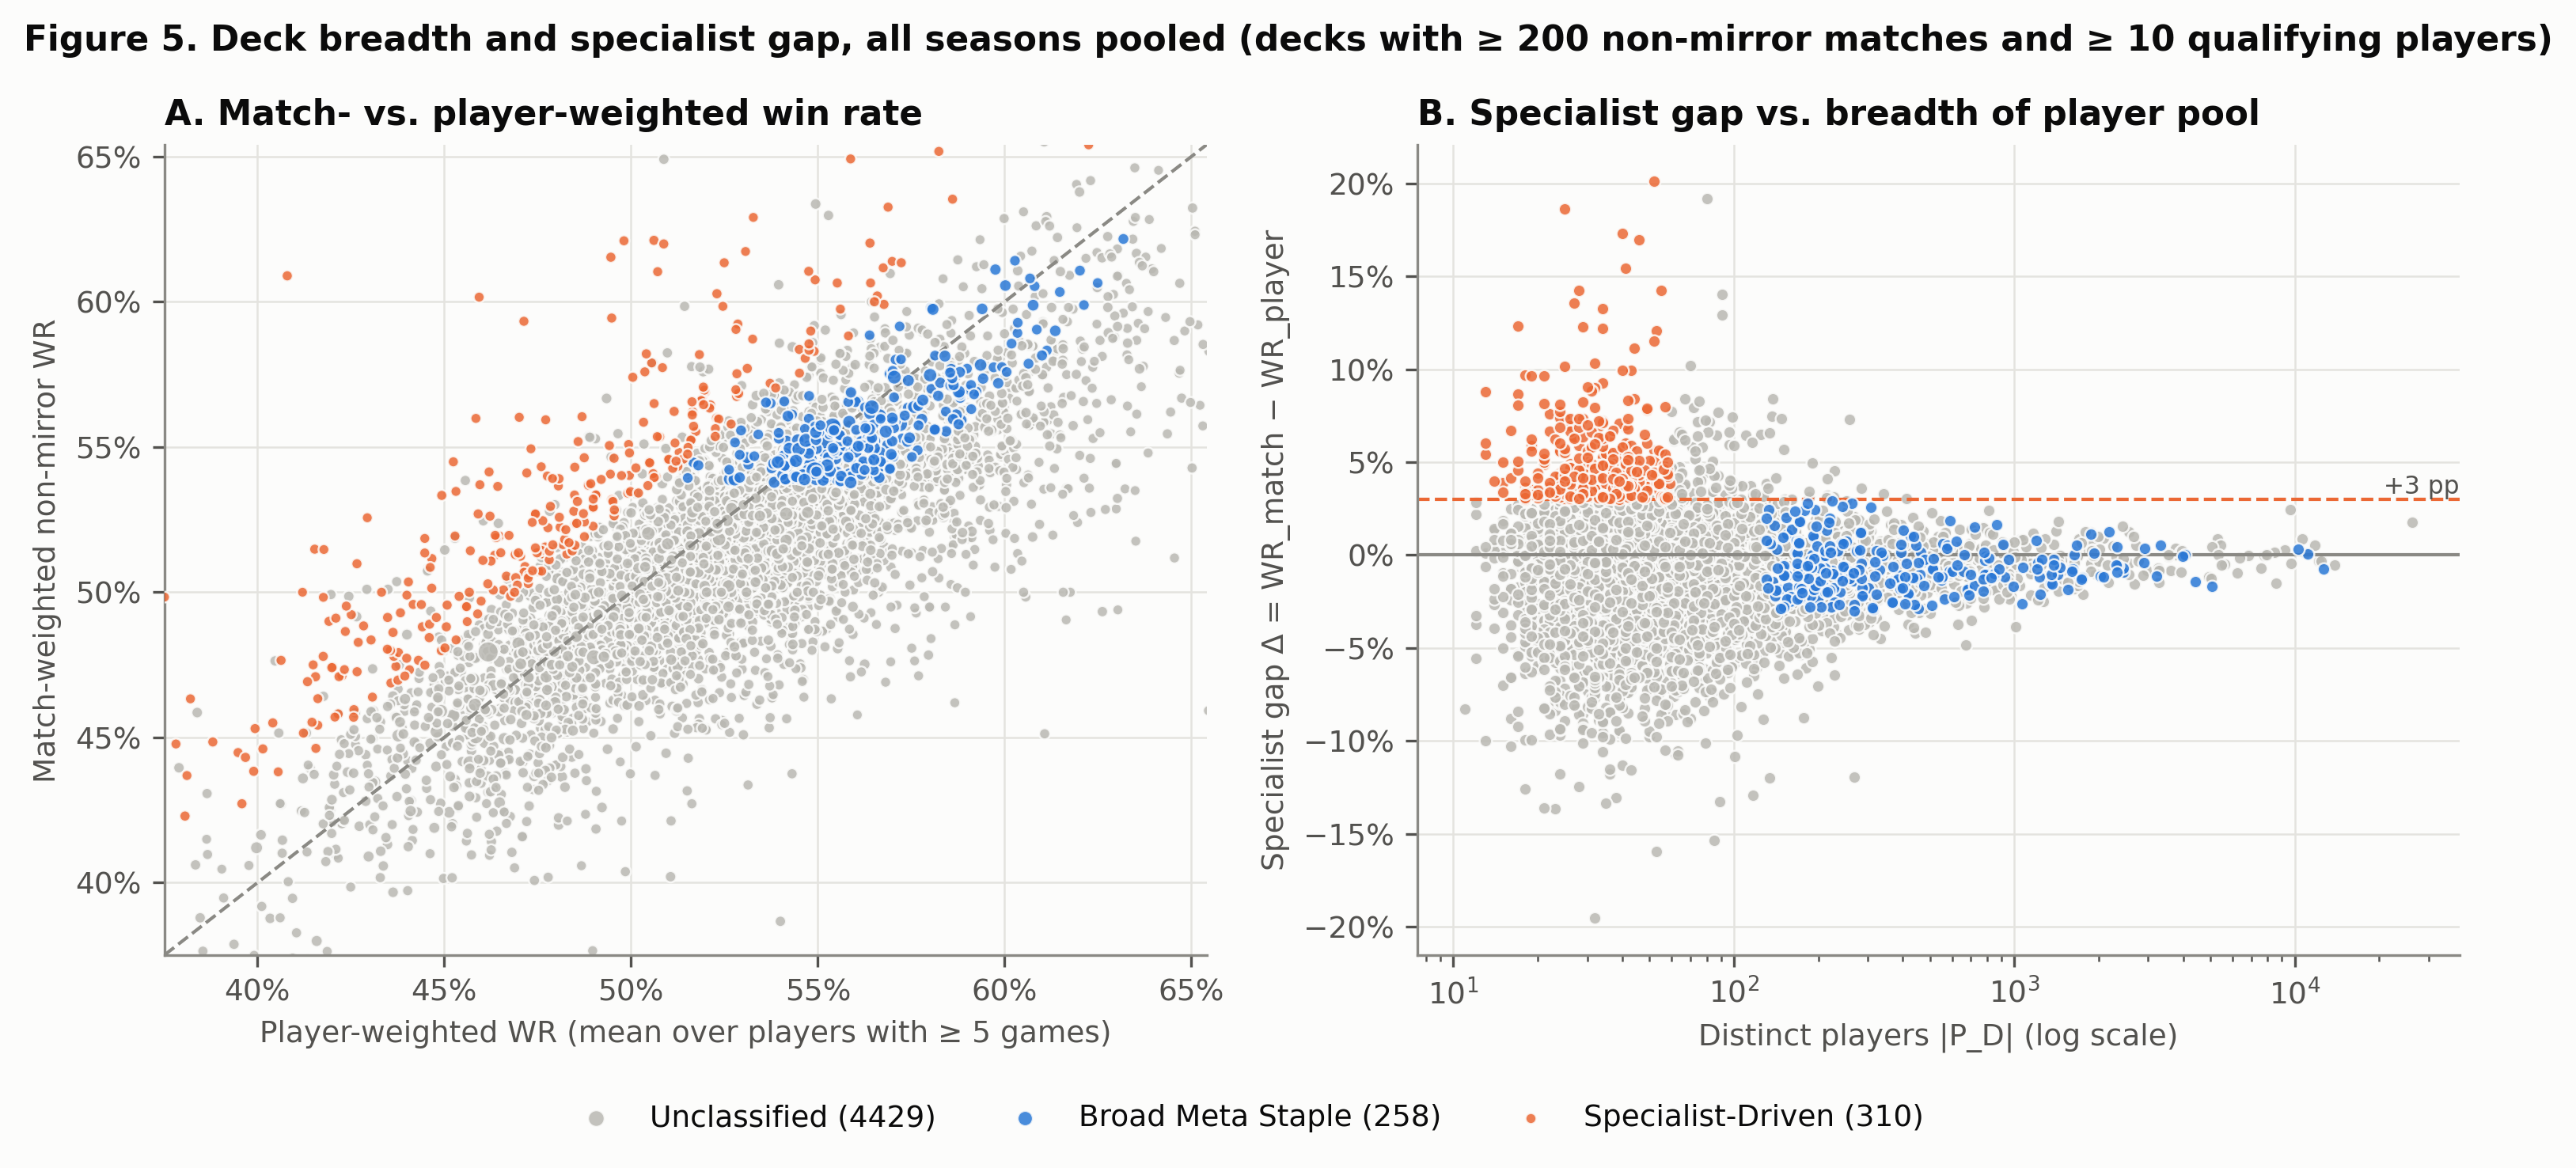

In [31]:
# Figure 5: deck breadth and specialist gap (all seasons pooled)
decks_classified = deck_board[(deck_board.season_id == "ALL")
                              & (deck_board.deck_class
                                 != "Insufficient sample")].copy()
class_colour = {"Broad Meta Staple": C1, "Specialist-Driven": C2,
                "Unclassified": "#b9b8b2"}
fig, (ax_wr, ax_gap) = plt.subplots(1, 2, figsize=(10.5, 4.6))
max_players = decks_classified.distinct_players.max()
for label in ["Unclassified", "Broad Meta Staple", "Specialist-Driven"]:
    group = decks_classified[decks_classified.deck_class == label]
    layer = 2 if label == "Unclassified" else 3
    ax_wr.scatter(group.wr_player, group.wr_match,
                  s=10 + 30 * np.sqrt(group.distinct_players / max_players),
                  color=class_colour[label], edgecolor=SURF, linewidth=0.6,
                  alpha=0.85, label=f"{label} ({len(group)})", zorder=layer)
    ax_gap.scatter(group.distinct_players, group.specialist_gap, s=14,
                   color=class_colour[label], edgecolor=SURF, linewidth=0.6,
                   alpha=0.85, zorder=layer)
low, high = np.nanpercentile(np.r_[decks_classified.wr_player,
                                   decks_classified.wr_match], [0.5, 99.5])
ax_wr.plot([low, high], [low, high], color=MUTED, linewidth=1,
           linestyle="--")
ax_wr.set_xlim(low, high)
ax_wr.set_ylim(low, high)
ax_wr.set_xlabel("Player-weighted WR (mean over players with ≥ 5 games)")
ax_wr.set_ylabel("Match-weighted non-mirror WR")
ax_wr.set_title("A. Match- vs. player-weighted win rate")
ax_wr.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax_wr.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax_gap.set_xscale("log")
ax_gap.axhline(SPEC_GAP, color=C2, linewidth=1, linestyle="--")
ax_gap.axhline(0, color=MUTED, linewidth=1)
ax_gap.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax_gap.set_xlabel("Distinct players |P_D| (log scale)")
ax_gap.set_ylabel("Specialist gap Δ = WR_match − WR_player")
ax_gap.set_title("B. Specialist gap vs. breadth of player pool")
ax_gap.text(ax_gap.get_xlim()[1], SPEC_GAP, " +3 pp", va="bottom",
            ha="right", fontsize=7.5, color=INK2)
fig.legend(*ax_wr.get_legend_handles_labels(), loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Figure 5. Deck breadth and specialist gap, all seasons pooled "
             f"(decks with ≥ {CLASS_MIN_MATCHES} non-mirror matches and ≥ "
             f"{CLASS_MIN_PLAYERS} qualifying players)", x=0.01, ha="left",
             fontsize=10.5, fontweight="semibold")
fig.tight_layout()
show_figure(fig, "fig5_deck_breadth_specialist_gap.png")

In [32]:
# Specialist gap by size of player pool (eligible pooled decks)
pool_bins = pd.cut(decks_classified.distinct_players,
                   [0, decks_classified.distinct_players.median(), 200, 1000,
                    np.inf])
gap_by_pool = (decks_classified.groupby(pool_bins, observed=True)
               .specialist_gap
               .agg(decks="count", mean_gap="mean", std_gap="std",
                    share_gap_above_3pp=lambda g: (g > SPEC_GAP).mean(),
                    share_gap_below_minus_3pp=lambda g: (g < -SPEC_GAP)
                    .mean()))
gap_by_pool.index = gap_by_pool.index.astype(str).rename("distinct_players")
rho_gap_pool = stats.spearmanr(decks_classified.distinct_players,
                               decks_classified.specialist_gap)
large_gap = decks_classified[decks_classified.specialist_gap > SPEC_GAP]
largest_pool = large_gap.distinct_players.max()
print(f"Table 18. Specialist gap by player-pool size (pooled decks). "
      f"Spearman rho(pool, gap) = {rho_gap_pool.statistic:.3f}; decks with "
      f"gap > +3 pp: {len(large_gap)}, largest pool {largest_pool:,}")
gap_by_pool.round(4)

Table 18. Specialist gap by player-pool size (pooled decks). Spearman rho(pool, gap) = 0.003; decks with gap > +3 pp: 405, largest pool 413


,decks,mean_gap,std_gap,share_gap_above_3pp,share_gap_below_minus_3pp
distinct_players,,,,,
"(0.0, 59.0]",2505,-0.0093,0.0375,0.1238,0.2739
"(59.0, 200.0]",1619,-0.0114,0.0286,0.0525,0.2162
"(200.0, 1000.0]",697,-0.0078,0.0160,0.0143,0.0703
"(1000.0, inf]",176,-0.0038,0.0093,0.0000,0.0057


**Figure 5.** (A) Each dot is a deck with at least 200 non-mirror matches and at
least 10 qualifying players. The x-axis is the player-weighted win rate and the
y-axis the match-weighted win rate. Dot size grows with the player pool. Dots
above the dashed diagonal win more per match than per player. (B) The specialist
gap against the number of distinct players. The dashed orange line marks the
+3 pp threshold.

**Classes.** Of 4,997 pooled decks with enough data, **310 are
Specialist-Driven** and **258 are Broad Meta Staples** (Table 11).

**Large gaps are a small-pool phenomenon.** The size of a deck's player pool
predicts how *variable* its specialist gap is, not which direction it goes
(Spearman ρ(pool size, gap) ≈ 0.00, Table 18):
* **Spread shrinks with pool size.** The standard deviation of the gap falls
  from 3.7 pp for decks with at most 59 pilots to 0.9 pp for decks with more
  than 1,000.
* **Large positive gaps occur only in small pools.** 12% of small-pool decks
  have a gap above +3 pp, against **none** of the 176 decks with more than
  1,000 pilots. The largest pool with such a gap has 413 pilots.
* **The typical gap is slightly negative** (about −1 pp). Players with at least
  5 games on a deck do a little better than the deck's overall match record,
  which includes casual one-off pilots.

**Interpretation.**
* A large gap in a small pool is partly a few dedicated experts and partly
  sampling noise. Raising the qualifying floor to 10 games cuts the number of
  Specialist-Driven decks from 310 to 76 (Section 11).
* **The robust finding:** for widely played decks, the win rate is a property
  of the deck, not of a handful of pilots.
* **The practical rule:** distrust a high win rate that rests on fewer than a
  few hundred pilots.

### 10.5 Deck families and crown margins (Figure 6, Table 12)

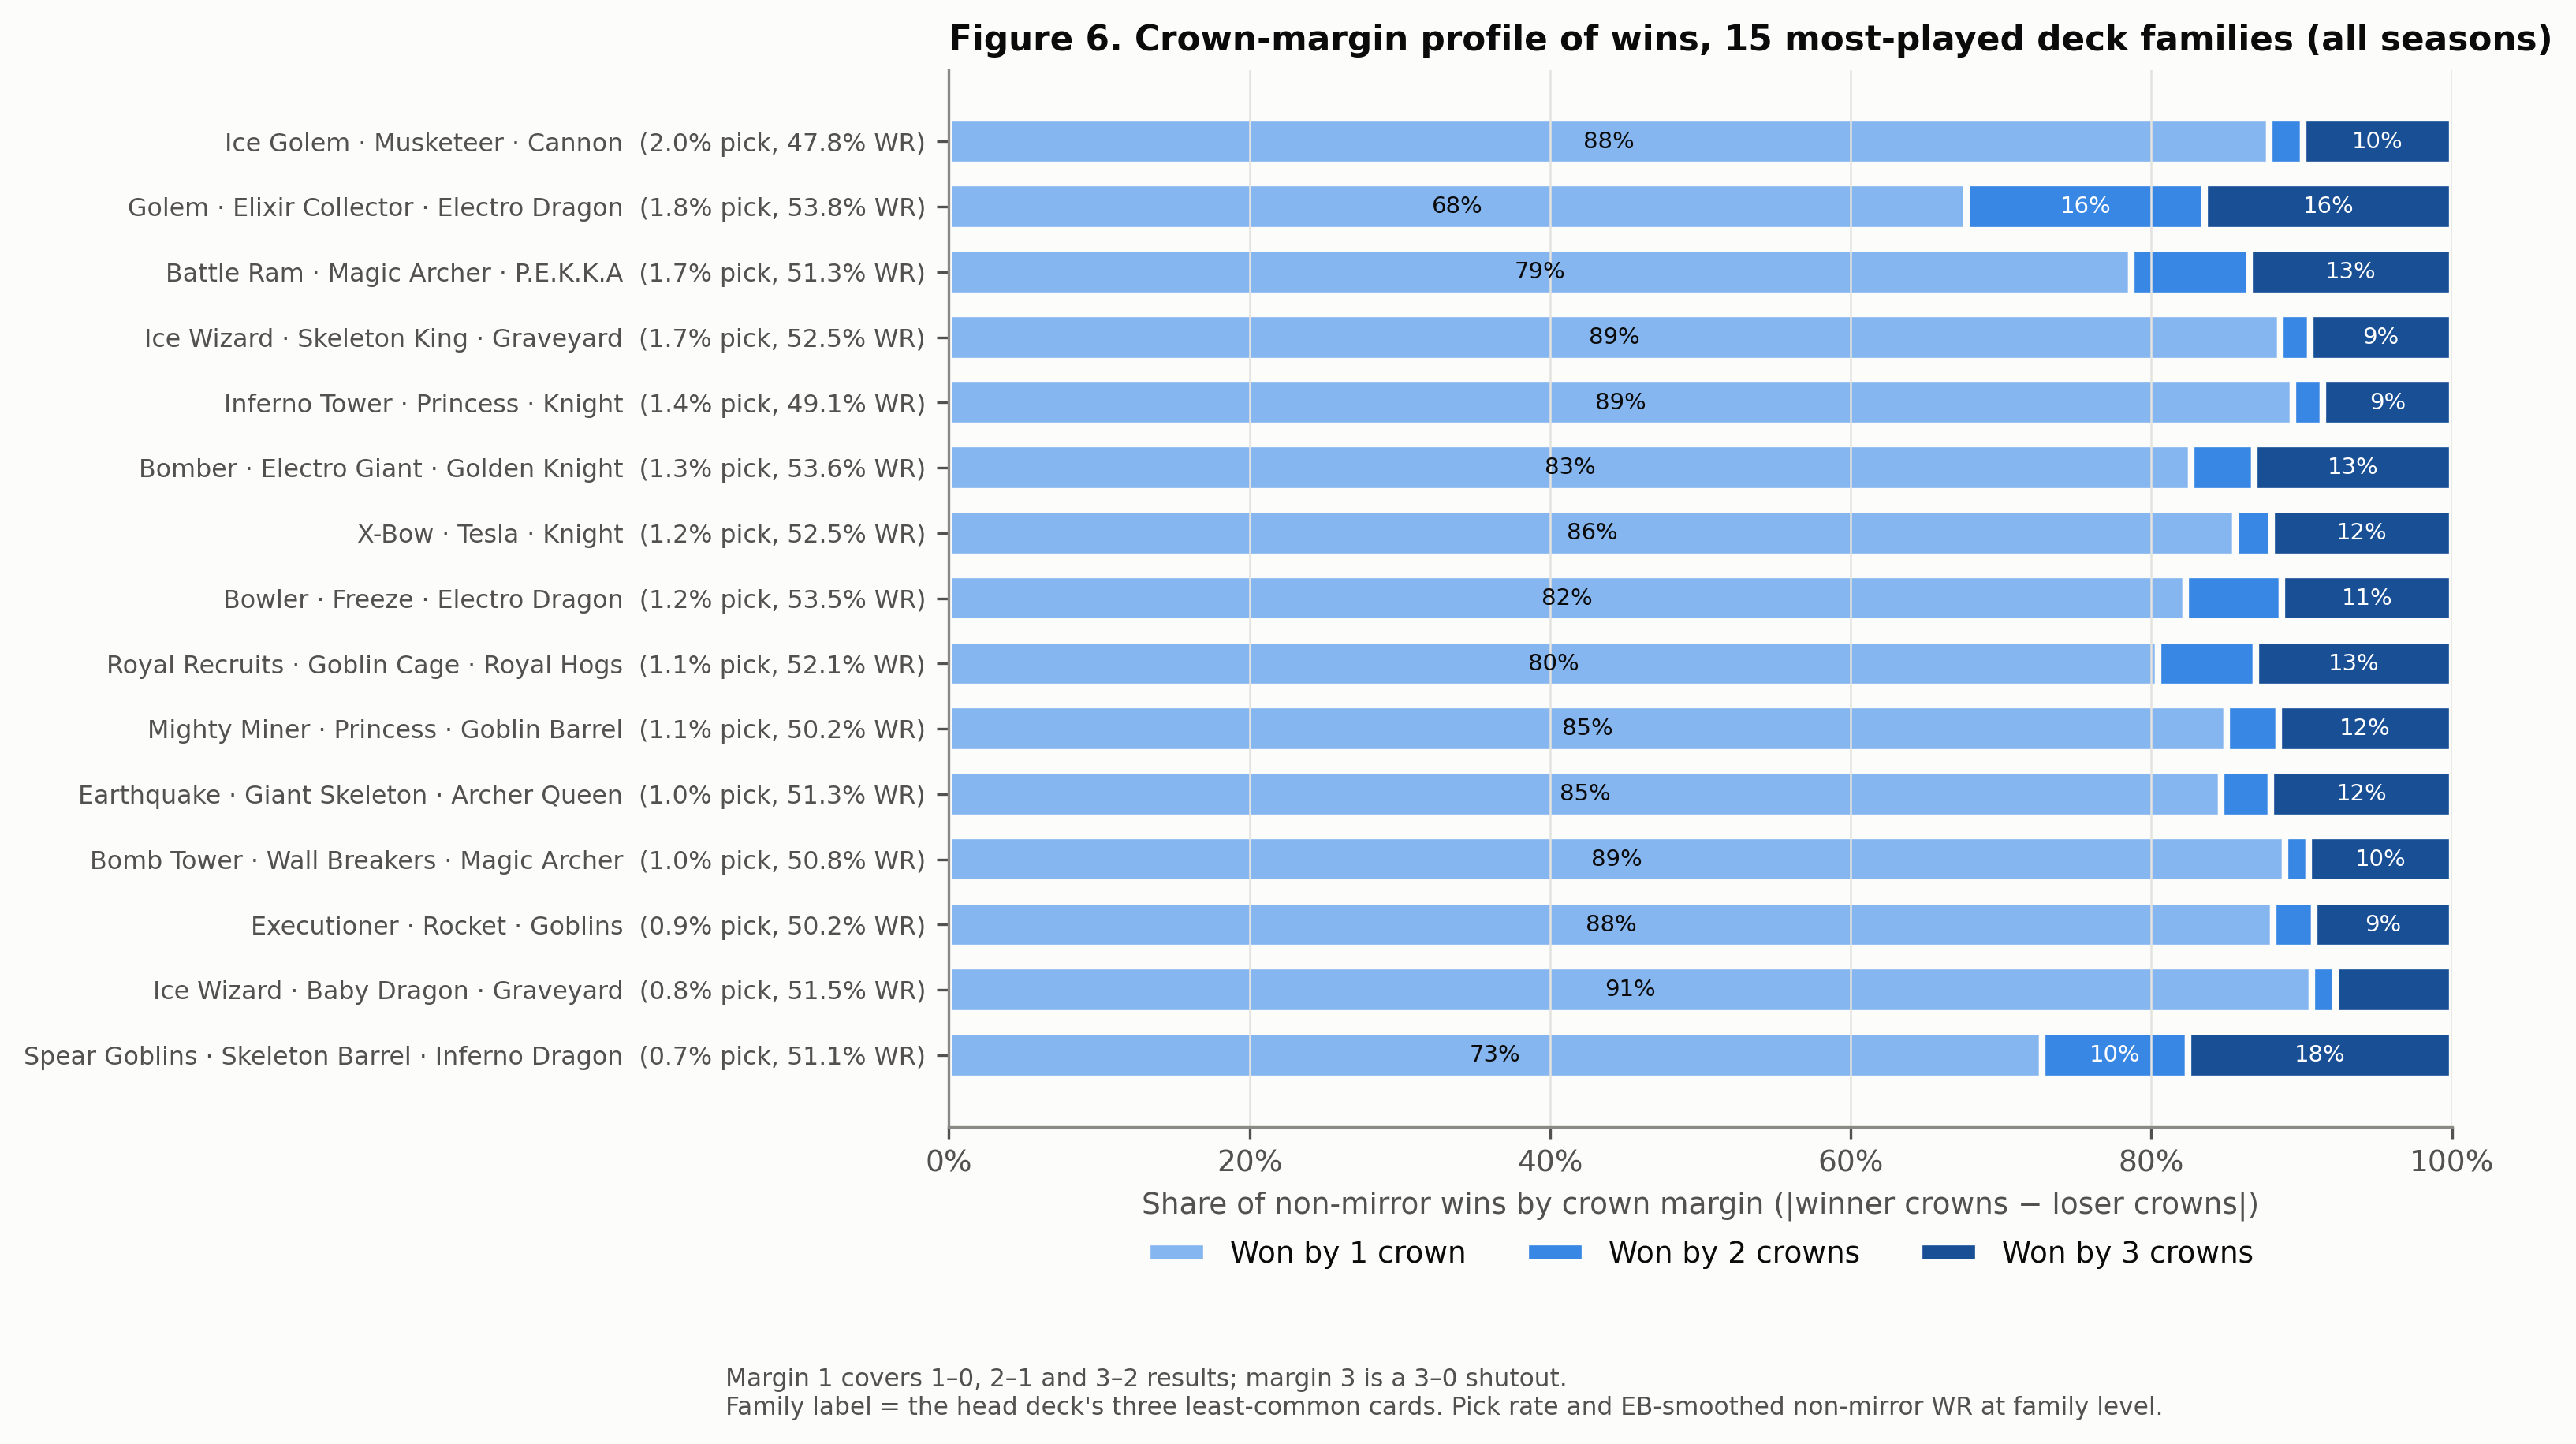

In [33]:
# Figure 6: crown-margin profiles of the 15 most-played families
top_families = (family_summary[family_summary.season_id == "ALL"]
                .nlargest(15, "pick_rate").iloc[::-1])
fig, ax = plt.subplots(figsize=(8.2, 5.8))
left = np.zeros(len(top_families))
for k, colour in zip((1, 2, 3), (RAMP["250"], RAMP["400"], RAMP["600"])):
    shares = top_families[f"win_{k}crown_pct"].values
    ax.barh(range(len(top_families)), shares, left=left, color=colour,
            edgecolor=SURF, linewidth=2, height=0.72,
            label=f"Won by {k} crown{'s' if k > 1 else ''}")
    for i, (start, share) in enumerate(zip(left, shares)):
        if share >= 0.08:
            ax.text(start + share / 2, i, f"{share:.0%}", ha="center",
                    va="center", fontsize=7,
                    color=INK if k == 1 else "#ffffff")
    left += shares
ax.set_yticks(range(len(top_families)),
              [f"{label}  ({pick:.1%} pick, {wr:.1%} WR)"
               for label, pick, wr in zip(top_families.family_label,
                                          top_families.pick_rate,
                                          top_families.wr_eb)],
              fontsize=7.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of non-mirror wins by crown margin "
              "(|winner crowns − loser crowns|)")
ax.set_title("Figure 6. Crown-margin profile of wins, 15 most-played deck "
             "families (all seasons)")
ax.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.16))
fig.text(0.01, -0.10, "Margin 1 covers 1–0, 2–1 and 3–2 results; margin 3 is "
         "a 3–0 shutout.\nFamily label = the head deck's three least-common "
         "cards. Pick rate and EB-smoothed non-mirror WR at family level.",
         fontsize=7.5, color=INK2)
show_figure(fig, "fig6_crown_margin_profiles.png", width=800)

**Figure 6.** For the 15 most-played deck families, pooled over all seasons, each
bar splits the family's non-mirror wins by crown margin: light (margin 1), mid
(2) and dark (3). The labels show the family's pick rate and Empirical-Bayes win
rate.

**Families.** The 1.07 M distinct decks collapse into 740 K families, and the top
100 families cover 40% of observations. Transitive clustering would have merged
**80.5%** of seed-deck volume into a single component. The greedy head
assignment keeps the largest family at **2.0%**. That supports the
non-transitive design.

**Most wins are narrow.** 1–0 is by far the most common final score: **65%** of
all wins (Table 17). Margin-1 wins make up 68–91% of the wins of the top-15
families (Figure 6). The Golem / Elixir Collector beatdown family has the largest
share of 2- and 3-crown-margin wins (32%). That fits its play style, but the
observation is descriptive only.

### 10.6 Stability across seasons and the Nov → Dec break (Figure 7, Tables 14–16)

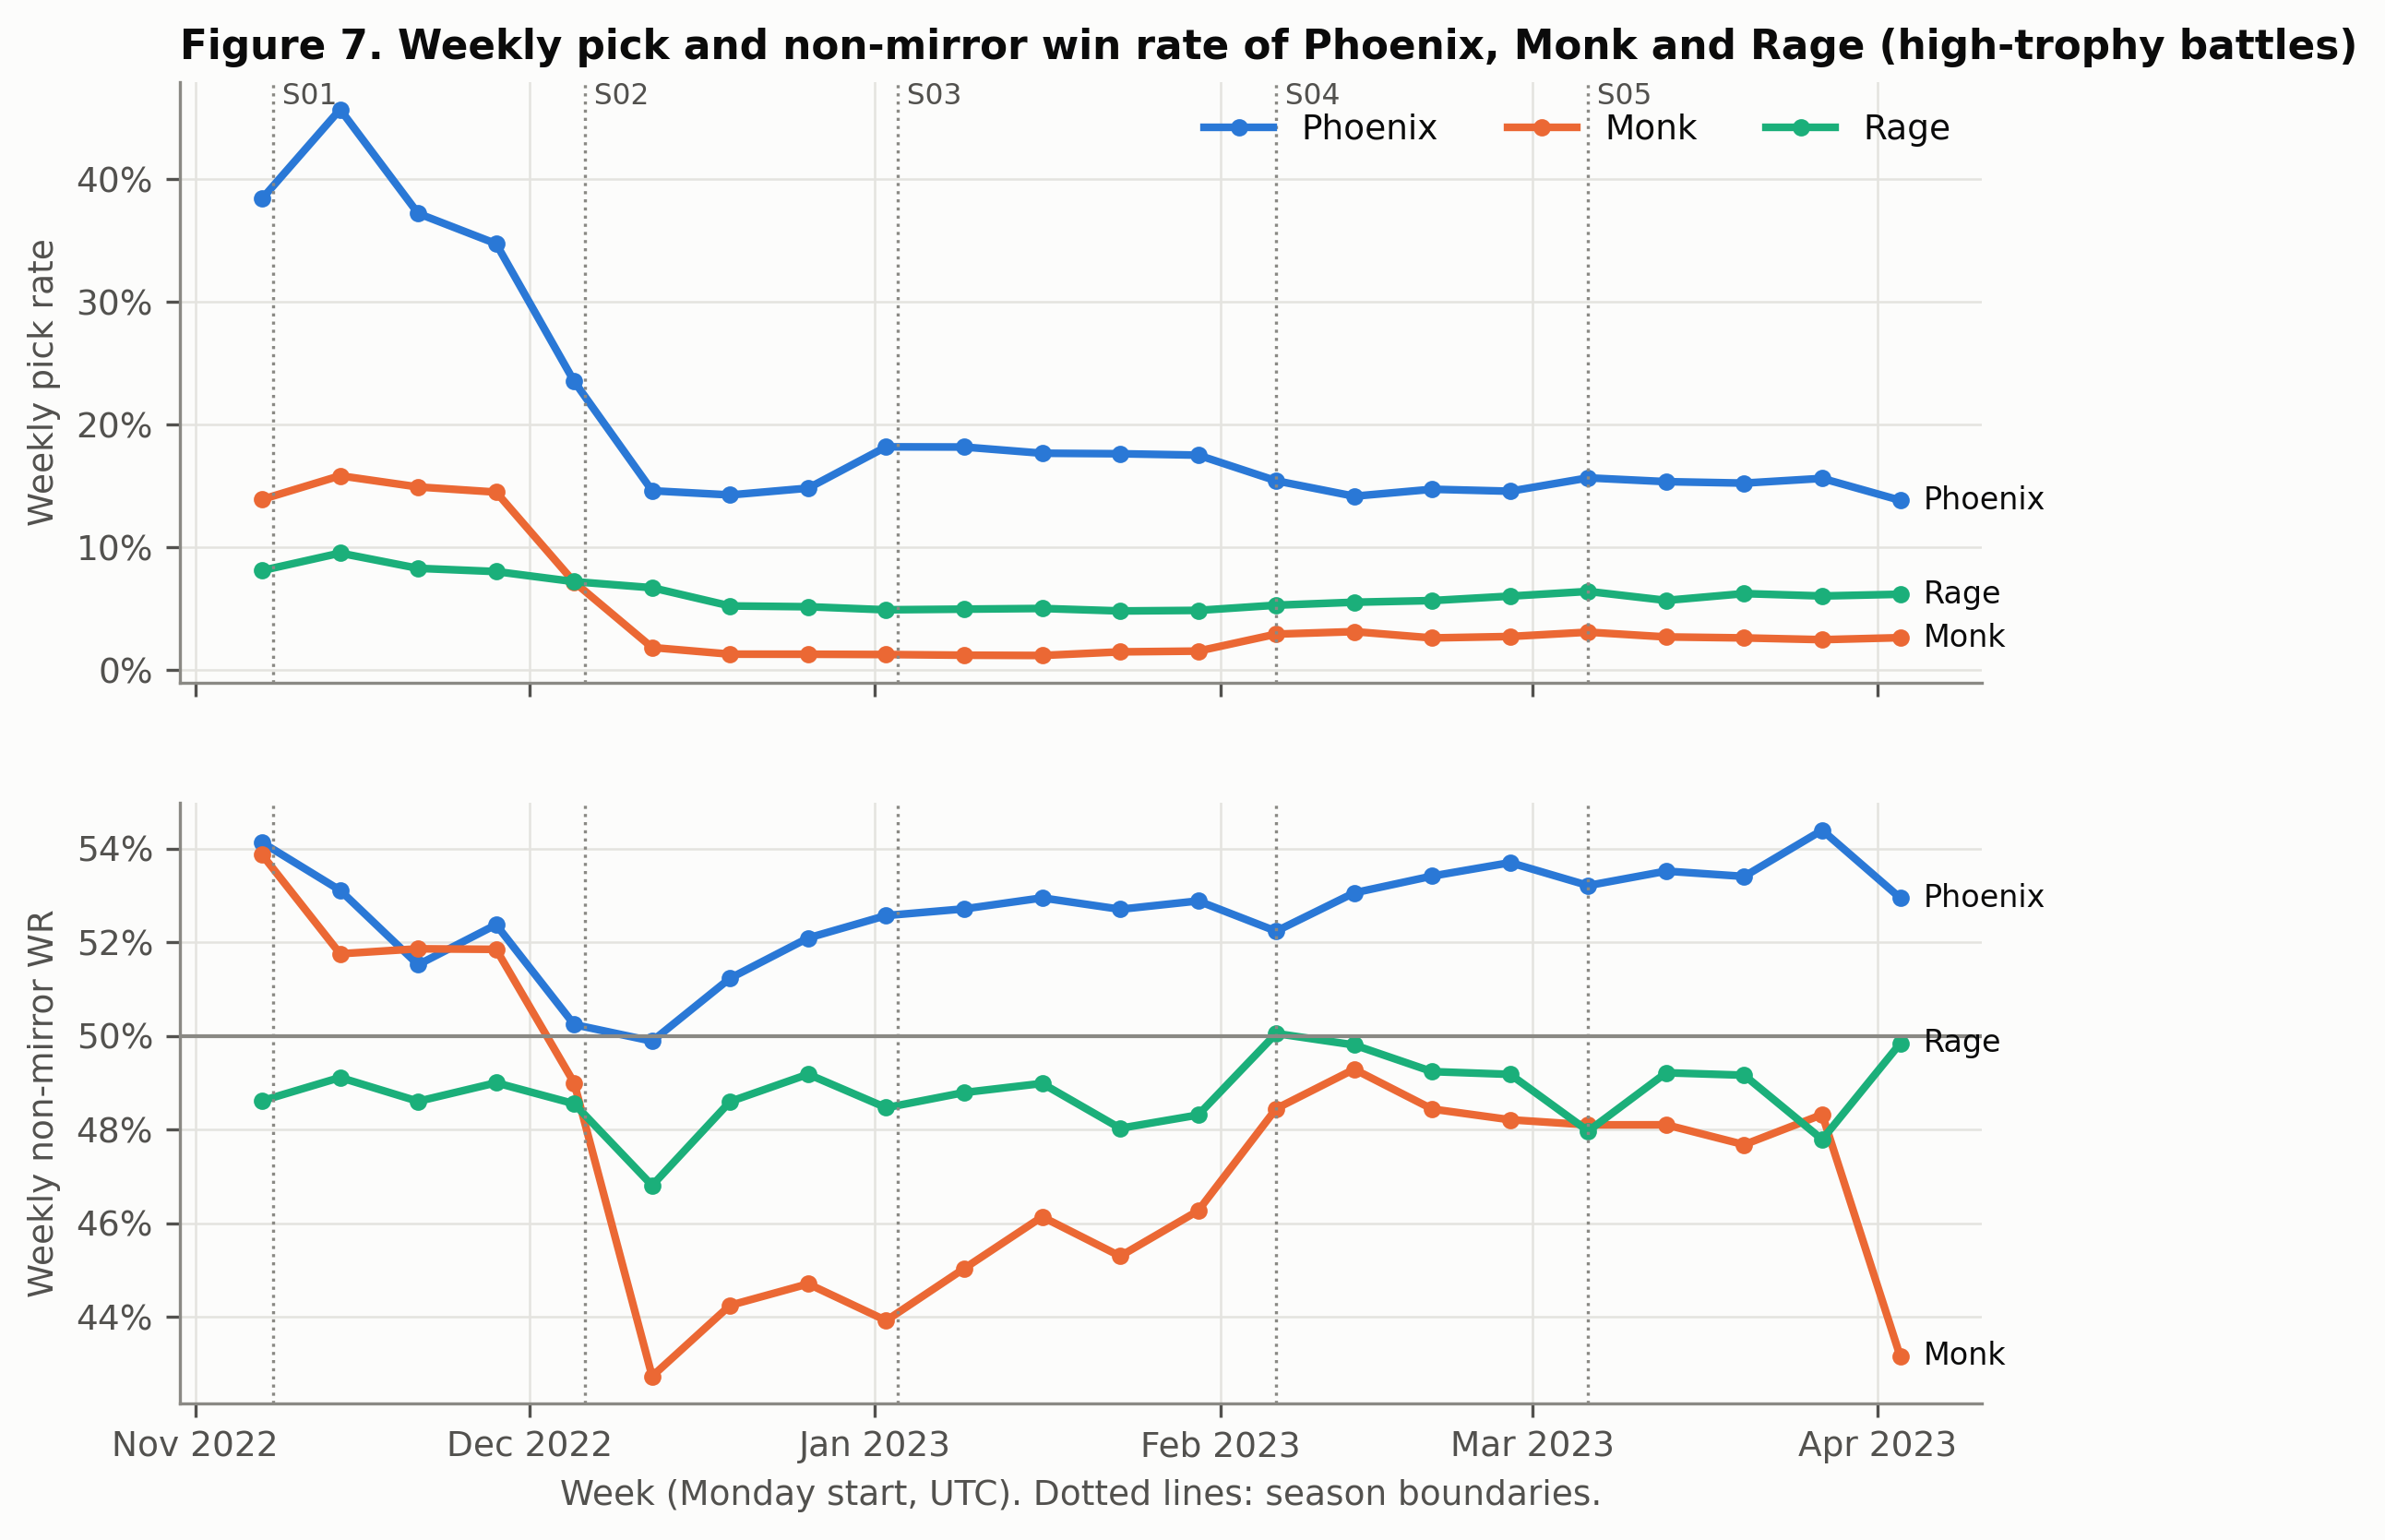

In [34]:
# Figure 7: weekly pick and win rate of Phoenix, Monk and Rage
fig, (ax_pick, ax_wr) = plt.subplots(2, 1, figsize=(8.4, 6.2), sharex=True)
pick_labels, wr_labels = [], []
for (card, name), colour in zip(FOCUS_CARDS.items(), (C1, C2, C3)):
    series = focus[focus.card_id == card]
    ax_pick.plot(series.week, series.pick_rate, color=colour, marker="o",
                 markersize=3.5, label=name)
    ax_wr.plot(series.week, series.wr_nonmirror, color=colour, marker="o",
               markersize=3.5, label=name)
    pick_labels.append(ax_pick.annotate(
        name, (series.week.iloc[-1], series.pick_rate.iloc[-1]),
        xytext=(6, 0), textcoords="offset points", va="center", fontsize=8,
        color=INK))
    wr_labels.append(ax_wr.annotate(
        name, (series.week.iloc[-1], series.wr_nonmirror.iloc[-1]),
        xytext=(6, 0), textcoords="offset points", va="center", fontsize=8,
        color=INK))
ax_wr.axhline(0.5, color=MUTED, linewidth=1)
for sid, (_, first_day, _) in SEASONS.items():
    for ax in (ax_pick, ax_wr):
        ax.axvline(pd.Timestamp(first_day), color=MUTED, linewidth=0.8,
                   linestyle=":")
    ax_pick.text(pd.Timestamp(first_day), 1.0, f" {sid}",
                 transform=ax_pick.get_xaxis_transform(), fontsize=7.5,
                 color=INK2, va="top")
for ax in (ax_pick, ax_wr):
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax_pick.set_ylabel("Weekly pick rate")
ax_wr.set_ylabel("Weekly non-mirror WR")
ax_wr.xaxis.set_major_locator(mdates.MonthLocator())
ax_wr.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
declutter(ax_pick, pick_labels)
declutter(ax_wr, wr_labels)
ax_pick.set_title("Figure 7. Weekly pick and non-mirror win rate of Phoenix, "
                  "Monk and Rage (high-trophy battles)")
ax_pick.legend(loc="upper right", ncol=3)
ax_wr.set_xlabel("Week (Monday start, UTC). Dotted lines: season "
                 "boundaries.")
show_figure(fig, "fig7_balance_patch_trajectories.png", width=820)

**Figure 7.** Weekly pick rate (top) and non-mirror win rate (bottom) of the three
focus cards. Weeks start on Monday (UTC). Dotted lines mark season starts. Weeks
with fewer than 1,000 high-trophy battles are omitted. The final point (3 Apr
2023) covers a single partial day.

**Card usage is persistent.** Adjacent-season Spearman ρ is 0.81–0.98 for card
pick rates, and 0.82–0.92 for card win rates except Nov → Dec, which is 0.58
(Table 14).

**Exact decks turn over faster.** Deck pick ρ is 0.66–0.76 and deck win-rate ρ is
0.39–0.67. Families sit in between, consistent with archetypes persisting while
individual card slots are swapped.

**November → December 2022 is the least stable transition** for every entity
and metric:
* **Monk** fell from 14.8% to 2.3% pick and from 51.9% to 45.1% win rate across
  the S01 → S02 boundary, and is classified a *Balance Casualty* (Table 16). Its
  win rate partly recovered from February.
* **Phoenix** peaked at about 45% weekly pick in mid-November. It started falling
  in the last week of S01, *before* the season boundary, and settled at 14–18%
  from December. Its win rate stayed above 50% in most weeks, so it remains a
  *Permanent Staple*.
* **Rage** drifted from 8.5% to 5–6% pick at a 48–50% win rate
  (*Stable / Other*).

The battle data alone cannot attribute these changes to specific balance
updates.

## 11. Sensitivity analysis: alternative design assumptions

Each main design choice was re-run under an alternative assumption to check that
the conclusions do not depend on it (Tables 19–22):

1. **Stricter trophy threshold.** Restrict the sample to battles where both
   players are at or above P80, or at or above P90, instead of P75. Recompute
   card pick rates and non-mirror win rates.
2. **Breadth floor.** Count a player toward `WR_player` from 10 games on the deck
   instead of 5.
3. **Shrinkage strength.** Replace the fitted prior with a fixed M = 200, and
   with no shrinkage at all.
4. **Including Crown Rush.** Count how many high-trophy battles the excluded
   Crown Rush modes would add, and compare their card metrics with the analysis
   sample.

In [35]:
# Sensitivity 1: stricter trophy thresholds (P80, P90)
def build_threshold_sensitivity():
    """Card pick/WR when both players are >= the season's P80 or P90."""
    battle_floor = obs.groupBy("season_id", "battle_id").agg(
        F.min("trophies").alias("floor_trophies"))
    with_floor = (obs.join(battle_floor, ["season_id", "battle_id"])
                  .join(tau_sdf, "season_id"))
    exploded = (with_floor.select("season_id", "win", "opp_cards", "p80",
                                  "p90", "floor_trophies",
                                  F.explode("cards").alias("card_id"))
                .withColumn("nm", (~F.array_contains("opp_cards",
                                                     F.col("card_id")))
                            .cast("int")))
    aggs = []
    for level in ("p80", "p90"):
        keep = (F.col("floor_trophies") >= F.col(level)).cast("int")
        aggs += [F.sum(keep).alias(f"obs_{level}"),
                 F.sum(keep * F.col("nm")).alias(f"nm_{level}"),
                 F.sum(keep * F.col("nm") * F.col("win"))
                 .alias(f"nmw_{level}")]
    cards_level = to_pandas(exploded.groupBy("season_id", "card_id")
                            .agg(*aggs))
    battles_level = to_pandas(with_floor.groupBy("season_id").agg(
        *[(F.sum((F.col("floor_trophies") >= F.col(level)).cast("long"))
           / 2).alias(f"battles_{level}") for level in ("p80", "p90")]))
    return cards_level.merge(battles_level, on="season_id")


threshold_sens = cached_table("sensitivity_thresholds",
                              build_threshold_sensitivity)
pooled_sens = threshold_sens.groupby("card_id", as_index=False).sum(
    numeric_only=True)
base = cards_all.set_index("card_id")
sens_rows = [("P75 (baseline)", N_BATTLES["ALL"],
              stats.spearmanr(base.pick_rate, base.wr_eb).statistic,
              1.0, 1.0)]
for level in ("p80", "p90"):
    level_table = pooled_sens.set_index("card_id")
    n_battles = threshold_sens.drop_duplicates("season_id")[
        f"battles_{level}"].sum()
    pick = level_table[f"obs_{level}"] / (2 * n_battles)
    enough = level_table[f"nm_{level}"] >= 1000
    wr = (level_table[f"nmw_{level}"] / level_table[f"nm_{level}"])[enough]
    common = wr.index.intersection(base.index)
    sens_rows.append((
        f"{level.upper()} (stricter)", int(n_battles),
        stats.spearmanr(pick[common], wr[common]).statistic,
        stats.spearmanr(pick[common], base.pick_rate[common]).statistic,
        stats.spearmanr(wr[common],
                        base.wr_nonmirror[common]).statistic))
threshold_table = pd.DataFrame(sens_rows, columns=[
    "threshold", "battles", "rho_pick_vs_wr", "rho_pick_vs_baseline",
    "rho_wr_vs_baseline"])
save_table(threshold_table, "sensitivity_thresholds.parquet")
print("Table 19. Card-level results under stricter trophy thresholds "
      "(pooled seasons)")
threshold_table.round(3)

Table 19. Card-level results under stricter trophy thresholds (pooled seasons)


,threshold,battles,rho_pick_vs_wr,rho_pick_vs_baseline,rho_wr_vs_baseline
0,P75 (baseline),12279413,0.107,1.000,1.000
1,P80 (stricter),9945070,0.143,0.998,0.993
2,P90 (stricter),5667345,0.233,0.986,0.927


In [36]:
# Breadth floor 10 games instead of 5, and alternative shrinkage strengths
def build_breadth_sensitivity():
    """Pooled deck table with the player-weighted WR floor raised to 10."""
    return to_pandas(entity_level(deck_player_pooled, "deck_id",
                                  min_games=10))


breadth10 = cached_table("sensitivity_breadth10", build_breadth_sensitivity)
breadth10["wr_match"] = breadth10.nm_wins / breadth10.nm_matches
breadth10["specialist_gap"] = breadth10.wr_match - breadth10.wr_player
breadth10 = breadth10.merge(
    deck_board[deck_board.season_id == "ALL"][["deck_id", "wr_eb"]],
    on="deck_id")
breadth10_classes = classify_decks(breadth10).deck_class.value_counts()
baseline_classes = deck_board[deck_board.season_id == "ALL"].deck_class
baseline_classes = baseline_classes.value_counts()
breadth_table = pd.DataFrame({"min 5 games (baseline)": baseline_classes,
                              "min 10 games": breadth10_classes}).fillna(0)
caption(20, "Pooled deck classes when a player must have at least 5 "
        "(baseline) or at least 10 non-mirror games on a deck to count "
        "toward the player-weighted win rate.")
display(breadth_table.astype(int))

deck_pool = deck_board[deck_board.season_id == "ALL"].copy()
fitted_m = deck_pool.eb_prior_M.iloc[0]
prior_mu = deck_pool.eb_prior_mu.iloc[0]
top20_fitted = set(deck_pool.nlargest(20, "wr_eb").deck_id)
shrink_rows = []
for label, strength in [(f"fitted M = {fitted_m:.0f}", fitted_m),
                        ("fixed M = 200", 200.0), ("no shrinkage", 0.0)]:
    smoothed = ((deck_pool.nm_wins + strength * prior_mu)
                / (deck_pool.nm_matches + strength))
    top20 = deck_pool.assign(score=smoothed).nlargest(20, "score")
    shrink_rows.append({
        "prior": label, "top20_median_matches": top20.nm_matches.median(),
        "overlap_with_fitted_top20": len(set(top20.deck_id) & top20_fitted),
        "rho_vs_pick_rate": stats.spearmanr(
            smoothed[deck_pool.nm_matches >= CLASS_MIN_MATCHES],
            deck_pool.pick_rate[deck_pool.nm_matches >= CLASS_MIN_MATCHES]
        ).statistic})
shrink_table = pd.DataFrame(shrink_rows)
caption(21, "Top-20 pooled decks by smoothed win rate under the fitted "
        "prior, a fixed prior strength M = 200, and no shrinkage: median "
        "matches of the top 20, overlap with the fitted top 20, and "
        "Spearman rho with pick rate (decks >= 200 matches).")
shrink_table.round(3)

Table 20. Pooled deck classes when a player must have at least 5 (baseline) or at least 10 non-
mirror games on a deck to count toward the player-weighted win rate.


,min 5 games (baseline),min 10 games
deck_class,,
Broad Meta Staple,258,173
Insufficient sample,49713,51362
Specialist-Driven,310,76
Unclassified,4429,3099


Table 21. Top-20 pooled decks by smoothed win rate under the fitted prior, a fixed prior strength M
= 200, and no shrinkage: median matches of the top 20, overlap with the fitted top 20, and Spearman
rho with pick rate (decks >= 200 matches).


,prior,top20_median_matches,overlap_with_fitted_top20,rho_vs_pick_rate
0,fitted M = 69,536.0,20,0.132
1,fixed M = 200,713.5,16,0.148
2,no shrinkage,62.0,2,0.120


In [37]:
# Sensitivity 4: card metrics in the excluded Crown Rush modes
def build_crown_rush_cards():
    """Card pick/non-mirror WR in high-trophy, non-tie Crown Rush battles."""
    crown_rush = staged_tau.filter(
        F.col("game_mode_id").isin(CROWN_RUSH_MODES) & both_above_tau
        & (F.col("p1_crowns") != F.col("p2_crowns")))
    sides = crown_rush.select(F.explode(F.array(*[
        F.struct(F.col(f"{me}_cards").alias("cards"),
                 F.col(f"{op}_cards").alias("opp_cards"),
                 (F.col(f"{me}_crowns") > F.col(f"{op}_crowns"))
                 .cast("int").alias("win"))
        for me, op in (("p1", "p2"), ("p2", "p1"))])).alias("s"))
    exploded = (sides.select("s.win", "s.opp_cards",
                             F.explode("s.cards").alias("card_id"))
                .withColumn("nm", (~F.array_contains("opp_cards",
                                                     F.col("card_id")))
                            .cast("int")))
    table = to_pandas(exploded.groupBy("card_id").agg(
        F.count("*").alias("obs"), F.sum("nm").alias("nm_matches"),
        F.sum(F.col("nm") * F.col("win")).alias("nm_wins")))
    table["n_battles"] = crown_rush.count()
    return table


crown_rush_cards = cached_table("sensitivity_crown_rush",
                                build_crown_rush_cards).set_index("card_id")
crown_rush_cards["pick_rate"] = (crown_rush_cards.obs
                                 / (2 * crown_rush_cards.n_battles))
crown_rush_cards["wr"] = (crown_rush_cards.nm_wins
                          / crown_rush_cards.nm_matches)
cr_common = crown_rush_cards[crown_rush_cards.nm_matches >= 1000].index
cr_common = cr_common.intersection(base.index)
crown_rush_table = pd.DataFrame([{
    "crown_rush_battles_raw": crown_rush_all,
    "crown_rush_high_trophy_non_tie": int(
        crown_rush_cards.n_battles.iloc[0]),
    "as_share_of_analysis_sample": (crown_rush_cards.n_battles.iloc[0]
                                    / N_BATTLES["ALL"]),
    "rho_pick_vs_baseline": stats.spearmanr(
        crown_rush_cards.pick_rate[cr_common],
        base.pick_rate[cr_common]).statistic,
    "rho_wr_vs_baseline": stats.spearmanr(
        crown_rush_cards.wr[cr_common],
        base.wr_nonmirror[cr_common]).statistic,
    "rho_pick_vs_wr_in_crown_rush": stats.spearmanr(
        crown_rush_cards.pick_rate[cr_common],
        crown_rush_cards.wr[cr_common]).statistic}])
print("Table 22. Excluded Crown Rush modes: volume and agreement of card "
      f"metrics with the analysis sample ({len(cr_common)} cards)")
crown_rush_table.T.rename(columns={0: "value"}).map(
    lambda v: f"{v:,.0f}" if v >= 1000 else f"{v:.3f}")

Table 22. Excluded Crown Rush modes: volume and agreement of card metrics with the analysis sample (109 cards)


,value
crown_rush_battles_raw,"17,802,698"
crown_rush_high_trophy_non_tie,"2,207,546"
as_share_of_analysis_sample,0.180
rho_pick_vs_baseline,0.993
rho_wr_vs_baseline,0.975
rho_pick_vs_wr_in_crown_rush,0.110


**Results of the sensitivity analysis.**

1. **Trophy threshold (Table 19).** Raising the bar from P75 to P80 (9.9 M
   battles) or P90 (5.7 M battles) barely changes which cards are popular: pick
   ranks correlate 0.998 and 0.986 with the baseline. Win-rate ranks agree at
   0.99 and 0.93. The link between popularity and winning strengthens a little
   at the very top (ρ = 0.11 → 0.14 → 0.23), but it stays weak. *The headline
   conclusion holds.* Popularity tracks strength slightly better among the
   strongest players.
2. **Breadth floor (Table 20).** With a 10-game floor, Broad Meta Staples fall
   from 258 to 173 and Specialist-Driven decks from 310 to 76. **The class
   counts depend on the floor, especially for specialists.** The qualitative
   pattern of Section 10.4 does not: large positive gaps remain confined to
   small pools. Specialist labels are therefore best read as "worth a closer
   look" flags, not as firm categories.
3. **Shrinkage strength (Table 21).** Without shrinkage, the pooled top-20 decks
   have a median of only 62 matches, and only 2 of them survive into the
   EB top 20. With the fitted prior (M = 69) or a fixed M = 200, the top 20 are
   decks with a median of 536–714 matches, and the two lists share 16 decks.
   The correlation between popularity and win rate stays at 0.12–0.15 under all
   three settings. *Shrinkage changes the leaderboard's top, not the weak
   popularity–win relationship.*
4. **Crown Rush (Table 22).** The excluded Crown Rush modes hold 17.8 M raw
   battles. Under the same τ_s rule they would add 2.21 M high-trophy, non-tie
   battles, 18% of the analysis sample. Their card metrics almost match the
   analysis sample:
   * pick-rate ranks correlate 0.993 with the baseline;
   * win-rate ranks correlate 0.975;
   * popularity and winning are just as weakly linked (ρ = 0.11).

   Excluding them protects the crown-margin metrics without changing any
   card-level conclusion.

## 12. Conclusion

**Answer to the problem statement.** **No.** Among high-trophy Clash Royale
players (Nov 2022 – Mar 2023), the most-picked cards and decks are **not**
reliably the ones that win most broadly. The evidence:

1. **Popularity and winning are nearly unrelated.** Spearman ρ between pick rate
   and smoothed non-mirror win rate is 0.11 for cards and 0.13 for decks. The
   most-picked card, The Log, wins 49.5% of its non-mirror games. Only a minority
   of popular cards, such as Phoenix and Barbarian Barrel, are also above 52%.
2. **Raw win-rate leaderboards are dominated by small samples.** The top-20 decks
   by raw win rate have a median of 62 matches and fall to a median rank of 90
   after Empirical-Bayes shrinkage.
3. **Large match-vs-player win-rate gaps occur only in small player pools.**
   No deck with more than 1,000 pilots has a gap above +3 pp. The gaps' spread
   shrinks four-fold from small to large pools, so a deck's broad strength can be
   trusted only when its win rate rests on many pilots. How many decks count as
   "specialist-driven" depends on the qualifying floor (310 at 5 games, 76 at
   10).
4. **Usage is stable, but not across every season break.** Card usage is highly
   persistent from season to season (ρ up to 0.98). Exact decks churn faster, and
   the Nov → Dec 2022 transition reshuffled the meta (Monk 14.8% → 2.3%).

The sensitivity analysis (Section 11) shows these conclusions hold under stricter
trophy thresholds, alternative shrinkage strengths and the inclusion of the
Crown Rush modes. Only the *number* of specialist-driven decks is sensitive to
the breadth floor.

## 13. Limitations and recommendations

### 13.1 Limitations
1. **Sampling bias.** The dataset comes from a snowball crawl over recent-battle
   logs, which the API caps at 25 battles per player (Section 2.1). Very active
   players are over-represented, and players outside the crawl's reach are
   missing. All rates describe *this sample*, not the whole player base.
2. **No card levels, evolutions or player skill.** The logs hold card IDs only.
   The win rates therefore mix deck strength with card levels, matchmaking and
   pilot skill. They are descriptive, not causal estimates of card strength.
3. **Path of Legends is absent from the high-trophy sample.** Its trophy field
   holds league points on a different scale. Ranked play would need its own
   league-based threshold.
4. **Crown Rush excluded.** Those modes were dropped for their altered win rule.
   They would add 2.2 M high-trophy battles (18% of the sample). Section 11
   compares their card metrics with the analysis sample.
5. **Patch dates not verified.** Balance changes were not joined from official
   patch notes. The shifts in Figure 7 are described, not attributed.
6. **Family assignment depends on order.** Greedy head assignment depends on deck
   volumes, so a family's membership could change if more data were added.
   Percentiles use Spark's approximate algorithm with accuracy 100,000, so τ_s
   may differ from the exact P75 by a few trophies.
7. **Fixed thresholds.** The cut-offs of 5 games, 200 matches, 3 pp and the
   trajectory rules are reasonable but arbitrary. Section 11 tests only some of
   them.

### 13.2 Recommendations
**For players and community leaderboards (e.g. RoyaleAPI):**
* Rank by a shrunken, mirror-excluded win rate, not by raw win rate or pick
  rate.
* Show the number of distinct players beside each deck, so specialist-driven
  decks are visible.
* The *Meta Staple* cards of Figure 4 (Phoenix, Barbarian Barrel) are the
  evidence-backed choices. The *Overrated Traps* (Ice Spirit, Hog Rider,
  Skeletons, Valkyrie) are popular but under-perform at high trophies.

**For balance designers:**
* Monitor the **non-mirror** win rate and the **specialist gap**. A nerf aimed
  at a card that is popular but already below 50% (such as The Log here) targets
  popularity, not power.
* Define cohorts by season-relative percentiles, because trophy inflation moves
  absolute cut-offs.

**Beyond games.** The same three corrections apply to any "popular vs. good"
ranking: product ratings, app stores, recommender dashboards and A/B tests.
* **Exclude self-comparisons** (the mirror matches here).
* **Shrink small samples.**
* **Report breadth next to averages.**

Analysts can reuse this pipeline's design as a template on a 4-CPU, 16 GiB
budget: stream once to Parquet, partition by time, and materialise each stage.

### 13.3 Future work
1. **Patch notes.** Join official patch notes to test whether pick and win-rate
   breaks coincide with specific balance changes, for example with an
   interrupted time-series design.
2. **Matchup adjustment.** Fit a matchup-adjusted model, such as Bradley–Terry
   with deck and opponent-deck effects, to separate deck strength from opponents.
3. **Full dataset.** Extend to all 14 seasons (about 481 M battles) on a
   multi-node cluster.
4. **Path of Legends.** Analyse it separately with league-based thresholds.

## 14. References

Armbrust, M., Xin, R. S., Lian, C., Huai, Y., Liu, D., Bradley, J. K., Meng, X.,
Kaftan, T., Franklin, M. J., Ghodsi, A., & Zaharia, M. (2015). Spark SQL:
Relational data processing in Spark. In *Proceedings of the 2015 ACM SIGMOD
International Conference on Management of Data* (pp. 1383–1394). ACM.
https://doi.org/10.1145/2723372.2742797

Casella, G. (1985). An introduction to empirical Bayes data analysis. *The
American Statistician, 39*(2), 83–87. https://doi.org/10.1080/00031305.1985.10479400

Collet, Y. (n.d.). *xxHash: Extremely fast non-cryptographic hash algorithm*
[Computer software]. GitHub. https://github.com/Cyan4973/xxHash

Efron, B., & Morris, C. (1975). Data analysis using Stein's estimator and its
generalizations. *Journal of the American Statistical Association, 70*(350),
311–319. https://doi.org/10.1080/01621459.1975.10479864

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science
& Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Linux Kernel Documentation. (n.d.). *Control Group v2*. Retrieved November 15,
2026, from https://docs.kernel.org/admin-guide/cgroup-v2.html

Robinson, D. (2017). *Introduction to empirical Bayes: Examples from baseball
statistics*. Leanpub. https://leanpub.com/empiricalbayes

RoyaleAPI. (n.d.). *cr-api-data: Clash Royale static data (cards and game modes)*
[Data set]. GitHub. Retrieved November 15, 2026, from
https://github.com/RoyaleAPI/cr-api-data

S1M0N38. (n.d.-a). *Clash Royale battles (481M matches)* [Data set]. Kaggle.
Retrieved November 15, 2026, from https://www.kaggle.com/datasets/s1m0n38/clash-royale-games

S1M0N38. (n.d.-b). *cr-analysis* [Computer software]. GitHub. Retrieved November
15, 2026, from https://github.com/S1M0N38/cr-analysis

Spearman, C. (1904). The proof and measurement of association between two things.
*The American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159

Supercell. (n.d.). *Clash Royale API* [Application programming interface].
Retrieved November 15, 2026, from https://developer.clashroyale.com/

Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X.,
Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker,
S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing.
*Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664

## 15. Appendix: deliverable audit (Check F)

In [38]:
# Check F: required tables, columns, seasons and figure resolution
REQUIRED_TABLES = {
    "seasonal_trophy_thresholds.parquet": ["season_id", "p50", "p75", "p80",
                                           "p90", "tau"],
    "card_seasonal_metrics.parquet": ["season_id", "card_id", "card_name",
                                      "pick_rate", "wr_nonmirror", "wr_eb"],
    "deck_leaderboard.parquet": [
        "season_id", "deck_id", "card_ids", "family_id", "obs",
        "distinct_players", "wr_match", "wr_player", "wr_eb",
        "specialist_gap", "win_1crown_pct", "win_2crown_pct",
        "win_3crown_pct", "deck_class"],
    "family_seasonal_summary.parquet": ["season_id", "family_id",
                                        "pick_rate", "wr_match", "wr_eb",
                                        "win_1crown_pct"],
    "cross_season_stability.parquet": ["record_type", "entity", "metric",
                                       "season_a", "season_b", "rho",
                                       "rank_shift"],
}
for name, columns in REQUIRED_TABLES.items():
    table = pd.read_parquet(OUT / name)
    missing = set(columns) - set(table.columns)
    assert not missing and len(table) > 0, (name, missing)
    seasons = (set(table.season_id) if "season_id" in table
               else set(table.season_a) | set(table.season_b))
    assert set(SEASON_IDS) <= seasons, (name, seasons)
    print(f"✓ {name:38s} {len(table):>9,} rows")
FIGURES = ["fig1_pipeline_overview.png", "fig2_raw_data_overview.png",
           "fig3_seasonal_trophy_thresholds.png",
           "fig4_card_pick_vs_win_quadrants.png",
           "fig5_deck_breadth_specialist_gap.png",
           "fig6_crown_margin_profiles.png",
           "fig7_balance_patch_trajectories.png"]
for filename in FIGURES:
    with PILImage.open(OUT / filename) as image:
        dpi = image.info.get("dpi", (0, 0))[0]
        size = image.size
    assert round(dpi) >= 299, (filename, dpi)
    print(f"✓ {filename:38s} {size[0]}×{size[1]} px @ {round(dpi)} dpi")
assert (spark.read.parquet(str(STAGED)).select("season_id").distinct()
        .count() == 5)
print(f"Check F passed. Total runtime "
      f"{(time.time() - START_TIME) / 60:.1f} min")

✓ seasonal_trophy_thresholds.parquet             5 rows
✓ card_seasonal_metrics.parquet                654 rows


✓ deck_leaderboard.parquet                 115,934 rows


✓ family_seasonal_summary.parquet           92,287 rows
✓ cross_season_stability.parquet               526 rows
✓ fig1_pipeline_overview.png             2501×1135 px @ 300 dpi
✓ fig2_raw_data_overview.png             3140×1047 px @ 300 dpi
✓ fig3_seasonal_trophy_thresholds.png    2354×2156 px @ 300 dpi
✓ fig4_card_pick_vs_win_quadrants.png    2454×1717 px @ 300 dpi
✓ fig5_deck_breadth_specialist_gap.png   3255×1476 px @ 300 dpi
✓ fig6_crown_margin_profiles.png         3267×1831 px @ 300 dpi
✓ fig7_balance_patch_trajectories.png    2585×1669 px @ 300 dpi


Check F passed. Total runtime 7.5 min
